# PGUC-MLP Workflow

## Physics-guided deep ensembles with profile-wise conformal calibration and Shapley interaction explanations for mine-dump slope FOS prediction

This workflow keeps the study's distinctive PGUC-MLP contribution while separating its three scientific roles correctly:

1. a **physics-guided homoscedastic deep ensemble** provides the headline mean FOS prediction;
2. **profile-wise split conformal calibration** converts between-member spread into finite-sample prediction intervals for unseen material-strength profiles; and
3. **exact SHAP and order-three FSII** explain both prediction and uncertainty without changing the fitted model.




### Methodological foundations

- Profile-aware uncertainty follows the hierarchical-exchangeability principles developed for grouped observations and repeated measurements: Lee, Foygel Barber and Willett, [*Distribution-free inference with hierarchical data*](https://arxiv.org/abs/2306.06342).
- The finite-sample split-conformal cutoff is implemented as the $\lceil(n+1)(1-\alpha)\rceil$-th ordered **profile** score, not a NumPy percentile of repeated rows.
- Any-order interaction explanations follow Muschalik et al., [*shapiq: Shapley Interactions for Machine Learning*](https://arxiv.org/abs/2410.01649) (NeurIPS 2024).
- The monotonic boosted-tree comparator uses the documented [scikit-learn constraint convention](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) $+1/0/-1$ for increasing/unconstrained/decreasing predictors.


## 1. Environment and Project Configuration

### 1.1 Install required packages

In [1]:
%pip install -q openpyxl optuna "shap>=0.47" shapiq joblib seaborn statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.1/55.1 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 24.5 MB/s eta 0:00:00


### 1.2 Mount Google Drive and import libraries

In [2]:
from google.colab import drive
drive.mount("/content/drive")

import gc
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import random
import warnings
from itertools import combinations
from pathlib import Path as FilePath

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import shapiq
import torch
import torch.nn as nn

from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, FancyArrowPatch
from scipy import stats
from scipy.stats import pearsonr
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

Mounted at /content/drive


### 1.3 Define paths, reproducibility settings and figure style

In [3]:
SOURCE_DIR = FilePath("/content/drive/MyDrive/Reuben_MDSSA")
PROJECT_DIR = FilePath("/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised")
DATA_PATH = SOURCE_DIR / "Master_datasheet.xlsx"
LOCAL_RUNTIME = FilePath("/content/PGUC_MLP_runtime")

DIRS = {
    "processed": PROJECT_DIR / "data" / "processed",
    "splits": PROJECT_DIR / "data" / "split_assignments",
    "models": PROJECT_DIR / "models",
    "tables": PROJECT_DIR / "tables",
    "eda": PROJECT_DIR / "figures" / "01_EDA",
    "performance": PROJECT_DIR / "figures" / "02_Performance",
    "uncertainty": PROJECT_DIR / "figures" / "03_Uncertainty",
    "sensitivity": PROJECT_DIR / "figures" / "04_Sensitivity",
    "xai": PROJECT_DIR / "figures" / "05_XAI",
    "shapiq": PROJECT_DIR / "figures" / "06_SHAP_IQ",
    "inflow": PROJECT_DIR / "figures" / "07_InFlow",
}

for folder in [PROJECT_DIR, LOCAL_RUNTIME, *DIRS.values()]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

SEED = 42
ENSEMBLE_SEEDS = [42, 52, 62, 72, 82]
N_SPLITS = 5
N_COMPLETE_TRIALS_TARGET = 40
N_TRIALS = N_COMPLETE_TRIALS_TARGET
MAX_EPOCHS_TUNE = 300
MAX_EPOCHS_CV = 400
PATIENCE = 35
SHAP_BACKGROUND_SIZE = 100
SHAPIQ_MAX_ORDER = 3
SHAPIQ_BUDGET = 2 ** 6
SHAPIQ_CHECKPOINT_EVERY = 10
FORCE_RETUNE = False
FORCE_RETRAIN = False

WORKFLOW_VERSION = "Q1.0"
HEADLINE_MODEL_KEY = "physics_only"
HEADLINE_MODEL_LABEL = "PGUC-MLP"
EVALUATION_STATUS = "Internal held-out profile test; previously inspected during workflow development"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

FONT_TITLE = 18
FONT_LABEL = 15
FONT_TICK = 13

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": FONT_TICK,
    "axes.titlesize": FONT_TITLE,
    "axes.titleweight": "bold",
    "axes.labelsize": FONT_LABEL,
    "axes.labelweight": "bold",
    "xtick.labelsize": FONT_TICK,
    "ytick.labelsize": FONT_TICK,
    "legend.fontsize": FONT_TICK,
    "axes.linewidth": 1.4,
    "figure.dpi": 120,
    "savefig.dpi": 600,
})

FEATURES = ["c", "phi", "gamma", "H", "beta", "w"]
SYMBOLS = ["c", "φ", "γ", "H", "β", "w"]
TARGET = "FOS"
SYMBOL_MAP = dict(zip(FEATURES, SYMBOLS))
UNITS = {
    "c": "kPa", "phi": "°", "gamma": "kN/m³",
    "H": "m", "beta": "°", "w": "%", "FOS": "",
}
DISPLAY_LABELS = {
    key: f"{SYMBOL_MAP[key]} ({UNITS[key]})" for key in FEATURES
}
DISPLAY_LABELS[TARGET] = "FOS"

def save_figure(fig, folder, stem):
    paths = []
    for extension in ("png", "pdf", "svg"):
        path = FilePath(folder) / f"{stem}.{extension}"
        fig.savefig(str(path), bbox_inches="tight", facecolor="white", dpi=600)
        paths.append(path)
    return paths

def show_table(frame, precision=4, caption=None):
    styler = frame.style.format(precision=precision, na_rep="—")
    styler = styler.set_table_styles([
        {"selector": "caption", "props": [("font-size", "15px"), ("font-weight", "bold")]},
        {"selector": "th", "props": [("font-size", "13px"), ("font-weight", "bold"), ("text-align", "center")]},
        {"selector": "td", "props": [("font-size", "13px"), ("text-align", "center")]},
    ])
    if caption:
        styler = styler.set_caption(caption)
    display(styler)

print(f"Device: {DEVICE}")
print(f"Project directory: {PROJECT_DIR}")

Device: cpu
Project directory: /content/drive/MyDrive/Reuben_MDSSA_Q1_Revised


### 1.4 FOS-generation provenance gate

Q1 reporting requires the source of the response variable to be explicit. Complete the fields below from the original modelling records before manuscript submission. The workflow may run with unresolved fields, but it will flag them in the reproducibility record rather than inventing unsupported details.


In [4]:
FOS_PROVENANCE = {
    "FOS source software or analytical method": "TO BE CONFIRMED",
    "Analysis formulation": "TO BE CONFIRMED",
    "Failure criterion": "TO BE CONFIRMED",
    "Slip-surface search or numerical solution": "TO BE CONFIRMED",
    "Groundwater and pore-pressure condition": "TO BE CONFIRMED",
    "Boundary conditions": "TO BE CONFIRMED",
    "Material model and assumptions": "TO BE CONFIRMED",
    "Convergence or acceptance controls": "TO BE CONFIRMED",
    "Reason for the 15 geometry scenarios": "TO BE CONFIRMED",
    "Deterministic or stochastic FOS": "TO BE CONFIRMED",
}

provenance_table = pd.DataFrame({
    "Required provenance item": list(FOS_PROVENANCE.keys()),
    "Recorded description": list(FOS_PROVENANCE.values()),
})

unresolved_provenance = provenance_table[
    provenance_table["Recorded description"].str.contains("TO BE CONFIRMED", case=False, na=False)
]

if not unresolved_provenance.empty:
    warnings.warn(
        f"{len(unresolved_provenance)} FOS-provenance fields remain unresolved. "
        "Resolve them before manuscript submission."
    )

show_table(provenance_table, precision=0, caption="FOS-generation provenance record")
provenance_table.to_excel(DIRS["tables"] / "Table_FOS_Generation_Provenance.xlsx", index=False)


,Required provenance item,Recorded description
0,FOS source software or analytical method,TO BE CONFIRMED
1,Analysis formulation,TO BE CONFIRMED
2,Failure criterion,TO BE CONFIRMED
3,Slip-surface search or numerical solution,TO BE CONFIRMED
4,Groundwater and pore-pressure condition,TO BE CONFIRMED
5,Boundary conditions,TO BE CONFIRMED
6,Material model and assumptions,TO BE CONFIRMED
7,Convergence or acceptance controls,TO BE CONFIRMED
8,Reason for the 15 geometry scenarios,TO BE CONFIRMED
9,Deterministic or stochastic FOS,TO BE CONFIRMED


## 2. Data Import and Scientific Audit

### 2.1 Inspect the Excel workbook

In [5]:
workbook = pd.ExcelFile(DATA_PATH, engine="openpyxl")
print("Available sheets:", workbook.sheet_names)

SHEET_NAME = workbook.sheet_names[0]
raw_df = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME, engine="openpyxl")

print(f"Selected sheet: {SHEET_NAME}")
print(f"Raw dimensions: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns")
display(raw_df.head())
display(pd.DataFrame({"Column": raw_df.columns.astype(str)}))

Available sheets: ['Sheet1']
Selected sheet: Sheet1
Raw dimensions: 2,250 rows × 7 columns


,Cohesion (kN/m2),Phi (deg),Unit Weight (kN/m3),Overall Bench Height,Overall Slope angle,Natural Moisture content,FOS
0,13.1284,25.6178,17.4128,60,25,7,1.248020
1,34.9534,19.3220,17.3337,60,25,10,1.200020
2,13.5978,33.8177,19.0378,60,25,10,1.677000
3,9.0552,20.1532,16.8173,60,25,10,0.947957
4,18.0202,35.9906,18.2459,60,25,6,1.860190


,Column
0,Cohesion (kN/m2)
1,Phi (deg)
2,Unit Weight (kN/m3)
3,Overall Bench Height
4,Overall Slope angle
5,Natural Moisture content
6,FOS


### 2.2 Resolve columns and validate engineering ranges

If automatic matching fails, enter the exact Excel header beside the relevant key in `MANUAL_COLUMN_MAP` and rerun this cell.

In [6]:
MANUAL_COLUMN_MAP = {
    "c": None,
    "phi": None,
    "gamma": None,
    "H": None,
    "beta": None,
    "w": None,
    "FOS": None,
}

ALIASES = {
    "c": ["c", "ckpa", "cohesion", "cohesionkpa"],
    "phi": ["phi", "frictionangle", "internalfrictionangle", "angleofinternalfriction"],
    "gamma": ["gamma", "unitweight", "bulkunitweight", "unitweightknm3"],
    "H": ["h", "hm", "height", "heightm", "dumpheight", "minedumpheight"],
    "beta": ["beta", "slopeangle", "overallslopeangle", "dumpangle"],
    "w": ["w", "moisture", "moisturecontent", "naturalmoisturecontent"],
    "FOS": ["fos", "factorofsafety", "safetyfactor"],
}

def normalise_header(value):
    text = str(value).strip().lower()
    replacements = {"φ": "phi", "ϕ": "phi", "γ": "gamma", "β": "beta"}
    for old, new in replacements.items():
        text = text.replace(old, new)
    return "".join(char for char in text if char.isalnum())

def resolve_column(key):
    if MANUAL_COLUMN_MAP[key] is not None:
        if MANUAL_COLUMN_MAP[key] not in raw_df.columns:
            raise KeyError(f"Manual column not found for {key}: {MANUAL_COLUMN_MAP[key]}")
        return MANUAL_COLUMN_MAP[key]

    normalised = {column: normalise_header(column) for column in raw_df.columns}
    exact = [column for column, name in normalised.items() if name in ALIASES[key]]
    if len(exact) == 1:
        return exact[0]

    aliases = [alias for alias in ALIASES[key] if len(alias) > 1]
    partial = [
        column for column, name in normalised.items()
        if any(alias in name for alias in aliases)
    ]
    if len(partial) == 1:
        return partial[0]
    raise KeyError(f"Could not uniquely resolve {key}. Candidates: {partial}")

resolved_columns = {key: resolve_column(key) for key in [*FEATURES, TARGET]}
mapping_table = pd.DataFrame({
    "Internal name": resolved_columns.keys(),
    "Excel column": resolved_columns.values(),
    "Display symbol": [*SYMBOLS, "FOS"],
})
show_table(mapping_table, caption="Resolved dataset columns")

df = raw_df[[resolved_columns[key] for key in [*FEATURES, TARGET]]].copy()
df.columns = [*FEATURES, TARGET]
df.insert(0, "row_id", np.arange(1, len(df) + 1))

for column in [*FEATURES, TARGET]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

missing_counts = df[[*FEATURES, TARGET]].isna().sum()
if missing_counts.sum() > 0:
    raise ValueError(f"Missing or non-numeric values detected:\n{missing_counts[missing_counts > 0]}")

range_checks = {
    "c": df["c"] >= 0,
    "phi": df["phi"].between(0, 90, inclusive="neither"),
    "gamma": df["gamma"] > 0,
    "H": df["H"] > 0,
    "beta": df["beta"].between(0, 90, inclusive="neither"),
    "w": df["w"] >= 0,
    "FOS": df["FOS"] > 0,
}

invalid = {key: int((~valid).sum()) for key, valid in range_checks.items() if (~valid).any()}
if invalid:
    raise ValueError(f"Physically invalid observations detected: {invalid}")

duplicate_mask = df.duplicated(subset=[*FEATURES, TARGET], keep="first")
exact_duplicates_removed = int(duplicate_mask.sum())
df = df.loc[~duplicate_mask].reset_index(drop=True)

profile_text = (
    df[["c", "phi"]]
    .round(8)
    .astype(str)
    .agg("|".join, axis=1)
)
df["profile_group"] = pd.factorize(profile_text, sort=True)[0] + 1
df["stability_class"] = np.where(df[TARGET] >= 1.0, "FOS ≥ 1.0", "FOS < 1.0")
DATA_FINGERPRINT = hashlib.sha256(
    pd.util.hash_pandas_object(df[[*FEATURES, TARGET]], index=False).to_numpy().tobytes()
).hexdigest()

print(f"Analysis rows: {len(df):,}")
print(f"Exact duplicate rows removed: {exact_duplicates_removed}")
print(f"Unique c–phi material-strength profiles: {df['profile_group'].nunique():,}")

,Internal name,Excel column,Display symbol
0,c,Cohesion (kN/m2),c
1,phi,Phi (deg),φ
2,gamma,Unit Weight (kN/m3),γ
3,H,Overall Bench Height,H
4,beta,Overall Slope angle,β
5,w,Natural Moisture content,w
6,FOS,FOS,FOS


Analysis rows: 2,250
Exact duplicate rows removed: 0
Unique c–phi material-strength profiles: 150


### 2.3 Display and export audit tables

In [7]:
audit_table = pd.DataFrame({
    "Audit item": [
        "Raw observations", "Analysis observations", "Exact duplicates removed",
        "Missing values", "Unique material profiles", "Unstable cases (FOS < 1.0)",
        "Stable cases (FOS ≥ 1.0)",
    ],
    "Value": [
        len(raw_df), len(df), exact_duplicates_removed,
        int(df[[*FEATURES, TARGET]].isna().sum().sum()),
        df["profile_group"].nunique(), int((df[TARGET] < 1.0).sum()),
        int((df[TARGET] >= 1.0).sum()),
    ],
})

descriptive_table = (
    df[[*FEATURES, TARGET]]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .T
    .rename(columns={"25%": "Q1", "50%": "Median", "75%": "Q3"})
    [["count", "mean", "std", "min", "Q1", "Median", "Q3", "max"]]
)
descriptive_table.index = [*SYMBOLS, "FOS"]
descriptive_table.index.name = "Variable"

show_table(audit_table, precision=0, caption="Dataset audit")
show_table(descriptive_table.reset_index(), caption="Descriptive statistics")

audit_table.to_csv(DIRS["tables"] / "Table_Data_Audit.csv", index=False)
descriptive_table.to_csv(DIRS["tables"] / "Table_Descriptive_Statistics.csv")

with pd.ExcelWriter(DIRS["tables"] / "Data_Audit_and_Descriptive_Statistics.xlsx") as writer:
    audit_table.to_excel(writer, sheet_name="Audit", index=False)
    descriptive_table.to_excel(writer, sheet_name="Descriptive statistics")

,Audit item,Value
0,Raw observations,2250
1,Analysis observations,2250
2,Exact duplicates removed,0
3,Missing values,0
4,Unique material profiles,150
5,Unstable cases (FOS < 1.0),981
6,Stable cases (FOS ≥ 1.0),1269


,Variable,count,mean,std,min,Q1,Median,Q3,max
0,c,2250.0000,20.8807,9.0851,6.4902,13.5335,19.6936,27.5999,45.6743
1,φ,2250.0000,26.8277,6.0351,13.0856,21.8779,27.0912,31.7897,36.9861
2,γ,2250.0000,17.6828,1.3152,15.2403,16.7952,17.5371,18.3451,22.6325
3,H,2250.0000,88.0000,21.6689,60.0000,60.0000,80.0000,100.0000,120.0000
4,β,2250.0000,32.0000,5.4172,25.0000,25.0000,30.0000,35.0000,40.0000
5,w,2250.0000,7.5009,1.7139,5.0000,6.0000,7.0000,9.0000,10.0000
6,FOS,2250.0000,1.0830,0.3128,0.4190,0.8541,1.0491,1.2840,2.1210


### 2.4 Repeated-scenario and predictor-coupling audit

Each independent unit is a unique $(c,\phi)$ material-strength profile, while the rows within a profile are repeated geometry/material-state scenarios. This audit makes that hierarchy and any deterministic predictor coupling visible before modelling.


In [8]:
profile_sizes = df.groupby("profile_group").size()
modal_scenarios = int(profile_sizes.mode().iloc[0])

geometry_pairs = (
    df[["H", "beta"]]
    .drop_duplicates()
    .sort_values(["H", "beta"])
    .reset_index(drop=True)
)

height_levels = np.sort(df["H"].unique())
angle_levels = np.sort(df["beta"].unique())
complete_geometry_grid = pd.MultiIndex.from_product(
    [height_levels, angle_levels], names=["H", "beta"]
).to_frame(index=False)

missing_geometry_pairs = (
    complete_geometry_grid
    .merge(geometry_pairs, on=["H", "beta"], how="left", indicator=True)
    .query('_merge == "left_only"')
    .drop(columns="_merge")
)

profile_scenario_nunique = (
    df.groupby("profile_group")[["H", "beta", "gamma", "w"]]
    .nunique()
)

scenario_audit = pd.DataFrame({
    "Audit item": [
        "Independent c–phi profiles",
        "Minimum scenarios per profile",
        "Modal scenarios per profile",
        "Maximum scenarios per profile",
        "Unique H–beta combinations",
        "Missing combinations from full H–beta Cartesian grid",
        "Spearman correlation: gamma versus beta",
        "Spearman correlation: gamma versus H",
    ],
    "Value": [
        df["profile_group"].nunique(),
        profile_sizes.min(),
        modal_scenarios,
        profile_sizes.max(),
        len(geometry_pairs),
        len(missing_geometry_pairs),
        df[["gamma", "beta"]].corr(method="spearman").iloc[0, 1],
        df[["gamma", "H"]].corr(method="spearman").iloc[0, 1],
    ],
})

expected_direction = {
    "c": "Increase", "phi": "Increase", "gamma": "Decrease",
    "H": "Decrease", "beta": "Decrease", "w": "Not imposed", "FOS": "Response",
}
variable_role = {
    "c": "Material strength", "phi": "Material strength", "gamma": "Material state",
    "H": "Dump geometry", "beta": "Dump geometry", "w": "Material state", "FOS": "Target response",
}
variable_definition_table = pd.DataFrame([
    {
        "Variable": SYMBOL_MAP.get(variable, variable),
        "Internal name": variable,
        "Role": variable_role[variable],
        "Unit": UNITS[variable],
        "Minimum": df[variable].min(),
        "Maximum": df[variable].max(),
        "Expected FOS direction": expected_direction[variable],
        "Data provenance": "Master_datasheet.xlsx; FOS method recorded separately" if variable == TARGET else "Master_datasheet.xlsx",
    }
    for variable in [*FEATURES, TARGET]
])

if profile_sizes.nunique() != 1:
    warnings.warn("Profiles do not all contain the same number of repeated scenarios.")

show_table(scenario_audit, caption="Hierarchical scenario-design audit")
show_table(variable_definition_table, caption="Variables, ranges and expected physical directions")
display(missing_geometry_pairs if not missing_geometry_pairs.empty else pd.DataFrame({"Result": ["No missing H–beta combinations"]}))

with pd.ExcelWriter(DIRS["tables"] / "Table_Scenario_Design_Audit.xlsx") as writer:
    scenario_audit.to_excel(writer, sheet_name="Audit", index=False)
    geometry_pairs.to_excel(writer, sheet_name="Observed H-beta pairs", index=False)
    missing_geometry_pairs.to_excel(writer, sheet_name="Missing H-beta pairs", index=False)
    profile_scenario_nunique.to_excel(writer, sheet_name="Profile-level counts")

variable_definition_table.to_excel(
    DIRS["tables"] / "Table_Main_Variables_Ranges_and_Provenance.xlsx", index=False
)


,Audit item,Value
0,Independent c–phi profiles,150.0000
1,Minimum scenarios per profile,15.0000
2,Modal scenarios per profile,15.0000
3,Maximum scenarios per profile,15.0000
4,Unique H–beta combinations,15.0000
5,Missing combinations from full H–beta Cartesian grid,1.0000
6,Spearman correlation: gamma versus beta,-0.0800
7,Spearman correlation: gamma versus H,-0.1866


,Variable,Internal name,Role,Unit,Minimum,Maximum,Expected FOS direction,Data provenance
0,c,c,Material strength,kPa,6.4902,45.6743,Increase,Master_datasheet.xlsx
1,φ,phi,Material strength,°,13.0856,36.9861,Increase,Master_datasheet.xlsx
2,γ,gamma,Material state,kN/m³,15.2403,22.6325,Decrease,Master_datasheet.xlsx
3,H,H,Dump geometry,m,60.0000,120.0000,Decrease,Master_datasheet.xlsx
4,β,beta,Dump geometry,°,25.0000,40.0000,Decrease,Master_datasheet.xlsx
5,w,w,Material state,%,5.0000,10.0000,Not imposed,Master_datasheet.xlsx
6,FOS,FOS,Target response,,0.4190,2.1210,Response,Master_datasheet.xlsx; FOS method recorded separately


,H,beta
15,120,40


In [9]:
# ================================================================
# TABLE 1 — STATISTICAL DESCRIPTION OF THE COMPLETE DATASET
# ================================================================
# This cell:
# 1. Finds the dataframe containing FEATURES + TARGET
# 2. Uses the COMPLETE dataset, not development/test subsets
# 3. Calculates Min, Median, Max, Standard Deviation and Mean
# 4. Includes all FOS predictors and the FOS target
# 5. Exports the result as CSV and Excel
# ================================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------
# 1. Validate the notebook variables
# ------------------------------------------------

if "FEATURES" not in globals():
    raise NameError(
        "FEATURES is not defined. Run the dataset/model setup cells first."
    )

if "TARGET" not in globals():
    raise NameError(
        "TARGET is not defined. Run the dataset/model setup cells first."
    )

FEATURES = list(FEATURES)

print("Model predictors:")
print(FEATURES)
print(f"\nTarget: {TARGET}")

# ------------------------------------------------
# 2. Find the complete dataset automatically
# ------------------------------------------------

required_columns = set(FEATURES + [TARGET])

candidate_dataframes = {}

for name, obj in list(globals().items()):

    if isinstance(obj, pd.DataFrame):

        if required_columns.issubset(set(obj.columns)):

            candidate_dataframes[name] = obj

# Remove modelling subsets because we need the COMPLETE dataset
excluded_names = {
    "development_df",
    "calibration_df",
    "test_df",
}

candidate_dataframes = {
    name: frame
    for name, frame in candidate_dataframes.items()
    if name not in excluded_names
}

# ------------------------------------------------
# 3. Select the largest valid dataframe
# ------------------------------------------------

if not candidate_dataframes:
    raise NameError(
        "No complete dataset dataframe containing all FEATURES and TARGET "
        "could be identified."
    )

dataset_name = max(
    candidate_dataframes,
    key=lambda name: len(candidate_dataframes[name])
)

dataset_df = candidate_dataframes[dataset_name].copy()

print("\nComplete dataset identified:")
print(f"DataFrame: {dataset_name}")
print(f"Observations: {len(dataset_df):,}")
print(f"Columns: {dataset_df.shape[1]}")

# ------------------------------------------------
# 4. Confirm expected dataset size
# ------------------------------------------------

if len(dataset_df) != 2250:

    print(
        f"\nWARNING: The identified dataframe contains "
        f"{len(dataset_df):,} observations, not the expected 2,250."
    )

else:

    print("\n✓ 2,250 observations confirmed.")

# ------------------------------------------------
# 5. Define manuscript display order and units
# ------------------------------------------------

VARIABLE_LABELS = {
    "c": ("c", "kPa"),
    "phi": ("φ", "°"),
    "gamma": ("γ", "kN/m³"),
    "w": ("w", "%"),
    "beta": ("β", "°"),
    "H": ("H", "m"),
}

# ------------------------------------------------
# 6. Build variable labels from FEATURES
# ------------------------------------------------

column_labels = {}

for feature in FEATURES:

    feature_lower = str(feature).strip().lower()

    if feature_lower in VARIABLE_LABELS:

        symbol, unit = VARIABLE_LABELS[feature_lower]

        column_labels[feature] = f"{symbol} ({unit})"

    else:

        column_labels[feature] = str(feature)

# ------------------------------------------------
# 7. Define FOS target label
# ------------------------------------------------

target_label = "FOS"

# ------------------------------------------------
# 8. Calculate descriptive statistics
# ------------------------------------------------

statistics = [
    "Min",
    "Median",
    "Max",
    "Standard Deviation",
    "Mean",
]

table_records = []

for statistic in statistics:

    row = {
        "Description Type": statistic
    }

    # ------------------------------------------------
    # Predictor statistics
    # ------------------------------------------------

    for feature in FEATURES:

        values = pd.to_numeric(
            dataset_df[feature],
            errors="coerce"
        ).dropna()

        if values.empty:
            raise ValueError(
                f"No numeric values were found for predictor '{feature}'."
            )

        if statistic == "Min":
            value = values.min()

        elif statistic == "Median":
            value = values.median()

        elif statistic == "Max":
            value = values.max()

        elif statistic == "Standard Deviation":
            value = values.std()

        elif statistic == "Mean":
            value = values.mean()

        row[column_labels[feature]] = value

    # ------------------------------------------------
    # FOS target statistics
    # ------------------------------------------------

    fos_values = pd.to_numeric(
        dataset_df[TARGET],
        errors="coerce"
    ).dropna()

    if fos_values.empty:
        raise ValueError(
            f"No numeric values were found for target '{TARGET}'."
        )

    if statistic == "Min":
        fos_value = fos_values.min()

    elif statistic == "Median":
        fos_value = fos_values.median()

    elif statistic == "Max":
        fos_value = fos_values.max()

    elif statistic == "Standard Deviation":
        fos_value = fos_values.std()

    elif statistic == "Mean":
        fos_value = fos_values.mean()

    row[target_label] = fos_value

    table_records.append(row)

descriptive_table = pd.DataFrame(table_records)

# ------------------------------------------------
# 9. Reorder columns
# ------------------------------------------------

ordered_columns = (
    ["Description Type"]
    + [column_labels[feature] for feature in FEATURES]
    + [target_label]
)

descriptive_table = descriptive_table[ordered_columns]

# ------------------------------------------------
# 10. Round for manuscript presentation
# ------------------------------------------------

descriptive_table = descriptive_table.round(2)

# ------------------------------------------------
# 11. Display the final table
# ------------------------------------------------

print("\n" + "=" * 70)
print("STATISTICAL DESCRIPTION OF THE COMPLETE DATASET")
print("=" * 70)

display(descriptive_table)

# ------------------------------------------------
# 12. Export CSV
# ------------------------------------------------

if "DIRS" in globals() and "tables" in DIRS:

    output_directory = Path(DIRS["tables"])

else:

    output_directory = Path.cwd()

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

output_csv = (
    output_directory
    / "Table_01_Statistical_Description_of_Dataset.csv"
)

descriptive_table.to_csv(
    output_csv,
    index=False,
    encoding="utf-8-sig"
)

print("\n✓ CSV exported successfully:")
print(output_csv)

# ------------------------------------------------
# 13. Export Excel version
# ------------------------------------------------

output_excel = (
    output_directory
    / "Table_01_Statistical_Description_of_Dataset.xlsx"
)

descriptive_table.to_excel(
    output_excel,
    index=False
)

print("\n✓ Excel version exported successfully:")
print(output_excel)

# ------------------------------------------------
# 14. Final verification
# ------------------------------------------------

print("\n" + "=" * 70)
print("VERIFICATION")
print("=" * 70)

print(f"Source dataframe : {dataset_name}")
print(f"Observations     : {len(dataset_df):,}")
print(f"Predictors       : {len(FEATURES)}")
print(f"Target           : {TARGET}")
print(f"CSV              : {output_csv.name}")
print(f"Excel            : {output_excel.name}")

print("\nTable 1 generation completed successfully.")

Model predictors:
['c', 'phi', 'gamma', 'H', 'beta', 'w']

Target: FOS

Complete dataset identified:
DataFrame: df
Observations: 2,250
Columns: 10

✓ 2,250 observations confirmed.

STATISTICAL DESCRIPTION OF THE COMPLETE DATASET


,Description Type,c (kPa),φ (°),γ (kN/m³),H,β (°),w (%),FOS
0,Min,6.49,13.09,15.24,60.00,25.00,5.00,0.42
1,Median,19.69,27.09,17.54,80.00,30.00,7.00,1.05
2,Max,45.67,36.99,22.63,120.00,40.00,10.00,2.12
3,Standard Deviation,9.09,6.04,1.32,21.67,5.42,1.71,0.31
4,Mean,20.88,26.83,17.68,88.00,32.00,7.50,1.08



✓ CSV exported successfully:
/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_01_Statistical_Description_of_Dataset.csv

✓ Excel version exported successfully:
/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_01_Statistical_Description_of_Dataset.xlsx

VERIFICATION
Source dataframe : df
Observations     : 2,250
Predictors       : 6
Target           : FOS
CSV              : Table_01_Statistical_Description_of_Dataset.csv
Excel            : Table_01_Statistical_Description_of_Dataset.xlsx

Table 1 generation completed successfully.


In [10]:
profile_counts = (
    dataset_df
    .groupby(["c", "phi"])
    .size()
    .reset_index(name="Number_of_observations")
)

print(profile_counts["Number_of_observations"].value_counts())

Number_of_observations
15    150
Name: count, dtype: int64


## 3. Exploratory Data Analysis

### 3.1 Predictor and FOS distributions

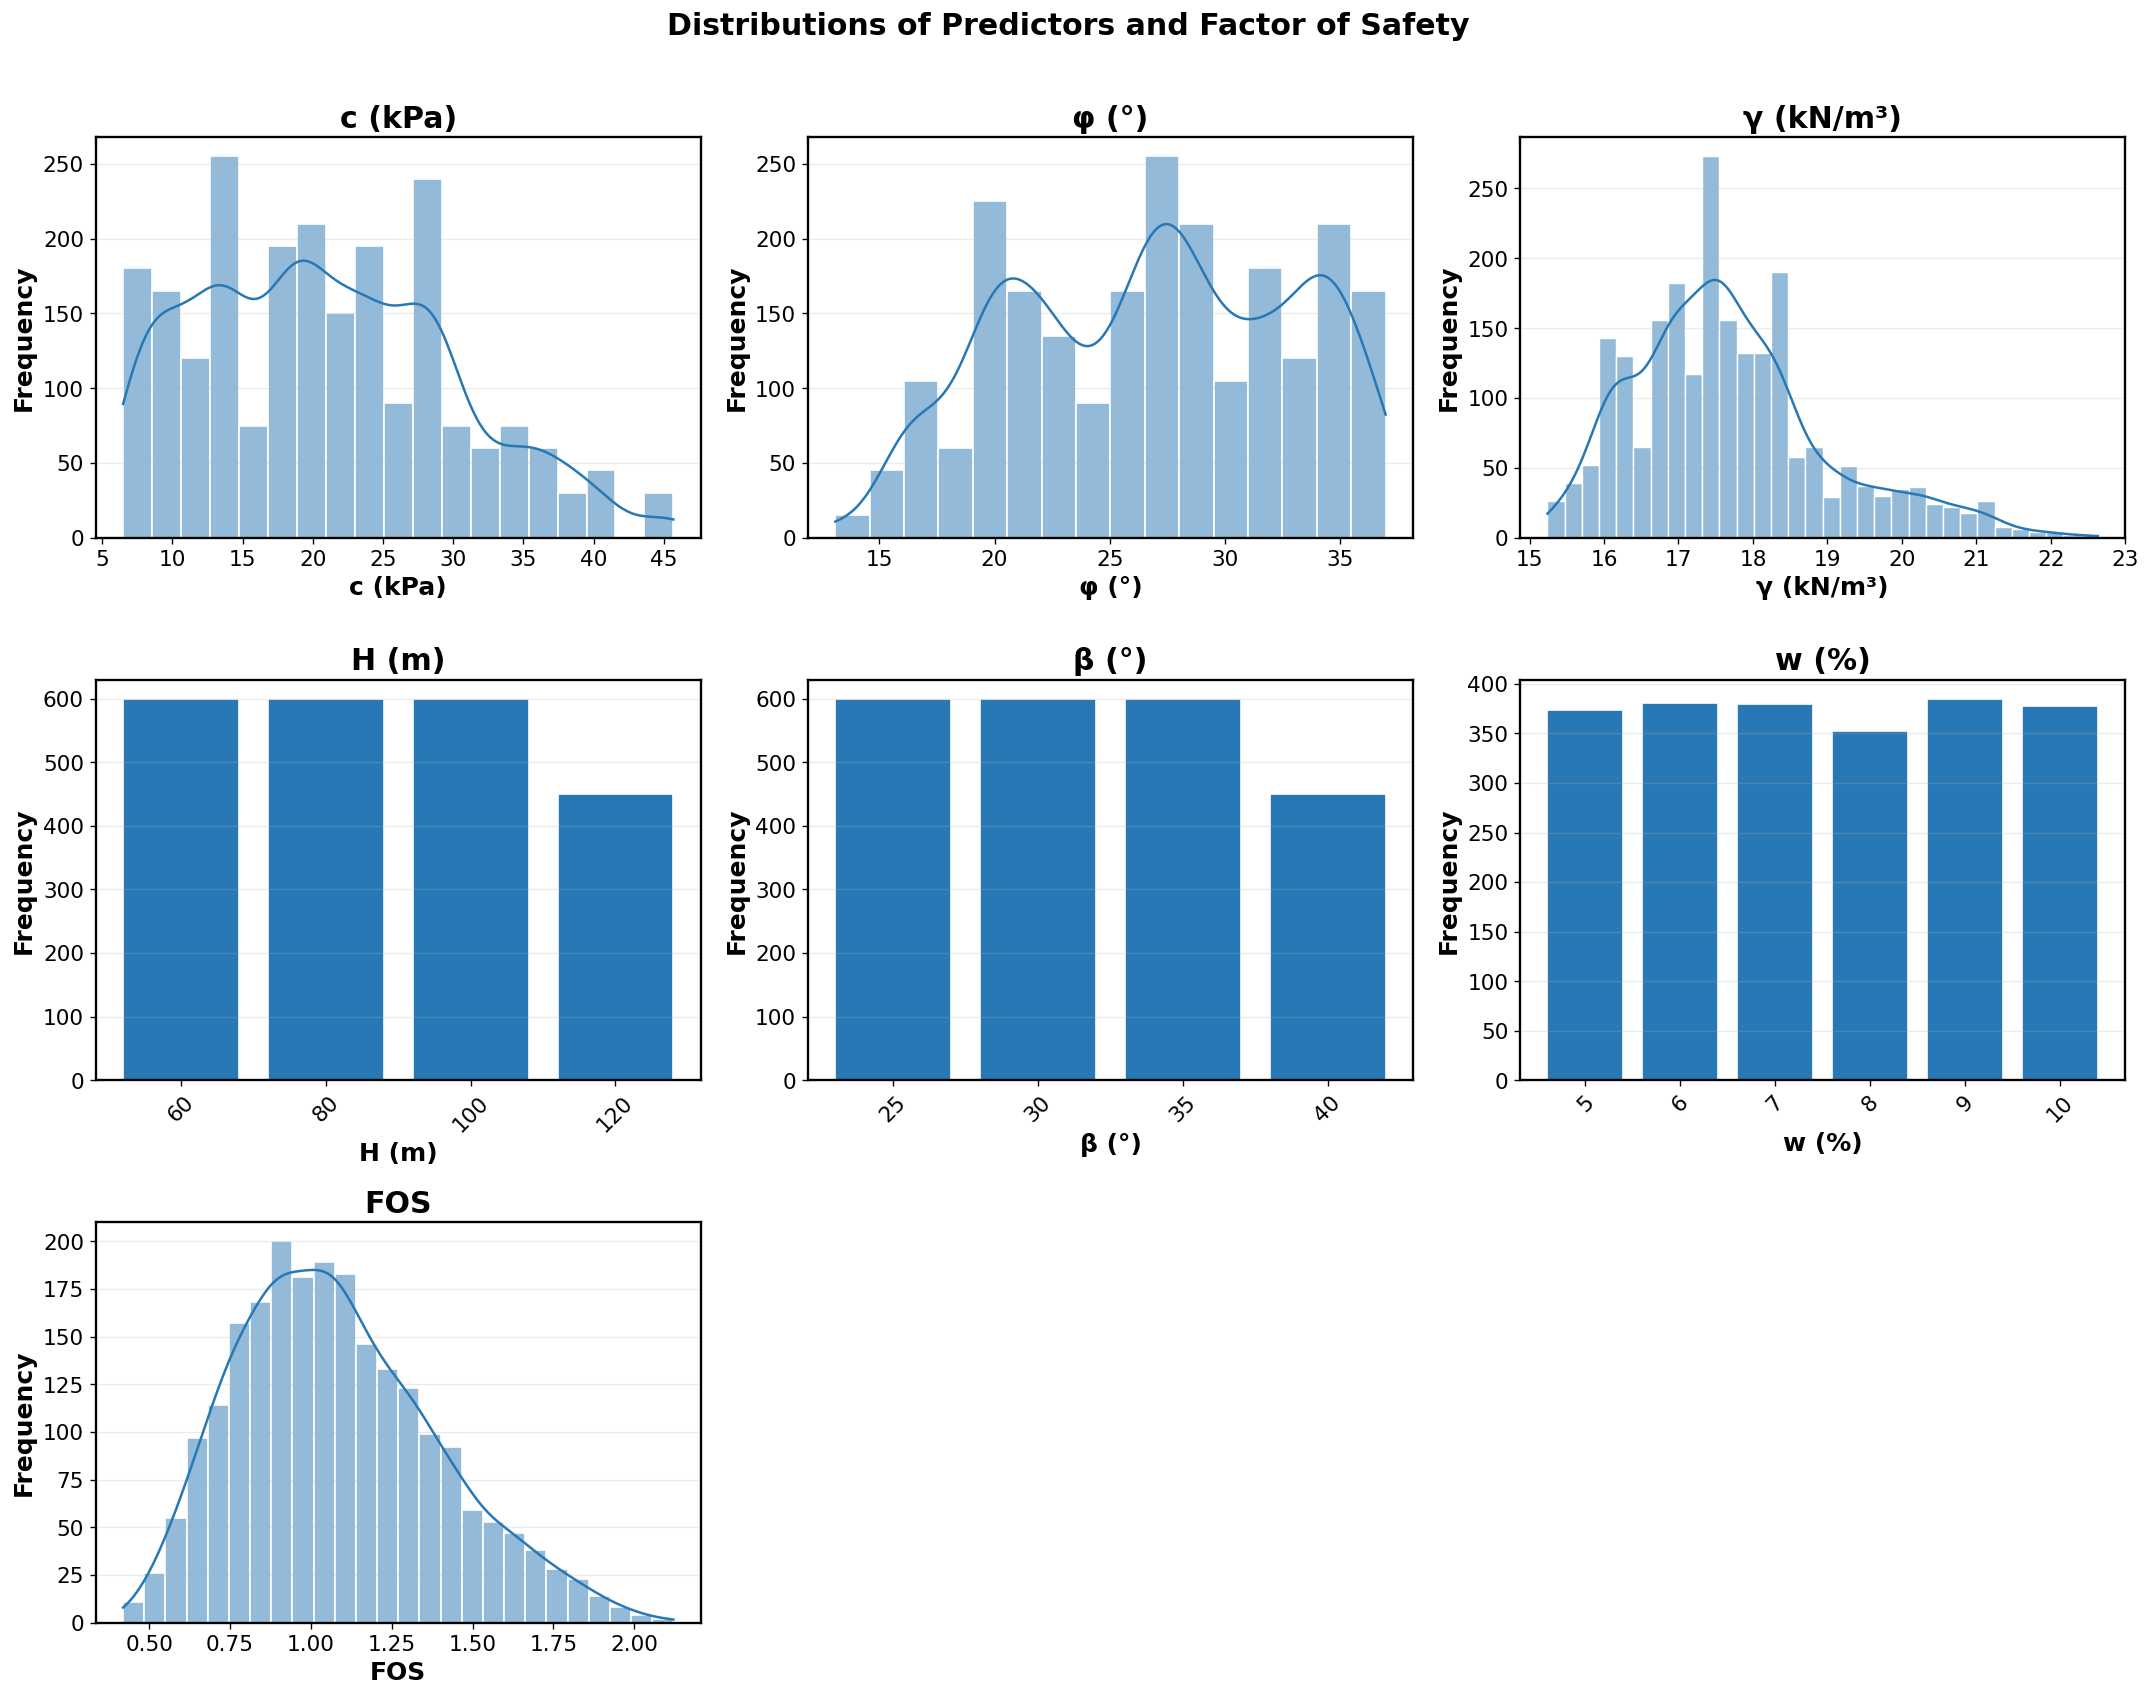

In [11]:
plot_columns = [*FEATURES, TARGET]
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.ravel()

DISCRETE_PREDICTORS = {"H", "beta", "w"}
for index, column in enumerate(plot_columns):
    if column in DISCRETE_PREDICTORS:
        counts = df[column].value_counts().sort_index()
        axes[index].bar(counts.index.astype(str), counts.values, color="#2878B5", edgecolor="white")
        axes[index].tick_params(axis="x", rotation=45)
    else:
        sns.histplot(df[column], kde=True, color="#2878B5", edgecolor="white", ax=axes[index])
    axes[index].set_title(DISPLAY_LABELS[column])
    axes[index].set_xlabel(DISPLAY_LABELS[column])
    axes[index].set_ylabel("Frequency")
    axes[index].grid(axis="y", alpha=0.25)

for axis in axes[len(plot_columns):]:
    axis.axis("off")

fig.suptitle("Distributions of Predictors and Factor of Safety", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["eda"], "Figure_01_Distributions")
plt.show()
plt.close(fig)

### 3.2 Pearson correlation matrix

The lower triangle retains signed Pearson coefficients and uses shades of blue.

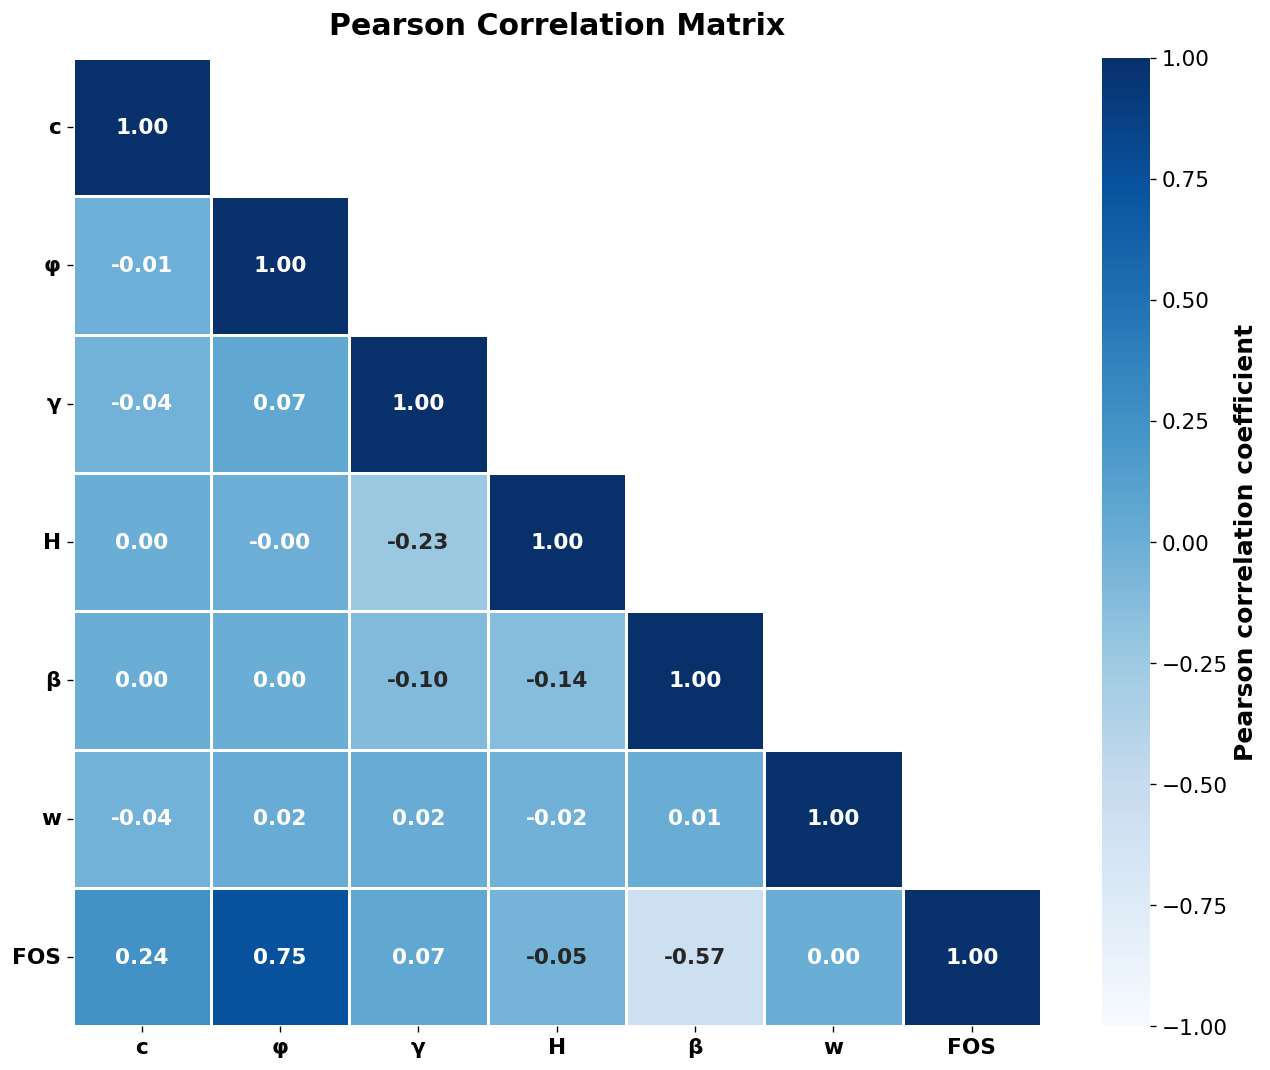

,Variable,c,φ,γ,H,β,w,FOS
0,c,1.0000,-0.0094,-0.0370,0.0000,0.0000,-0.0385,0.2429
1,φ,-0.0094,1.0000,0.0662,-0.0000,0.0000,0.0226,0.7468
2,γ,-0.0370,0.0662,1.0000,-0.2317,-0.1030,0.0194,0.0684
3,H,0.0000,-0.0000,-0.2317,1.0000,-0.1364,-0.0244,-0.0519
4,β,0.0000,0.0000,-0.1030,-0.1364,1.0000,0.0135,-0.5722
5,w,-0.0385,0.0226,0.0194,-0.0244,0.0135,1.0000,0.0039
6,FOS,0.2429,0.7468,0.0684,-0.0519,-0.5722,0.0039,1.0000


In [12]:
corr_data = df[[*FEATURES, TARGET]].rename(columns={**SYMBOL_MAP, TARGET: "FOS"})
corr_matrix = corr_data.corr(method="pearson")
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="Blues",
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": FONT_TICK, "fontweight": "bold"},
    linewidths=0.8,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Pearson correlation coefficient"},
    ax=ax,
)
ax.set_title("Pearson Correlation Matrix", pad=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontweight="bold")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontweight="bold")
ax.collections[0].colorbar.ax.tick_params(labelsize=FONT_TICK)
ax.collections[0].colorbar.set_label("Pearson correlation coefficient", fontsize=FONT_LABEL, fontweight="bold")
fig.tight_layout()
save_figure(fig, DIRS["eda"], "Figure_02_Pearson_Correlation")
plt.show()
plt.close(fig)

show_table(corr_matrix.reset_index().rename(columns={"index": "Variable"}), caption="Signed Pearson correlation coefficients")
corr_matrix.to_csv(DIRS["tables"] / "Table_Pearson_Correlation.csv")

### 3.3 FOS response across dump height and slope angle

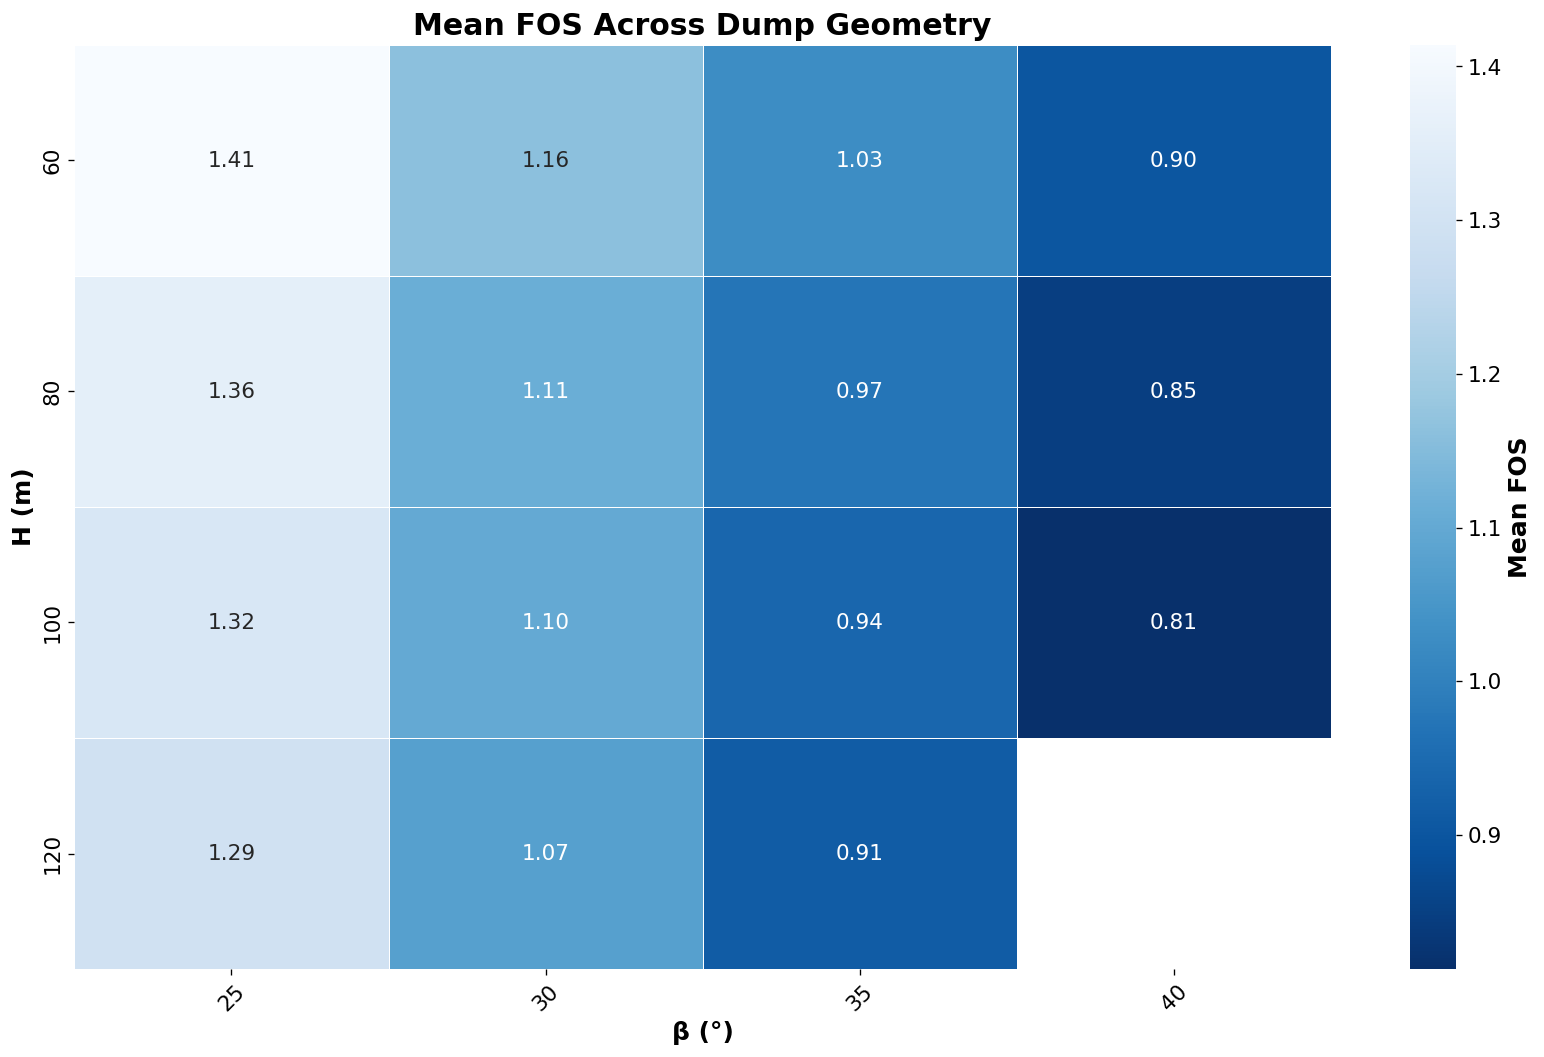

In [13]:
height_values = df["H"].nunique()
angle_values = df["beta"].nunique()

if height_values <= 25 and angle_values <= 25:
    response_table = df.pivot_table(index="H", columns="beta", values=TARGET, aggfunc="mean")
    y_label, x_label = "H (m)", "β (°)"
else:
    temp = df.copy()
    temp["H_bin"] = pd.qcut(temp["H"], q=min(10, height_values), duplicates="drop")
    temp["beta_bin"] = pd.qcut(temp["beta"], q=min(10, angle_values), duplicates="drop")
    response_table = temp.pivot_table(index="H_bin", columns="beta_bin", values=TARGET, aggfunc="mean", observed=False)
    y_label, x_label = "H quantile interval", "β quantile interval"

fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(
    response_table,
    cmap="Blues_r",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": FONT_TICK},
    linewidths=0.5,
    cbar_kws={"label": "Mean FOS"},
    ax=ax,
)
ax.set_title("Mean FOS Across Dump Geometry")
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
ax.tick_params(axis="x", rotation=45)
ax.collections[0].colorbar.ax.tick_params(labelsize=FONT_TICK)
ax.collections[0].colorbar.set_label("Mean FOS", fontsize=FONT_LABEL, fontweight="bold")
fig.tight_layout()
save_figure(fig, DIRS["eda"], "Figure_03_FOS_Height_Slope_Angle")
plt.show()
plt.close(fig)

response_table.to_csv(DIRS["tables"] / "Table_FOS_Height_Slope_Angle.csv")

## 4. Group-Aware Data Partitioning

### 4.1 Create the 70:15:15 development–calibration–test split

Material-strength profiles are defined exclusively by unique $(c,\phi)$ pairs. Exactly 105, 22 and 23 complete profiles are assigned to development, calibration and locked testing. Candidate allocations are scored using predictor information only; held-out profile outcomes are never used to select a favourable split.

In [14]:
def profile_balance_score(profile_table, assignments):
    # Balance c and phi without consulting FOS or any model result.
    z = profile_table[["c", "phi"]].apply(lambda x: (x - x.mean()) / max(x.std(ddof=0), 1e-12))
    global_mean = z.mean().to_numpy()
    global_sd = z.std(ddof=0).to_numpy()
    score = 0.0
    for subset in ("Development", "Calibration", "Test"):
        selected = z.loc[assignments == subset]
        score += np.abs(selected.mean().to_numpy() - global_mean).mean()
        score += 0.5 * np.abs(selected.std(ddof=0).to_numpy() - global_sd).mean()
    return float(score)

def create_group_split(data, attempts=2000, seed=SEED):
    profile_table = data.groupby("profile_group", as_index=False)[["c", "phi"]].first()
    n_profiles = len(profile_table)
    if n_profiles != 150:
        raise ValueError(f"Expected 150 unique c–phi profiles, found {n_profiles}. Verify the dataset before continuing.")
    best = None
    for offset in range(attempts):
        rng = np.random.default_rng(seed + offset)
        order = rng.permutation(n_profiles)
        assignments = pd.Series(index=profile_table.index, dtype="object")
        assignments.iloc[order[:105]] = "Development"
        assignments.iloc[order[105:127]] = "Calibration"
        assignments.iloc[order[127:]] = "Test"
        score = profile_balance_score(profile_table, assignments)
        if best is None or score < best[0]:
            best = (score, dict(zip(profile_table["profile_group"], assignments)))
    return best

split_path = DIRS["splits"] / "PGUC_MLP_Group_Aware_Split_Assignments.csv"
split_metadata_path = DIRS["splits"] / "PGUC_MLP_Group_Aware_Split_Metadata.json"

if split_path.exists() and not FORCE_RETRAIN:
    if not split_metadata_path.exists():
        raise RuntimeError("Split metadata is missing. Set FORCE_RETRAIN=True to recreate the split safely.")
    saved_split_metadata = json.loads(split_metadata_path.read_text(encoding="utf-8"))
    if saved_split_metadata.get("data_fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError("The dataset has changed since the split was created. Set FORCE_RETRAIN=True.")
    saved_split = pd.read_csv(split_path)
    if set(saved_split["row_id"]) != set(df["row_id"]):
        raise RuntimeError("Saved split assignments do not match the current cleaned dataset.")
    df = df.drop(columns=["subset"], errors="ignore").merge(saved_split[["row_id", "subset"]], on="row_id", how="left")
else:
    score, profile_assignment = create_group_split(df)
    df["subset"] = df["profile_group"].map(profile_assignment)
    df[["row_id", "profile_group", "subset"]].to_csv(split_path, index=False)
    split_metadata_path.write_text(
        json.dumps({"data_fingerprint": DATA_FINGERPRINT, "seed": SEED}, indent=2),
        encoding="utf-8",
    )
    print(f"Selected split score: {score:.5f}")

development_df = df[df["subset"] == "Development"].copy().reset_index(drop=True)
calibration_df = df[df["subset"] == "Calibration"].copy().reset_index(drop=True)
test_df = df[df["subset"] == "Test"].copy().reset_index(drop=True)

df.to_csv(DIRS["processed"] / "PGUC_MLP_Cleaned_Dataset_with_Splits.csv", index=False)
df.to_excel(DIRS["processed"] / "PGUC_MLP_Cleaned_Dataset_with_Splits.xlsx", index=False)

### 4.2 Verify split integrity and display the split table

In [15]:
subset_frames = {
    "Development": development_df,
    "Calibration": calibration_df,
    "Test": test_df,
}

group_sets = {name: set(frame["profile_group"]) for name, frame in subset_frames.items()}
assert group_sets["Development"].isdisjoint(group_sets["Calibration"])
assert group_sets["Development"].isdisjoint(group_sets["Test"])
assert group_sets["Calibration"].isdisjoint(group_sets["Test"])
assert [len(group_sets[name]) for name in ("Development", "Calibration", "Test")] == [105, 22, 23]

split_summary = pd.DataFrame([
    {
        "Subset": name,
        "Observations": len(frame),
        "Proportion (%)": 100 * len(frame) / len(df),
        "Material profiles": frame["profile_group"].nunique(),
        "Mean FOS": frame[TARGET].mean(),
        "SD FOS": frame[TARGET].std(),
        "Minimum FOS": frame[TARGET].min(),
        "Maximum FOS": frame[TARGET].max(),
        "FOS < 1.0 (%)": 100 * (frame[TARGET] < 1.0).mean(),
    }
    for name, frame in subset_frames.items()
])

show_table(split_summary, caption="Group-aware dataset partition")
split_summary.to_csv(DIRS["tables"] / "Table_Group_Aware_Data_Partition.csv", index=False)
split_summary.to_excel(DIRS["tables"] / "Table_Group_Aware_Data_Partition.xlsx", index=False)

,Subset,Observations,Proportion (%),Material profiles,Mean FOS,SD FOS,Minimum FOS,Maximum FOS,FOS < 1.0 (%)
0,Development,1575,70.0000,105,1.0800,0.3065,0.4190,2.1210,44.0635
1,Calibration,330,14.6667,22,1.0846,0.3315,0.4323,2.1143,43.6364
2,Test,345,15.3333,23,1.0955,0.3234,0.5289,2.0272,41.4493


### 4.3 Visualise profile-independent partitioning

This is a main-manuscript figure because it shows the actual unit of generalisation: unseen $(c,\phi)$ combinations.


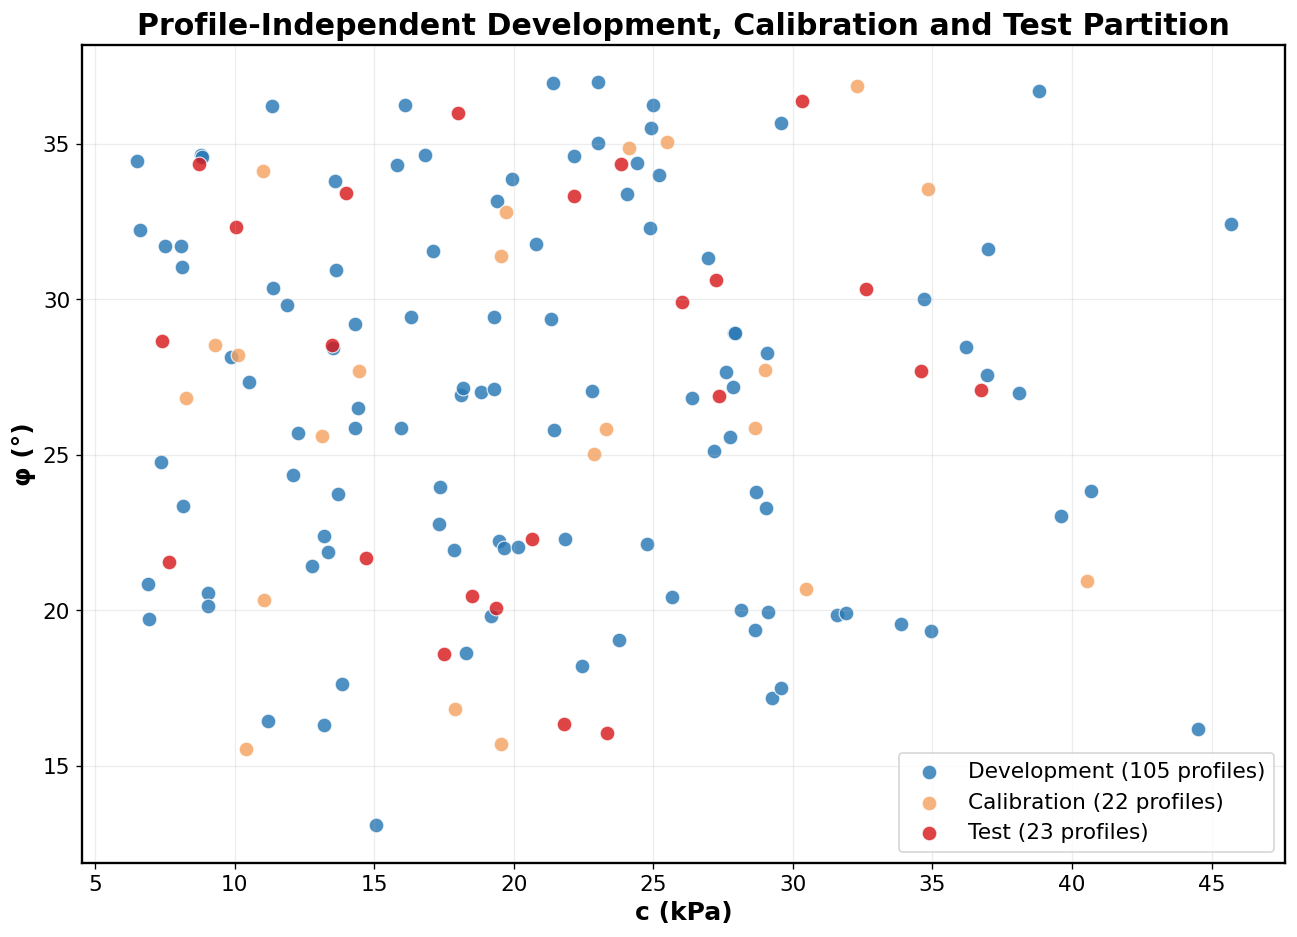

In [16]:
profile_partition = (
    df.groupby("profile_group", as_index=False)
    .agg(c=("c", "first"), phi=("phi", "first"), subset=("subset", "first"))
)

subset_colours = {
    "Development": "#2878B5",
    "Calibration": "#F4A261",
    "Test": "#D7191C",
}

fig, ax = plt.subplots(figsize=(11, 8))
for subset_name in ("Development", "Calibration", "Test"):
    part = profile_partition[profile_partition["subset"] == subset_name]
    ax.scatter(
        part["c"], part["phi"], s=78, alpha=0.82,
        color=subset_colours[subset_name], edgecolor="white", linewidth=0.7,
        label=f"{subset_name} ({len(part)} profiles)",
    )

ax.set_title("Profile-Independent Development, Calibration and Test Partition")
ax.set_xlabel("c (kPa)")
ax.set_ylabel("φ (°)")
ax.grid(alpha=0.22)
ax.legend(frameon=True)
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_02_Profile_Independent_Partition")
plt.show()
plt.close(fig)

profile_partition.to_csv(DIRS["splits"] / "PGUC_MLP_Profile_Partition.csv", index=False)
with pd.ExcelWriter(DIRS["tables"] / "Table_Main_Scenario_and_Profile_Partition.xlsx") as writer:
    scenario_audit.to_excel(writer, sheet_name="Scenario design", index=False)
    split_summary.to_excel(writer, sheet_name="Profile partition", index=False)
    profile_partition.to_excel(writer, sheet_name="c-phi assignments", index=False)


## 5. PGUC-MLP Architecture

### 5.1 Mechanics-informed preprocessing and network definition

The network receives the six raw predictors and internally augments them with $c/(\gamma H)$, $\tan\phi$ and $\tan\beta$. Explanations remain in the original six-predictor space. The physics-guided homoscedastic ensemble is the headline mean model; heteroscedastic variants remain controlled ablations.


In [17]:
class MechanicsProcessor:
    def fit(self, x):
        x = np.asarray(x, dtype=np.float64)
        self.raw_scaler = StandardScaler().fit(x)
        self.derived_scaler = StandardScaler().fit(self._derived_numpy(x))
        self.bounds = np.column_stack([x.min(axis=0), x.max(axis=0)])
        return self

    @staticmethod
    def _derived_numpy(x):
        c, phi, gamma, height, beta, moisture = x.T
        pi_c = c / np.maximum(gamma * height, 1e-12)
        return np.column_stack([pi_c, np.tan(np.deg2rad(phi)), np.tan(np.deg2rad(beta))])

    def transform(self, x):
        x = np.asarray(x, dtype=np.float64)
        raw = self.raw_scaler.transform(x)
        derived = self.derived_scaler.transform(self._derived_numpy(x))
        return np.column_stack([raw, derived]).astype(np.float32)

    def transform_torch(self, x):
        mean = torch.as_tensor(self.raw_scaler.mean_, dtype=x.dtype, device=x.device)
        scale = torch.as_tensor(self.raw_scaler.scale_, dtype=x.dtype, device=x.device)
        raw = (x - mean) / scale
        pi_c = x[:, 0] / torch.clamp(x[:, 2] * x[:, 3], min=1e-12)
        derived = torch.stack([
            pi_c,
            torch.tan(torch.deg2rad(x[:, 1])),
            torch.tan(torch.deg2rad(x[:, 4])),
        ], dim=1)
        d_mean = torch.as_tensor(self.derived_scaler.mean_, dtype=x.dtype, device=x.device)
        d_scale = torch.as_tensor(self.derived_scaler.scale_, dtype=x.dtype, device=x.device)
        return torch.cat([raw, (derived - d_mean) / d_scale], dim=1)


class FOSNetwork(nn.Module):
    def __init__(self, input_dim, width, n_layers, dropout, activation, heteroscedastic):
        super().__init__()
        activation_map = {"ReLU": nn.ReLU, "GELU": nn.GELU, "SiLU": nn.SiLU}
        blocks = []
        previous = input_dim
        for _ in range(n_layers):
            blocks.extend([
                nn.Linear(previous, width),
                nn.BatchNorm1d(width),
                activation_map[activation](),
                nn.Dropout(dropout),
            ])
            previous = width
        self.backbone = nn.Sequential(*blocks)
        self.output = nn.Linear(previous, 2 if heteroscedastic else 1)
        self.heteroscedastic = heteroscedastic

    def forward(self, x):
        output = self.output(self.backbone(x))
        if self.heteroscedastic:
            mean = output[:, 0]
            log_variance = torch.clamp(output[:, 1], min=-10.0, max=5.0)
            return mean, log_variance
        return output[:, 0], None


CONFIGURATIONS = {
    "standard_mlp": {"label": "Baseline MLP", "physics": False, "heteroscedastic": False, "members": 5},
    "physics_only": {"label": "Physics-Guided Homoscedastic MLP", "physics": True, "heteroscedastic": False, "members": 5},
    "uncertainty_only": {"label": "Heteroscedastic MLP", "physics": False, "heteroscedastic": True, "members": 5},
    "full_pguc_mlp": {"label": "Physics-Guided Heteroscedastic MLP", "physics": True, "heteroscedastic": True, "members": 5},
}

configuration_table = pd.DataFrame([
    {
        "Configuration": specification["label"],
        "Physics guidance": "Yes" if specification["physics"] else "No",
        "Heteroscedastic ensemble": "Yes" if specification["heteroscedastic"] else "No",
        "Profile-wise conformal calibration": "Headline" if key == HEADLINE_MODEL_KEY else "No",
        "Final members": specification["members"],
    }
    for key, specification in CONFIGURATIONS.items()
])
show_table(configuration_table, precision=0, caption="Controlled ablation configurations")
configuration_table.to_excel(
    DIRS["tables"] / "Table_Model_Configurations.xlsx", index=False
)


,Configuration,Physics guidance,Heteroscedastic ensemble,Profile-wise conformal calibration,Final members
0,Baseline MLP,No,No,No,5
1,Physics-Guided Homoscedastic MLP,Yes,No,Headline,5
2,Heteroscedastic MLP,No,Yes,No,5
3,Physics-Guided Heteroscedastic MLP,Yes,Yes,No,5


### 5.2 Publication workflow schematic

The schematic is generated from code so that the main paper and notebook describe the same analysis sequence.


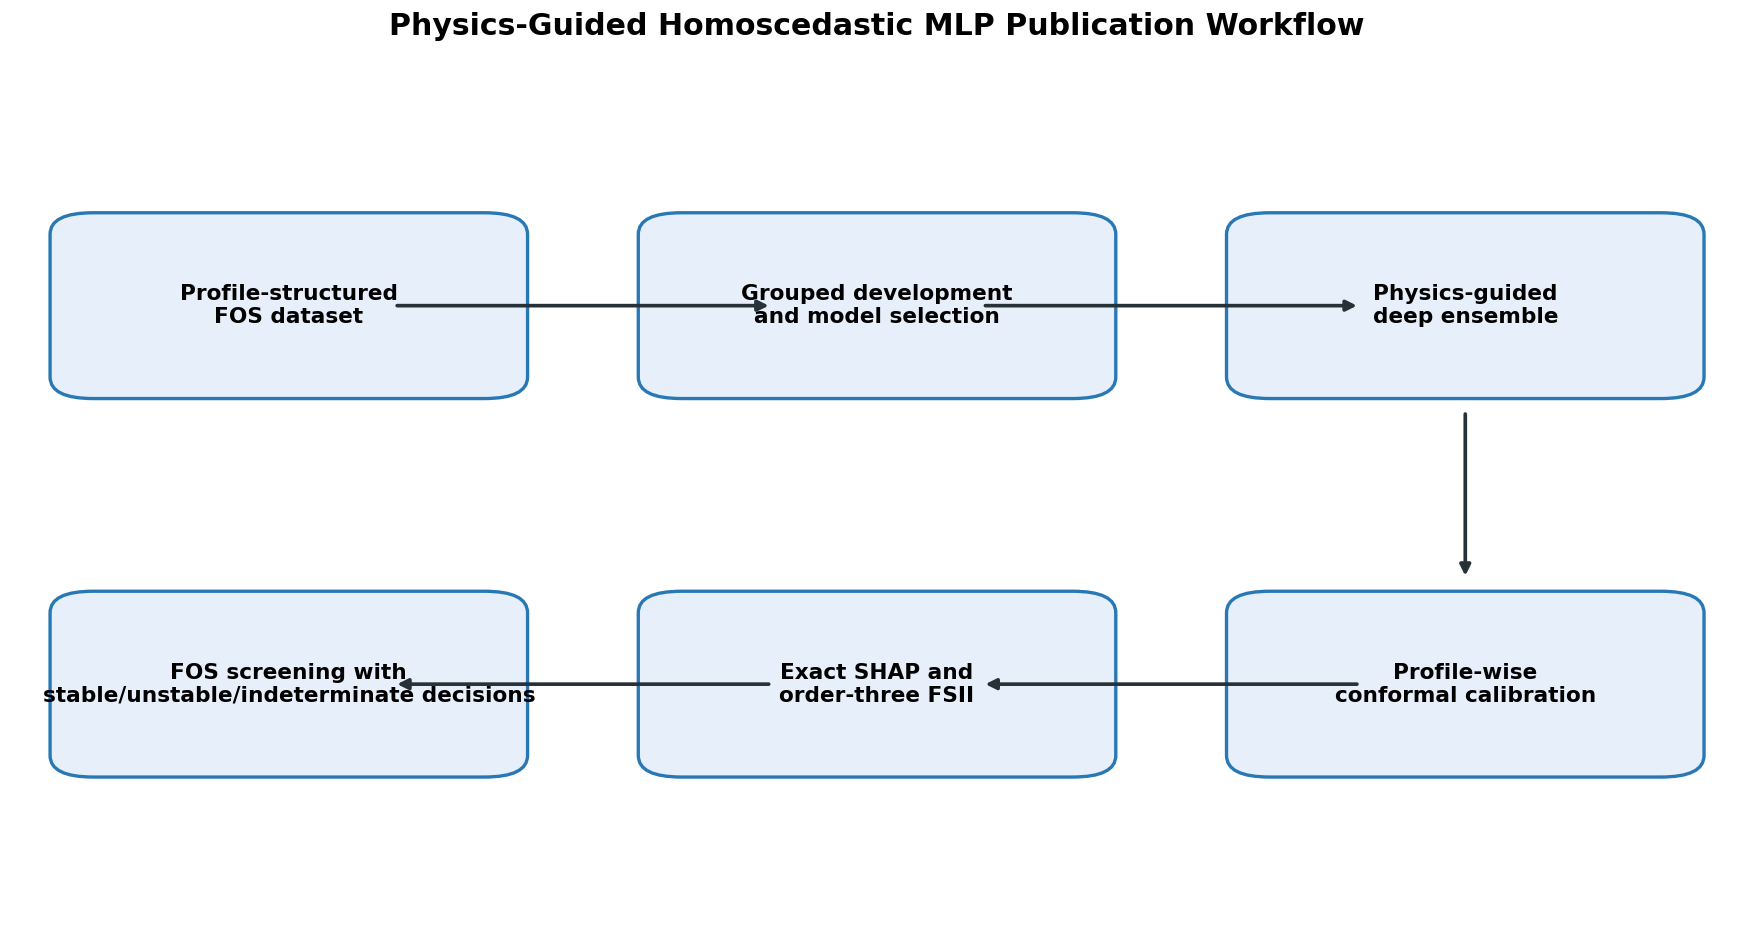

In [18]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 8))
workflow_nodes = [
    (0.16, 0.72, "Profile-structured\nFOS dataset"),
    (0.50, 0.72, "Grouped development\nand model selection"),
    (0.84, 0.72, "Physics-guided\ndeep ensemble"),
    (0.84, 0.28, "Profile-wise\nconformal calibration"),
    (0.50, 0.28, "Exact SHAP and\norder-three FSII"),
    (0.16, 0.28, "FOS screening with\nstable/unstable/indeterminate decisions"),
]

patches = []
for x, y, label in workflow_nodes:
    patch = FancyBboxPatch(
        (x - 0.12, y - 0.09), 0.24, 0.18,
        boxstyle="round,pad=0.018,rounding_size=0.025",
        facecolor="#E7F0FA", edgecolor="#2878B5", linewidth=2.0,
        transform=ax.transAxes,
    )
    ax.add_patch(patch)
    patches.append(patch)
    ax.text(x, y, label, transform=ax.transAxes, ha="center", va="center", fontweight="bold")

for start, end in [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]:
    start_x, start_y, _ = workflow_nodes[start]
    end_x, end_y, _ = workflow_nodes[end]
    ax.annotate(
        "", xy=(end_x, end_y), xytext=(start_x, start_y),
        xycoords=ax.transAxes, textcoords=ax.transAxes,
        arrowprops={"arrowstyle": "-|>", "lw": 2.2, "color": "#263238", "shrinkA": 65, "shrinkB": 65},
    )

ax.set_title("Physics-Guided Homoscedastic MLP Publication Workflow", pad=18)
ax.axis("off")
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_01_PGUC_MLP_Workflow")
plt.show()
plt.close(fig)


### 5.3 Physics-guided loss, training and prediction functions

In [19]:
def build_model(params, heteroscedastic):
    return FOSNetwork(
        input_dim=9,
        width=int(params["width"]),
        n_layers=int(params["n_layers"]),
        dropout=float(params["dropout"]),
        activation=params["activation"],
        heteroscedastic=heteroscedastic,
    ).to(DEVICE)

def physics_penalty(model, raw_batch, processor, fraction_min=0.02, fraction_max=0.10):
    was_training = model.training
    model.eval()
    base_mean, _ = model(processor.transform_torch(raw_batch))
    bounds = torch.as_tensor(processor.bounds, dtype=raw_batch.dtype, device=raw_batch.device)
    penalties = []
    directions = {0: 1.0, 1: 1.0, 2: -1.0, 3: -1.0, 4: -1.0}

    for feature_index, direction in directions.items():
        feature_range = bounds[feature_index, 1] - bounds[feature_index, 0]
        fraction = fraction_min + torch.rand(raw_batch.size(0), device=raw_batch.device) * (fraction_max - fraction_min)
        counterfactual = raw_batch.clone()
        counterfactual[:, feature_index] = torch.minimum(
            raw_batch[:, feature_index] + fraction * feature_range,
            bounds[feature_index, 1],
        )
        valid = counterfactual[:, feature_index] > raw_batch[:, feature_index] + 1e-9
        if valid.any():
            changed_mean, _ = model(processor.transform_torch(counterfactual))
            signed_change = direction * (changed_mean - base_mean)
            penalties.append(torch.relu(-signed_change[valid]).mean())

    penalty = torch.stack(penalties).mean() if penalties else torch.tensor(0.0, device=raw_batch.device)
    if was_training:
        model.train()
    return penalty

def point_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    residual = predicted - actual
    return {
        "R²": r2_score(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "MAPE (%)": 100 * np.mean(np.abs(residual / np.maximum(np.abs(actual), 1e-12))),
        "Pearson r": pearsonr(actual, predicted)[0],
        "Bias": residual.mean(),
    }

def train_network(
    x_train,
    y_train,
    processor,
    params,
    physics,
    heteroscedastic,
    seed,
    x_valid=None,
    y_valid=None,
    max_epochs=400,
    patience=PATIENCE,
    fixed_epochs=None,
):
    set_seed(seed)
    y_mean = float(np.mean(y_train))
    y_scale = float(np.std(y_train, ddof=0))
    y_scale = max(y_scale, 1e-12)
    y_standard = ((np.asarray(y_train) - y_mean) / y_scale).astype(np.float32)

    dataset = TensorDataset(
        torch.tensor(np.asarray(x_train), dtype=torch.float32),
        torch.tensor(y_standard, dtype=torch.float32),
    )
    generator = torch.Generator().manual_seed(seed)
    actual_batch_size = min(int(params["batch_size"]), len(dataset))
    loader = DataLoader(
        dataset,
        batch_size=actual_batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator,
        drop_last=(len(dataset) % actual_batch_size == 1),
    )

    model = build_model(params, heteroscedastic)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=float(params["learning_rate"]),
        weight_decay=float(params["weight_decay"]),
    )

    epochs = int(fixed_epochs if fixed_epochs is not None else max_epochs)
    best_state, best_rmse, best_epoch, wait = None, np.inf, 0, 0
    history = []

    for epoch in range(1, epochs + 1):
        model.train()
        epoch_losses = []

        for raw_batch, target_batch in loader:
            raw_batch = raw_batch.to(DEVICE)
            target_batch = target_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            mean, log_variance = model(processor.transform_torch(raw_batch))

            if heteroscedastic:
                data_loss = 0.5 * (log_variance + (target_batch - mean).pow(2) * torch.exp(-log_variance)).mean()
            else:
                data_loss = nn.functional.mse_loss(mean, target_batch)

            physics_loss = physics_penalty(model, raw_batch, processor) if physics else torch.tensor(0.0, device=DEVICE)
            loss = data_loss + float(params["physics_lambda"]) * physics_loss
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            epoch_losses.append(float(loss.detach().cpu()))

        record = {"epoch": epoch, "training_loss": np.mean(epoch_losses)}

        if x_valid is not None:
            prediction = predict_single(model, processor, x_valid, y_mean, y_scale)["mean"]
            validation_rmse = np.sqrt(mean_squared_error(y_valid, prediction))
            record["validation_RMSE"] = validation_rmse
            if validation_rmse < best_rmse - 1e-7:
                best_rmse = validation_rmse
                best_epoch = epoch
                wait = 0
                best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
            else:
                wait += 1
            if wait >= patience:
                history.append(record)
                break

        history.append(record)

    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs

    return model, pd.DataFrame(history), {"y_mean": y_mean, "y_scale": y_scale, "best_epoch": best_epoch}

@torch.no_grad()
def predict_single(model, processor, x, y_mean, y_scale, batch_size=4096):
    model.eval()
    x = np.asarray(x, dtype=np.float32)
    means, variances = [], []
    for start in range(0, len(x), batch_size):
        raw = torch.tensor(x[start:start + batch_size], dtype=torch.float32, device=DEVICE)
        mean_standard, log_variance = model(processor.transform_torch(raw))
        means.append(mean_standard.cpu().numpy() * y_scale + y_mean)
        if log_variance is not None:
            variances.append(np.exp(log_variance.cpu().numpy()) * (y_scale ** 2))
    result = {"mean": np.concatenate(means)}
    result["variance"] = np.concatenate(variances) if variances else np.zeros(len(x))
    return result

def predict_configuration(models, processor, x, y_mean, y_scale, heteroscedastic):
    member_results = [predict_single(model, processor, x, y_mean, y_scale) for model in models]
    means = np.vstack([result["mean"] for result in member_results])
    mean_prediction = means.mean(axis=0)
    epistemic_variance = means.var(axis=0, ddof=0) if len(models) > 1 else np.zeros(means.shape[1])
    if heteroscedastic:
        aleatoric_variance = np.vstack([result["variance"] for result in member_results]).mean(axis=0)
    else:
        aleatoric_variance = np.zeros(means.shape[1])
    total_variance = np.maximum(aleatoric_variance + epistemic_variance, 0.0)
    return {
        "mean": mean_prediction,
        "member_means": means,
        "aleatoric_variance": aleatoric_variance,
        "epistemic_variance": epistemic_variance,
        "total_sigma": np.sqrt(total_variance),
    }

## 6. Hyperparameter Optimisation and Grouped Cross-Validation

### 6.1 Define the headline-model Optuna objective

Optuna uses grouped fivefold cross-validation inside the development subset only. The tuned target is the physics-guided **homoscedastic** member that supplies the final ensemble mean. This prevents the underperforming joint heteroscedastic objective from determining the headline architecture.


In [20]:
X_DEVELOPMENT = development_df[FEATURES].to_numpy(dtype=np.float32)
Y_DEVELOPMENT = development_df[TARGET].to_numpy(dtype=np.float32)
GROUPS_DEVELOPMENT = development_df["profile_group"].to_numpy()

def trial_parameters(trial):
    return {
        "width": trial.suggest_categorical("width", [64, 96, 128, 160, 192]),
        "n_layers": trial.suggest_int("n_layers", 2, 4),
        "dropout": trial.suggest_float("dropout", 0.00, 0.30, step=0.05),
        "activation": trial.suggest_categorical("activation", ["ReLU", "GELU", "SiLU"]),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 3e-3, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-7, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128, 256]),
        "physics_lambda": trial.suggest_float("physics_lambda", 1e-2, 1.0, log=True),
    }

def optuna_objective(trial):
    params = trial_parameters(trial)
    group_cv = GroupKFold(n_splits=N_SPLITS)
    fold_rmse = []

    for fold, (train_idx, valid_idx) in enumerate(
        group_cv.split(X_DEVELOPMENT, Y_DEVELOPMENT, GROUPS_DEVELOPMENT), start=1
    ):
        processor = MechanicsProcessor().fit(X_DEVELOPMENT[train_idx])
        model, history, state = train_network(
            X_DEVELOPMENT[train_idx],
            Y_DEVELOPMENT[train_idx],
            processor,
            params,
            physics=True,
            heteroscedastic=False,
            seed=SEED + fold,
            x_valid=X_DEVELOPMENT[valid_idx],
            y_valid=Y_DEVELOPMENT[valid_idx],
            max_epochs=MAX_EPOCHS_TUNE,
            patience=PATIENCE,
        )
        prediction = predict_single(
            model, processor, X_DEVELOPMENT[valid_idx], state["y_mean"], state["y_scale"]
        )["mean"]
        fold_rmse.append(np.sqrt(mean_squared_error(Y_DEVELOPMENT[valid_idx], prediction)))
        trial.report(float(np.mean(fold_rmse)), step=fold)

        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(fold_rmse))

### 6.2 Run or resume hyperparameter optimisation

In [21]:
study_path = DIRS["models"] / "Optuna_Headline_PG_MLP_Study.pkl"
study_metadata_path = DIRS["models"] / "Optuna_Headline_PG_MLP_Study_Metadata.json"

if study_path.exists() and not FORCE_RETUNE:
    if not study_metadata_path.exists():
        raise RuntimeError("Optuna metadata is missing. Set FORCE_RETUNE=True to tune safely.")
    study_metadata = json.loads(study_metadata_path.read_text(encoding="utf-8"))
    if study_metadata.get("data_fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError("The dataset has changed since tuning. Set FORCE_RETUNE=True.")
    if study_metadata.get("objective_model") != HEADLINE_MODEL_KEY:
        raise RuntimeError("Saved optimisation targeted another model. Set FORCE_RETUNE=True.")
    study = joblib.load(study_path)
else:
    sampler = optuna.samplers.TPESampler(seed=SEED, multivariate=True)
    pruner = optuna.pruners.MedianPruner(n_startup_trials=8, n_warmup_steps=2)
    study = optuna.create_study(direction="minimize", sampler=sampler, pruner=pruner)

completed_trials = sum(
    trial.state == optuna.trial.TrialState.COMPLETE for trial in study.trials
)
remaining_complete_trials = max(0, N_COMPLETE_TRIALS_TARGET - completed_trials)

if remaining_complete_trials > 0:
    # Pruned attempts do not count towards the target number of completed trials.
    study.optimize(optuna_objective, n_trials=remaining_complete_trials, show_progress_bar=True)
    while sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials) < N_COMPLETE_TRIALS_TARGET:
        study.optimize(optuna_objective, n_trials=1, show_progress_bar=False)
    joblib.dump(study, study_path)

completed_trials = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
pruned_trials = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)

study_metadata = {
    "data_fingerprint": DATA_FINGERPRINT,
    "objective_model": HEADLINE_MODEL_KEY,
    "completed_trial_target": N_COMPLETE_TRIALS_TARGET,
    "completed_trials": completed_trials,
    "pruned_attempts": pruned_trials,
    "total_attempts": len(study.trials),
}
study_metadata_path.write_text(json.dumps(study_metadata, indent=2), encoding="utf-8")

BEST_PARAMS = study.best_params.copy()
trial_table = study.trials_dataframe()
trial_table.to_csv(DIRS["tables"] / "Table_Optuna_Trials.csv", index=False)

best_parameter_table = pd.DataFrame({
    "Hyperparameter": list(BEST_PARAMS.keys()),
    "Selected value": list(BEST_PARAMS.values()),
})

print(f"Best headline-model grouped-CV RMSE: {study.best_value:.6f}")
print(f"Completed trials: {completed_trials}; pruned attempts: {pruned_trials}; total attempts: {len(study.trials)}")
show_table(best_parameter_table, caption="Selected headline PGUC-MLP hyperparameters")
best_parameter_table.to_excel(DIRS["tables"] / "Table_Selected_Hyperparameters.xlsx", index=False)
with pd.ExcelWriter(DIRS["tables"] / "Table_Main_Model_Configurations_and_Hyperparameters.xlsx") as writer:
    configuration_table.to_excel(writer, sheet_name="Configurations", index=False)
    best_parameter_table.to_excel(writer, sheet_name="Headline hyperparameters", index=False)


Best headline-model grouped-CV RMSE: 0.005295
Completed trials: 40; pruned attempts: 35; total attempts: 75


,Hyperparameter,Selected value
0,width,128
1,n_layers,3
2,dropout,0.0000
3,activation,SiLU
4,learning_rate,0.0019
5,weight_decay,0.0006
6,batch_size,256
7,physics_lambda,0.0125


### 6.3 Display optimisation history

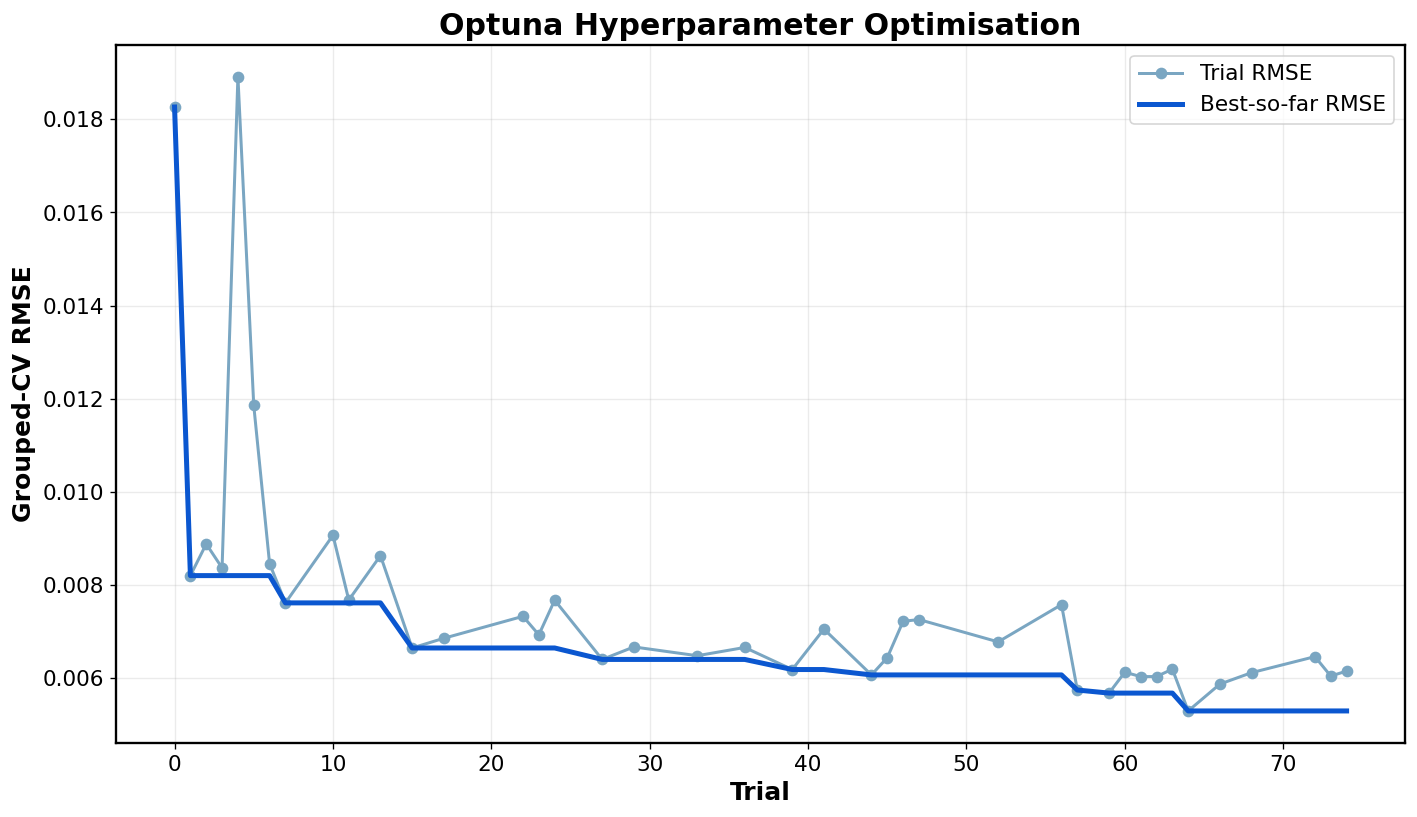

In [22]:
complete = trial_table[trial_table["state"] == "COMPLETE"].copy()
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(complete["number"], complete["value"], marker="o", linewidth=1.8, color="#7AA6C2", label="Trial RMSE")
ax.plot(complete["number"], complete["value"].cummin(), linewidth=3.0, color="#0B57D0", label="Best-so-far RMSE")
ax.set_title("Optuna Hyperparameter Optimisation")
ax.set_xlabel("Trial")
ax.set_ylabel("Grouped-CV RMSE")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_04_Optuna_Optimisation_History")
plt.show()
plt.close(fig)

### 6.4 Run grouped fivefold cross-validation for all configurations

In [23]:
cv_detail_path = DIRS["tables"] / "Table_Grouped_Fivefold_CV_Detailed.csv"

if cv_detail_path.exists() and not FORCE_RETRAIN:
    cv_detailed = pd.read_csv(cv_detail_path)
else:
    cv_rows = []
    group_cv = GroupKFold(n_splits=N_SPLITS)

    for configuration_key, specification in CONFIGURATIONS.items():
        print(f"Cross-validating: {specification['label']}")
        for fold, (train_idx, valid_idx) in enumerate(
            group_cv.split(X_DEVELOPMENT, Y_DEVELOPMENT, GROUPS_DEVELOPMENT), start=1
        ):
            processor = MechanicsProcessor().fit(X_DEVELOPMENT[train_idx])
            member_predictions, member_epochs = [], []
            for member_seed in ENSEMBLE_SEEDS:
                model, history, state = train_network(
                    X_DEVELOPMENT[train_idx],
                    Y_DEVELOPMENT[train_idx],
                    processor,
                    BEST_PARAMS,
                    physics=specification["physics"],
                    heteroscedastic=specification["heteroscedastic"],
                    seed=member_seed + 100 * fold,
                    x_valid=X_DEVELOPMENT[valid_idx],
                    y_valid=Y_DEVELOPMENT[valid_idx],
                    max_epochs=MAX_EPOCHS_CV,
                    patience=PATIENCE,
                )
                member_predictions.append(predict_single(
                    model, processor, X_DEVELOPMENT[valid_idx], state["y_mean"], state["y_scale"]
                )["mean"])
                member_epochs.append(state["best_epoch"])
                del model
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            prediction = np.mean(member_predictions, axis=0)
            cv_rows.append({
                "Configuration key": configuration_key,
                "Configuration": specification["label"],
                "Fold": fold,
                "Best epoch": int(np.median(member_epochs)),
                **point_metrics(Y_DEVELOPMENT[valid_idx], prediction),
            })

    cv_detailed = pd.DataFrame(cv_rows)
    cv_detailed.to_csv(cv_detail_path, index=False)

metric_columns = ["R²", "RMSE", "MAE", "MSE", "MAPE (%)", "Pearson r", "Bias"]
summary_rows = []

for configuration, group in cv_detailed.groupby("Configuration", sort=False):
    row = {"Configuration": configuration}
    for metric in metric_columns:
        row[f"{metric} mean"] = group[metric].mean()
        row[f"{metric} SD"] = group[metric].std(ddof=1)
    row["Median best epoch"] = int(np.median(group["Best epoch"]))
    summary_rows.append(row)

cv_summary = pd.DataFrame(summary_rows)
CV_EPOCHS = {
    key: max(20, int(np.median(cv_detailed.loc[cv_detailed["Configuration key"] == key, "Best epoch"])))
    for key in CONFIGURATIONS
}

show_table(cv_summary, caption="Grouped fivefold cross-validation performance")
cv_summary.to_csv(DIRS["tables"] / "Table_Grouped_Fivefold_CV_Summary.csv", index=False)
cv_summary.to_excel(DIRS["tables"] / "Table_Grouped_Fivefold_CV_Summary.xlsx", index=False)

,Configuration,R² mean,R² SD,RMSE mean,RMSE SD,MAE mean,MAE SD,MSE mean,MSE SD,MAPE (%) mean,MAPE (%) SD,Pearson r mean,Pearson r SD,Bias mean,Bias SD,Median best epoch
0,Standard MLP (controlled ablation),0.9999,0.0000,0.0032,0.0006,0.0023,0.0004,0.0000,0.0000,0.2169,0.0497,0.9999,0.0000,0.0003,0.0006,59
1,PGUC-MLP mean ensemble,0.9999,0.0000,0.0033,0.0003,0.0024,0.0001,0.0000,0.0000,0.2236,0.0317,0.9999,0.0000,0.0003,0.0003,74
2,Heteroscedastic MLP (ablation),0.9998,0.0001,0.0037,0.0007,0.0028,0.0005,0.0000,0.0000,0.2711,0.0750,0.9999,0.0000,-0.0002,0.0012,67
3,Joint PG-heteroscedastic MLP (ablation),0.9999,0.0001,0.0036,0.0008,0.0027,0.0006,0.0000,0.0000,0.2602,0.0718,0.9999,0.0000,0.0002,0.0005,67


## 7. Final Model Training

### 7.1 Fit preprocessing on the complete development subset

In [24]:
FINAL_PROCESSOR = MechanicsProcessor().fit(X_DEVELOPMENT)
FINAL_Y_MEAN = float(Y_DEVELOPMENT.mean())
FINAL_Y_SCALE = float(Y_DEVELOPMENT.std(ddof=0))

joblib.dump(FINAL_PROCESSOR, DIRS["models"] / "PGUC_MLP_Mechanics_Processor.pkl")

preprocessing_table = pd.DataFrame({
    "Input": [*SYMBOLS, "c/(γH)", "tan(φ)", "tan(β)"],
    "Role": ["Raw predictor"] * 6 + ["Mechanics-informed representation"] * 3,
})
show_table(preprocessing_table, precision=0, caption="PGUC-MLP input representation")

,Input,Role
0,c,Raw predictor
1,φ,Raw predictor
2,γ,Raw predictor
3,H,Raw predictor
4,β,Raw predictor
5,w,Raw predictor
6,c/(γH),Mechanics-informed representation
7,tan(φ),Mechanics-informed representation
8,tan(β),Mechanics-informed representation


### 7.2 Train or load the four final configurations

Every ablation configuration uses the same five independently initialised members. This controls the ensemble-averaging effect while isolating physics guidance and heteroscedastic uncertainty modelling.

In [25]:
def checkpoint_path(configuration_key, member_index):
    folder = DIRS["models"] / configuration_key
    folder.mkdir(parents=True, exist_ok=True)
    return folder / f"member_{member_index + 1}.pt"

def save_member(path, model, specification, params, state, seed, epochs):
    torch.save({
        "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "specification": specification,
        "params": params,
        "state": state,
        "seed": seed,
        "epochs": epochs,
        "data_fingerprint": DATA_FINGERPRINT,
    }, path)

def load_member(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    if checkpoint.get("data_fingerprint") != DATA_FINGERPRINT:
        raise RuntimeError(f"Checkpoint was trained on a different dataset: {path}")
    model = build_model(checkpoint["params"], checkpoint["specification"]["heteroscedastic"])
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint

models_by_configuration = {}
training_histories = []

for configuration_key, specification in CONFIGURATIONS.items():
    models_by_configuration[configuration_key] = []
    epochs = CV_EPOCHS[configuration_key]
    seeds = ENSEMBLE_SEEDS[:specification["members"]]
    print(f"{specification['label']}: {len(seeds)} member(s), {epochs} epochs")

    for member_index, member_seed in enumerate(seeds):
        path = checkpoint_path(configuration_key, member_index)
        if path.exists() and not FORCE_RETRAIN:
            model, checkpoint = load_member(path)
        else:
            model, history, state = train_network(
                X_DEVELOPMENT,
                Y_DEVELOPMENT,
                FINAL_PROCESSOR,
                BEST_PARAMS,
                physics=specification["physics"],
                heteroscedastic=specification["heteroscedastic"],
                seed=member_seed,
                fixed_epochs=epochs,
            )
            save_member(path, model, specification, BEST_PARAMS, state, member_seed, epochs)
            history["Configuration"] = specification["label"]
            history["Member"] = member_index + 1
            training_histories.append(history)
        models_by_configuration[configuration_key].append(model)

if training_histories:
    final_training_history = pd.concat(training_histories, ignore_index=True)
    final_training_history.to_csv(DIRS["tables"] / "Table_Final_Training_History.csv", index=False)
elif (DIRS["tables"] / "Table_Final_Training_History.csv").exists():
    final_training_history = pd.read_csv(DIRS["tables"] / "Table_Final_Training_History.csv")
else:
    final_training_history = pd.DataFrame()

print("All final model checkpoints are ready.")

Baseline MLP: 5 member(s), 59 epochs
Physics-Guided Homoscedastic MLP: 5 member(s), 74 epochs
Heteroscedastic MLP: 5 member(s), 67 epochs
Physics-Guided Heteroscedastic MLP: 5 member(s), 67 epochs
All final model checkpoints are ready.


### 7.3 Audit final training records

In [26]:
if not final_training_history.empty:
    history_audit = final_training_history.groupby(["Configuration", "Member"], as_index=False).agg(
        Epochs=("epoch", "max"), Final_training_objective=("training_loss", "last")
    )
    show_table(history_audit, caption="Final training record audit")
    history_audit.to_csv(DIRS["tables"] / "Table_Final_Training_Record_Audit.csv", index=False)
else:
    print("Training histories were not regenerated during this resumed run.")

,Configuration,Member,Epochs,Final_training_objective
0,Heteroscedastic MLP (ablation),1,67,-1.7789
1,Heteroscedastic MLP (ablation),2,67,-1.3311
2,Heteroscedastic MLP (ablation),3,67,-2.0498
3,Heteroscedastic MLP (ablation),4,67,-1.7381
4,Heteroscedastic MLP (ablation),5,67,-1.9573
5,Joint PG-heteroscedastic MLP (ablation),1,67,-1.7845
6,Joint PG-heteroscedastic MLP (ablation),2,67,-1.3471
7,Joint PG-heteroscedastic MLP (ablation),3,67,-2.0506
8,Joint PG-heteroscedastic MLP (ablation),4,67,-1.7384
9,Joint PG-heteroscedastic MLP (ablation),5,67,-1.9661


## 8. Profile-wise Conformal Calibration and Held-out Evaluation

### 8.1 Calibrate 90% and 95% simultaneous-profile prediction intervals

The independent units are $(c,\phi)$ profiles, not individual repeated rows. For each calibration profile, the nonconformity score is the maximum standardised absolute residual across all 15 scenarios. The exact finite-sample order statistic is selected directly from the sorted profile scores. This targets simultaneous coverage of every scenario in a new exchangeable profile; row-level coverage is reported secondarily.


In [27]:
X_CALIBRATION = calibration_df[FEATURES].to_numpy(dtype=np.float32)
Y_CALIBRATION = calibration_df[TARGET].to_numpy(dtype=np.float32)
X_TEST = test_df[FEATURES].to_numpy(dtype=np.float32)
Y_TEST = test_df[TARGET].to_numpy(dtype=np.float32)

def conformal_order_statistic(scores, coverage):
    scores = np.sort(np.asarray(scores, dtype=float))
    n = len(scores)
    if n == 0:
        raise ValueError("At least one independent calibration profile is required.")
    k = int(math.ceil((n + 1) * float(coverage)))
    if k > n:
        return np.inf, k
    return float(scores[k - 1]), k

def regularise_ensemble_scale(scale, floor):
    return np.maximum(np.asarray(scale, dtype=float), float(floor))

def interval_statistics(actual, lower, upper, alpha):
    covered = (actual >= lower) & (actual <= upper)
    width = upper - lower
    score = width.copy()
    score += (2 / alpha) * (lower - actual) * (actual < lower)
    score += (2 / alpha) * (actual - upper) * (actual > upper)
    return {
        "Observation PICP (%)": 100 * covered.mean(),
        "MPIW": width.mean(),
        "Median width": np.median(width),
        "Interval score": score.mean(),
    }

def profile_coverage(frame, covered):
    audit = pd.DataFrame({
        "profile_group": frame["profile_group"].to_numpy(),
        "covered": np.asarray(covered, dtype=bool),
    })
    per_profile = audit.groupby("profile_group")["covered"].all()
    return 100 * per_profile.mean(), int(per_profile.sum()), int(len(per_profile))

predictions = {}
for configuration_key, specification in CONFIGURATIONS.items():
    predictions[configuration_key] = predict_configuration(
        models_by_configuration[configuration_key],
        FINAL_PROCESSOR,
        X_TEST,
        FINAL_Y_MEAN,
        FINAL_Y_SCALE,
        specification["heteroscedastic"],
    )

headline_calibration_prediction = predict_configuration(
    models_by_configuration[HEADLINE_MODEL_KEY],
    FINAL_PROCESSOR,
    X_CALIBRATION,
    FINAL_Y_MEAN,
    FINAL_Y_SCALE,
    CONFIGURATIONS[HEADLINE_MODEL_KEY]["heteroscedastic"],
)

raw_calibration_spread = np.asarray(headline_calibration_prediction["total_sigma"], dtype=float)
HEADLINE_SCALE_FLOOR = max(float(np.quantile(raw_calibration_spread, 0.10)), 1e-6)
calibration_scale = regularise_ensemble_scale(raw_calibration_spread, HEADLINE_SCALE_FLOOR)

row_scores = np.abs(Y_CALIBRATION - headline_calibration_prediction["mean"]) / calibration_scale
score_frame = pd.DataFrame({
    "profile_group": calibration_df["profile_group"].to_numpy(),
    "row_score": row_scores,
})
profile_scores = score_frame.groupby("profile_group")["row_score"].max().sort_index()

headline_result = predictions[HEADLINE_MODEL_KEY]
headline_test_scale = regularise_ensemble_scale(headline_result["total_sigma"], HEADLINE_SCALE_FLOOR)
headline_result["conformal_scale"] = headline_test_scale

headline_quantiles = {}
for coverage in (0.90, 0.95):
    quantile, order_index = conformal_order_statistic(profile_scores.to_numpy(), coverage)
    label = int(round(100 * coverage))
    headline_quantiles[coverage] = {
        "quantile": quantile,
        "order_index": order_index,
        "calibration_profiles": len(profile_scores),
    }
    headline_result[f"lower_{label}"] = headline_result["mean"] - quantile * headline_test_scale
    headline_result[f"upper_{label}"] = headline_result["mean"] + quantile * headline_test_scale

calibration_objects = {
    HEADLINE_MODEL_KEY: {
        "profile_scores": profile_scores.to_numpy(),
        "profile_ids": profile_scores.index.to_numpy(),
        "scale_floor": HEADLINE_SCALE_FLOOR,
        "quantiles": headline_quantiles,
        "score_definition": "maximum standardised absolute residual across all scenarios in each profile",
    }
}

# Backward-compatible names used by the downstream plotting cells.
full_result = headline_result
q95_scalar = headline_quantiles[0.95]["quantile"]
q95 = {"lower": q95_scalar, "upper": q95_scalar}

joblib.dump(calibration_objects, DIRS["models"] / "PGUC_MLP_Profile_Conformal_Calibration.pkl")


['/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/models/PGUC_MLP_Profile_Conformal_Calibration.pkl']

### 8.2 Display the principal held-out profile performance table

In [28]:
performance_rows = []

for configuration_key, specification in CONFIGURATIONS.items():
    result = predictions[configuration_key]
    display_label = HEADLINE_MODEL_LABEL if configuration_key == HEADLINE_MODEL_KEY else specification["label"]
    row = {
        "Configuration key": configuration_key,
        "Configuration": display_label,
        **point_metrics(Y_TEST, result["mean"]),
    }
    for coverage in (0.90, 0.95):
        label = int(round(coverage * 100))
        if f"lower_{label}" in result:
            lower = result[f"lower_{label}"]
            upper = result[f"upper_{label}"]
            interval = interval_statistics(Y_TEST, lower, upper, 1 - coverage)
            covered = (Y_TEST >= lower) & (Y_TEST <= upper)
            profile_picp, covered_profiles, total_profiles = profile_coverage(test_df, covered)
            row[f"Observation PICP {label}%"] = interval["Observation PICP (%)"]
            row[f"Profile PICP {label}%"] = profile_picp
            row[f"Profiles covered {label}%"] = f"{covered_profiles}/{total_profiles}"
            row[f"MPIW {label}%"] = interval["MPIW"]
            row[f"Interval score {label}%"] = interval["Interval score"]
        else:
            row[f"Observation PICP {label}%"] = np.nan
            row[f"Profile PICP {label}%"] = np.nan
            row[f"Profiles covered {label}%"] = ""
            row[f"MPIW {label}%"] = np.nan
            row[f"Interval score {label}%"] = np.nan
    performance_rows.append(row)

performance_table = pd.DataFrame(performance_rows)
display_columns = [
    "Configuration", "R²", "RMSE", "MAE", "Bias",
    "Observation PICP 90%", "Profile PICP 90%", "MPIW 90%",
    "Observation PICP 95%", "Profile PICP 95%", "MPIW 95%",
]
show_table(performance_table[display_columns], caption="Held-out profile performance and conformal coverage")

performance_table.to_csv(DIRS["tables"] / "Table_Heldout_Profile_Performance.csv", index=False)
performance_table.to_excel(DIRS["tables"] / "Table_Heldout_Profile_Performance.xlsx", index=False)

with pd.ExcelWriter(DIRS["tables"] / "Heldout_Profile_Predictions.xlsx") as writer:
    for configuration_key, specification in CONFIGURATIONS.items():
        result = predictions[configuration_key]
        output = test_df[["row_id", "profile_group", *FEATURES, TARGET]].copy()
        output["Predicted FOS"] = result["mean"]
        output["Residual"] = result["mean"] - Y_TEST
        output["Between-member SD"] = np.sqrt(result["epistemic_variance"])
        if configuration_key == HEADLINE_MODEL_KEY:
            output["Regularised conformal scale"] = result["conformal_scale"]
        for coverage in (90, 95):
            if f"lower_{coverage}" in result:
                output[f"Lower {coverage}% profile-wise PI"] = result[f"lower_{coverage}"]
                output[f"Upper {coverage}% profile-wise PI"] = result[f"upper_{coverage}"]
        output.to_excel(writer, sheet_name=configuration_key[:31], index=False)


,Configuration,R²,RMSE,MAE,Bias,Observation PICP 90%,Profile PICP 90%,MPIW 90%,Observation PICP 95%,Profile PICP 95%,MPIW 95%
0,Baseline MLP,0.9997,0.0060,0.0047,0.0038,—,—,—,—,—,—
1,PGUC-MLP,0.9997,0.0058,0.0049,0.0005,99.7101,95.6522,0.0440,100.0000,100.0000,0.0481
2,Heteroscedastic MLP,0.9995,0.0071,0.0059,0.0028,—,—,—,—,—,—
3,Physics-Guided Heteroscedastic MLP,0.9995,0.0070,0.0057,0.0028,—,—,—,—,—,—


### 8.3 Conventional and mechanics-informed baselines

The baseline set tests whether deep learning is warranted. Hyperparameters for each conventional model are selected using grouped fivefold cross-validation on the development profiles only. The test profiles do not enter baseline selection.


Selecting baseline: Mechanics-informed ridge
Selecting baseline: Cubic response surface
Selecting baseline: Monotonic histogram boosting


,Model,Grouped-CV RMSE,R²,RMSE,MAE,Bias
0,Cubic response surface,0.0015,1.0000,0.0013,0.0010,0.0003
1,PGUC-MLP,—,0.9997,0.0058,0.0049,0.0005
2,Baseline MLP,—,0.9997,0.0060,0.0047,0.0038
3,Monotonic histogram boosting,0.0350,0.9945,0.0239,0.0181,0.0062
4,Mechanics-informed ridge,0.0465,0.9772,0.0487,0.0367,0.0002


,Model,Grouped-CV RMSE,RMSE,RMSE 95% CI lower,RMSE 95% CI upper,MAE,R²
0,Cubic response surface,0.0015,0.0013,0.0011,0.0015,0.0010,1.0000
1,PGUC-MLP,—,0.0058,0.0053,0.0064,0.0049,0.9997
2,Baseline MLP,—,0.0060,0.0051,0.0071,0.0047,0.9997
3,Monotonic histogram boosting,0.0350,0.0239,0.0167,0.0309,0.0181,0.9945
4,Mechanics-informed ridge,0.0465,0.0487,0.0398,0.0574,0.0367,0.9772


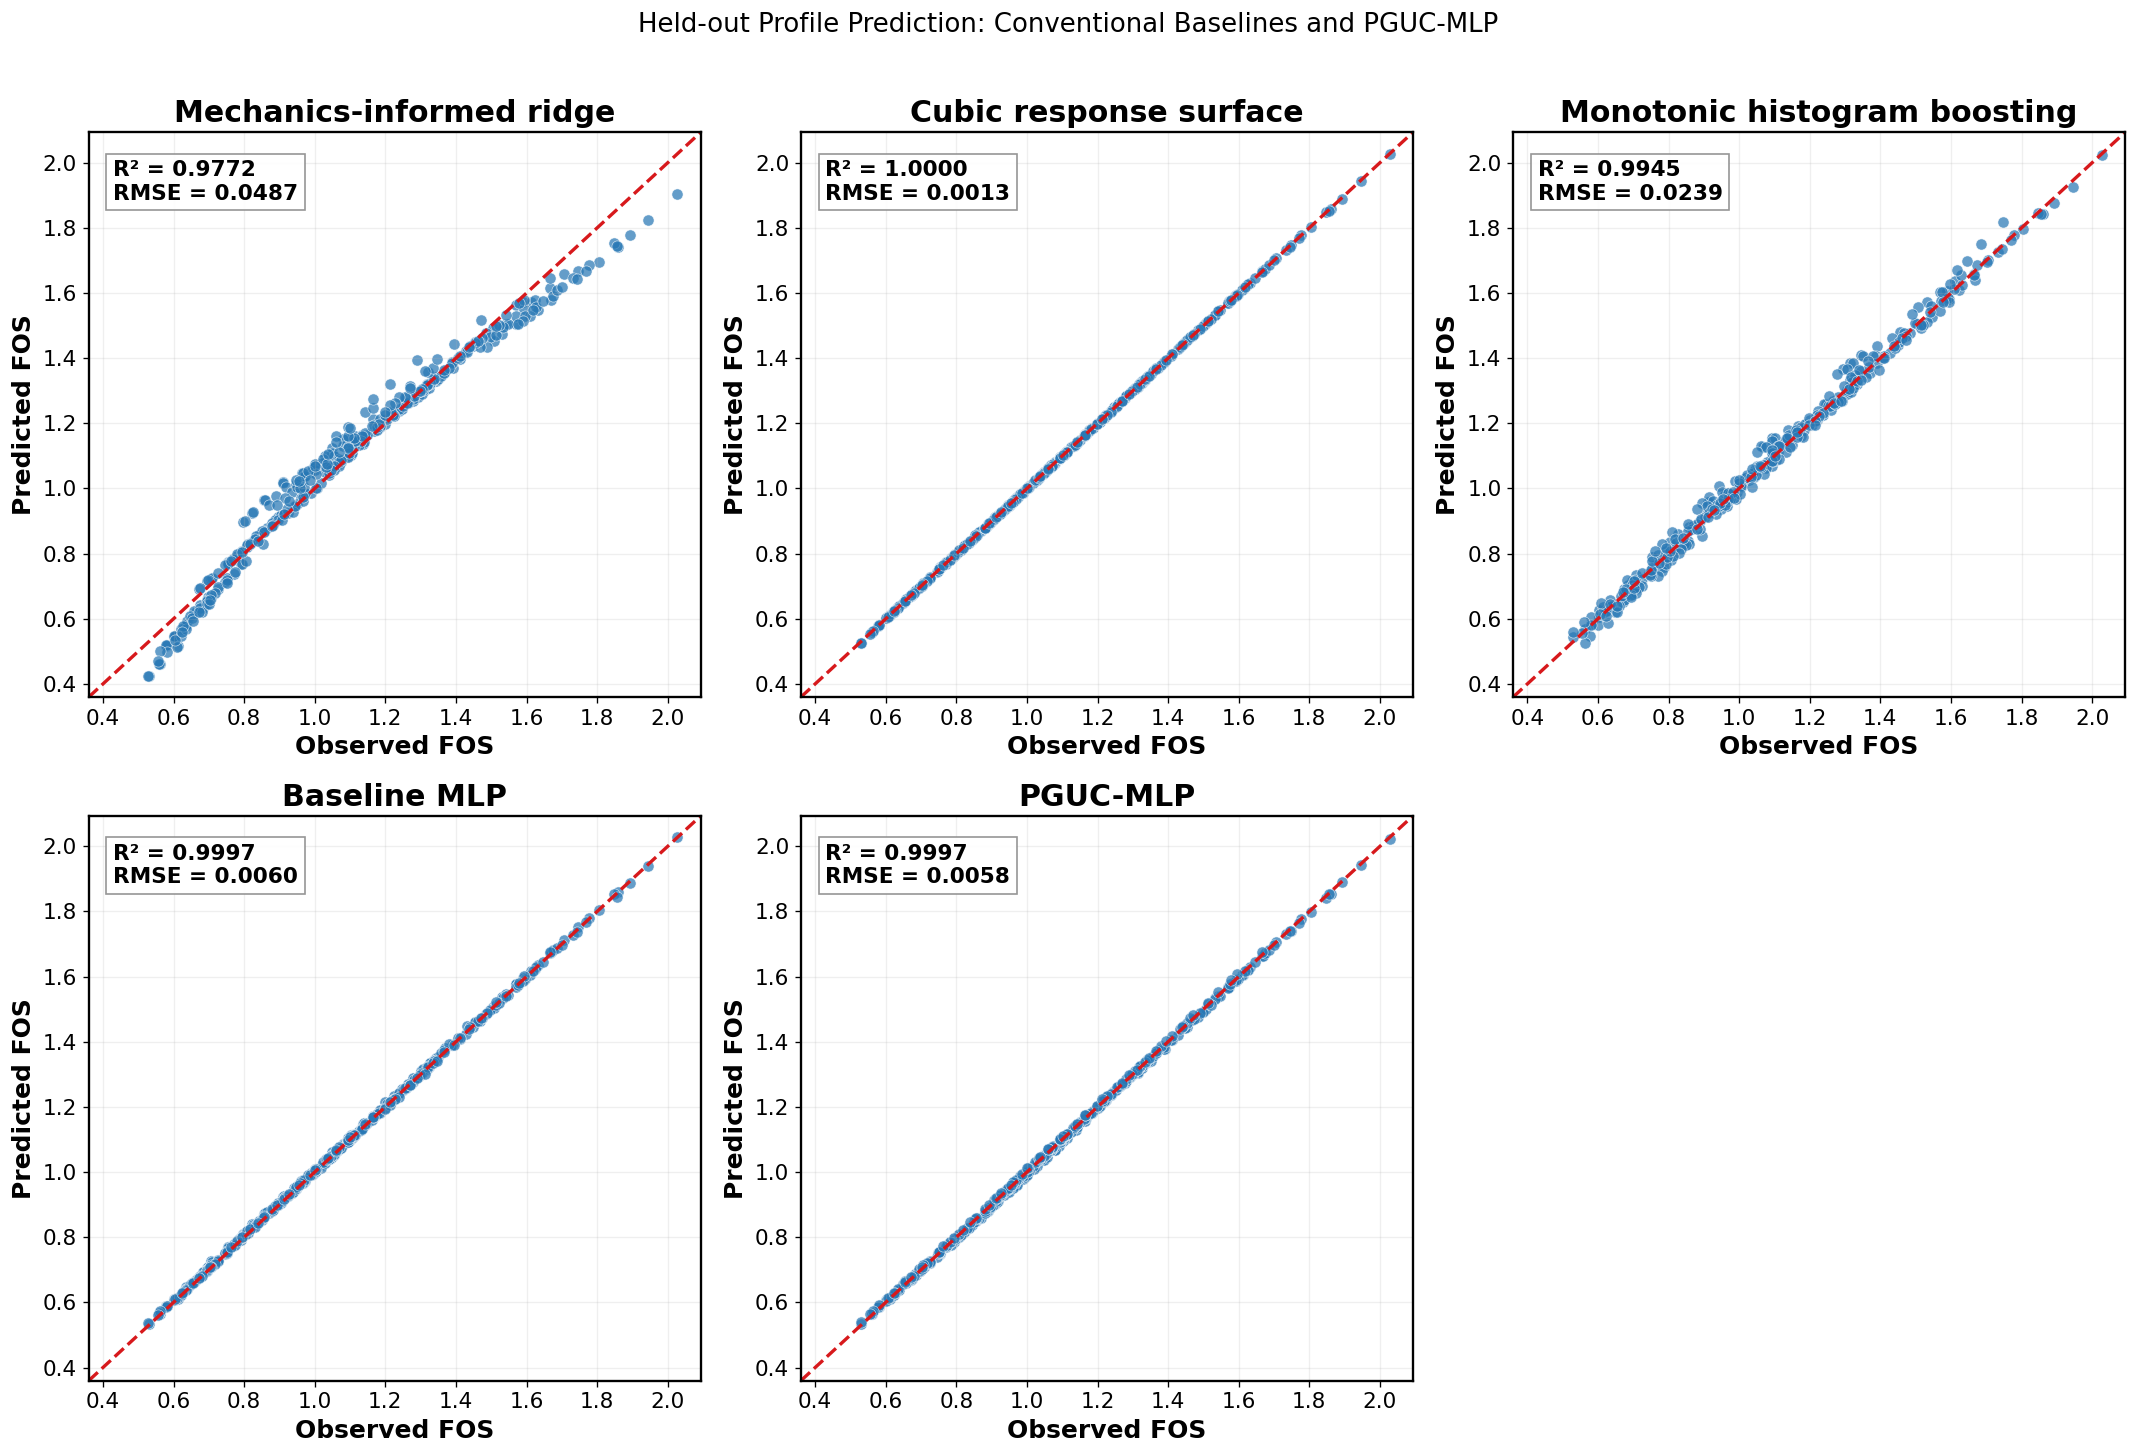

In [29]:
def mechanics_design_matrix(x):
    x = np.asarray(x, dtype=float)
    c, phi, gamma, height, beta, moisture = x.T
    derived = np.column_stack([
        c / np.maximum(gamma * height, 1e-12),
        np.tan(np.deg2rad(phi)),
        np.tan(np.deg2rad(beta)),
    ])
    return np.column_stack([x, derived])

baseline_cv = GroupKFold(n_splits=N_SPLITS)
baseline_specs = {
    "Mechanics-informed ridge": {
        "estimator": Pipeline([
            ("mechanics", FunctionTransformer(mechanics_design_matrix, validate=False)),
            ("scale", StandardScaler()),
            ("model", Ridge()),
        ]),
        "grid": {"model__alpha": np.logspace(-6, 2, 9)},
    },
    "Cubic response surface": {
        "estimator": Pipeline([
            ("scale", StandardScaler()),
            ("polynomial", PolynomialFeatures(degree=3, include_bias=False)),
            ("model", Ridge()),
        ]),
        "grid": {"model__alpha": np.logspace(-8, 1, 10)},
    },
    "Monotonic histogram boosting": {
        "estimator": HistGradientBoostingRegressor(
            monotonic_cst=[1, 1, -1, -1, -1, 0],
            random_state=SEED,
            early_stopping=False,
        ),
        "grid": {
            "learning_rate": [0.03, 0.06, 0.10],
            "max_leaf_nodes": [7, 15, 31],
            "l2_regularization": [0.0, 1e-3, 1e-2],
            "max_iter": [300],
        },
    },
}

baseline_models = {}
baseline_predictions = {}
baseline_rows = []

for model_name, specification in baseline_specs.items():
    print(f"Selecting baseline: {model_name}")
    search = GridSearchCV(
        specification["estimator"],
        specification["grid"],
        scoring="neg_root_mean_squared_error",
        cv=baseline_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False,
    )
    search.fit(X_DEVELOPMENT, Y_DEVELOPMENT, groups=GROUPS_DEVELOPMENT)
    prediction = search.predict(X_TEST)
    baseline_models[model_name] = search.best_estimator_
    baseline_predictions[model_name] = prediction
    baseline_rows.append({
        "Model": model_name,
        "Grouped-CV RMSE": -float(search.best_score_),
        **point_metrics(Y_TEST, prediction),
        "Selected hyperparameters": json.dumps(search.best_params_, ensure_ascii=False, default=str),
    })
    joblib.dump(search.best_estimator_, DIRS["models"] / f"Baseline_{model_name.replace(' ', '_')}.pkl")

baseline_table = pd.DataFrame(baseline_rows)

mlp_comparison_rows = []
for key in ("standard_mlp", HEADLINE_MODEL_KEY):
    label = HEADLINE_MODEL_LABEL if key == HEADLINE_MODEL_KEY else CONFIGURATIONS[key]["label"]
    cv_row = cv_summary[cv_summary["Configuration"] == CONFIGURATIONS[key]["label"]]
    grouped_cv_rmse = float(cv_row["RMSE mean"].iloc[0]) if not cv_row.empty else np.nan
    mlp_comparison_rows.append({
        "Model": label,
        "Grouped-CV RMSE": grouped_cv_rmse,
        **point_metrics(Y_TEST, predictions[key]["mean"]),
        "Selected hyperparameters": json.dumps(BEST_PARAMS, ensure_ascii=False, default=str),
    })

model_comparison_table = pd.concat(
    [baseline_table, pd.DataFrame(mlp_comparison_rows)], ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

show_table(
    model_comparison_table[["Model", "Grouped-CV RMSE", "R²", "RMSE", "MAE", "Bias"]],
    caption="Conventional-baseline and neural-model comparison",
)
model_comparison_table.to_excel(DIRS["tables"] / "Table_Model_Comparison_with_Conventional_Baselines.xlsx", index=False)

model_prediction_registry = {**baseline_predictions}
model_prediction_registry[CONFIGURATIONS["standard_mlp"]["label"]] = predictions["standard_mlp"]["mean"]
model_prediction_registry[HEADLINE_MODEL_LABEL] = headline_result["mean"]

def bootstrap_prediction_metrics(actual, predicted, groups, repetitions=2000, seed=SEED):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    groups = np.asarray(groups)
    unique_groups = np.unique(groups)
    group_indices = {group: np.where(groups == group)[0] for group in unique_groups}
    rng = np.random.default_rng(seed)
    rmse_values, mae_values = [], []
    for _ in range(repetitions):
        sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
        sampled_indices = np.concatenate([group_indices[group] for group in sampled_groups])
        rmse_values.append(np.sqrt(mean_squared_error(actual[sampled_indices], predicted[sampled_indices])))
        mae_values.append(mean_absolute_error(actual[sampled_indices], predicted[sampled_indices]))
    return {
        "RMSE 95% CI lower": np.quantile(rmse_values, 0.025),
        "RMSE 95% CI upper": np.quantile(rmse_values, 0.975),
        "MAE 95% CI lower": np.quantile(mae_values, 0.025),
        "MAE 95% CI upper": np.quantile(mae_values, 0.975),
    }

comparison_ci_rows = []
for model_index, (model_name, prediction) in enumerate(model_prediction_registry.items()):
    comparison_ci_rows.append({
        "Model": model_name,
        **bootstrap_prediction_metrics(
            Y_TEST, prediction, test_df["profile_group"].to_numpy(),
            repetitions=2000, seed=SEED + model_index,
        ),
    })

model_comparison_table = model_comparison_table.merge(
    pd.DataFrame(comparison_ci_rows), on="Model", how="left"
)
model_comparison_table.to_excel(
    DIRS["tables"] / "Table_Model_Comparison_with_Conventional_Baselines.xlsx", index=False
)
show_table(
    model_comparison_table[
        ["Model", "Grouped-CV RMSE", "RMSE", "RMSE 95% CI lower", "RMSE 95% CI upper", "MAE", "R²"]
    ],
    caption="Model comparison with profile-bootstrap confidence intervals",
)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
comparison_limits = [
    min(Y_TEST.min(), *(np.min(value) for value in model_prediction_registry.values())),
    max(Y_TEST.max(), *(np.max(value) for value in model_prediction_registry.values())),
]
pad = 0.04 * (comparison_limits[1] - comparison_limits[0])
comparison_limits = [comparison_limits[0] - pad, comparison_limits[1] + pad]

for axis, (model_name, prediction) in zip(axes.ravel(), model_prediction_registry.items()):
    metrics = point_metrics(Y_TEST, prediction)
    axis.scatter(Y_TEST, prediction, s=45, alpha=0.72, color="#2878B5", edgecolor="white", linewidth=0.4)
    axis.plot(comparison_limits, comparison_limits, "--", color="#D7191C", linewidth=2)
    axis.set_xlim(comparison_limits)
    axis.set_ylim(comparison_limits)
    axis.set_title(model_name)
    axis.set_xlabel("Observed FOS")
    axis.set_ylabel("Predicted FOS")
    axis.grid(alpha=0.20)
    axis.text(
        0.04, 0.95, f"R² = {metrics['R²']:.4f}\nRMSE = {metrics['RMSE']:.4f}",
        transform=axis.transAxes, va="top", fontweight="bold",
        bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "#888888"},
    )

for axis in axes.ravel()[len(model_prediction_registry):]:
    axis.axis("off")

fig.suptitle("Held-out Profile Prediction: Conventional Baselines and PGUC-MLP", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_03_Model_Comparison")
plt.show()
plt.close(fig)

best_baseline_rmse = baseline_table["RMSE"].min()
headline_rmse = point_metrics(Y_TEST, headline_result["mean"])["RMSE"]
if headline_rmse > 1.10 * best_baseline_rmse:
    warnings.warn(
        "PGUC-MLP RMSE exceeds the best conventional baseline by more than 10%. "
        "Do not claim superior point accuracy; frame the contribution around physics consistency, "
        "profile-wise uncertainty and interaction-level explanation."
    )


### 8.4 Observed-versus-predicted ablation figure

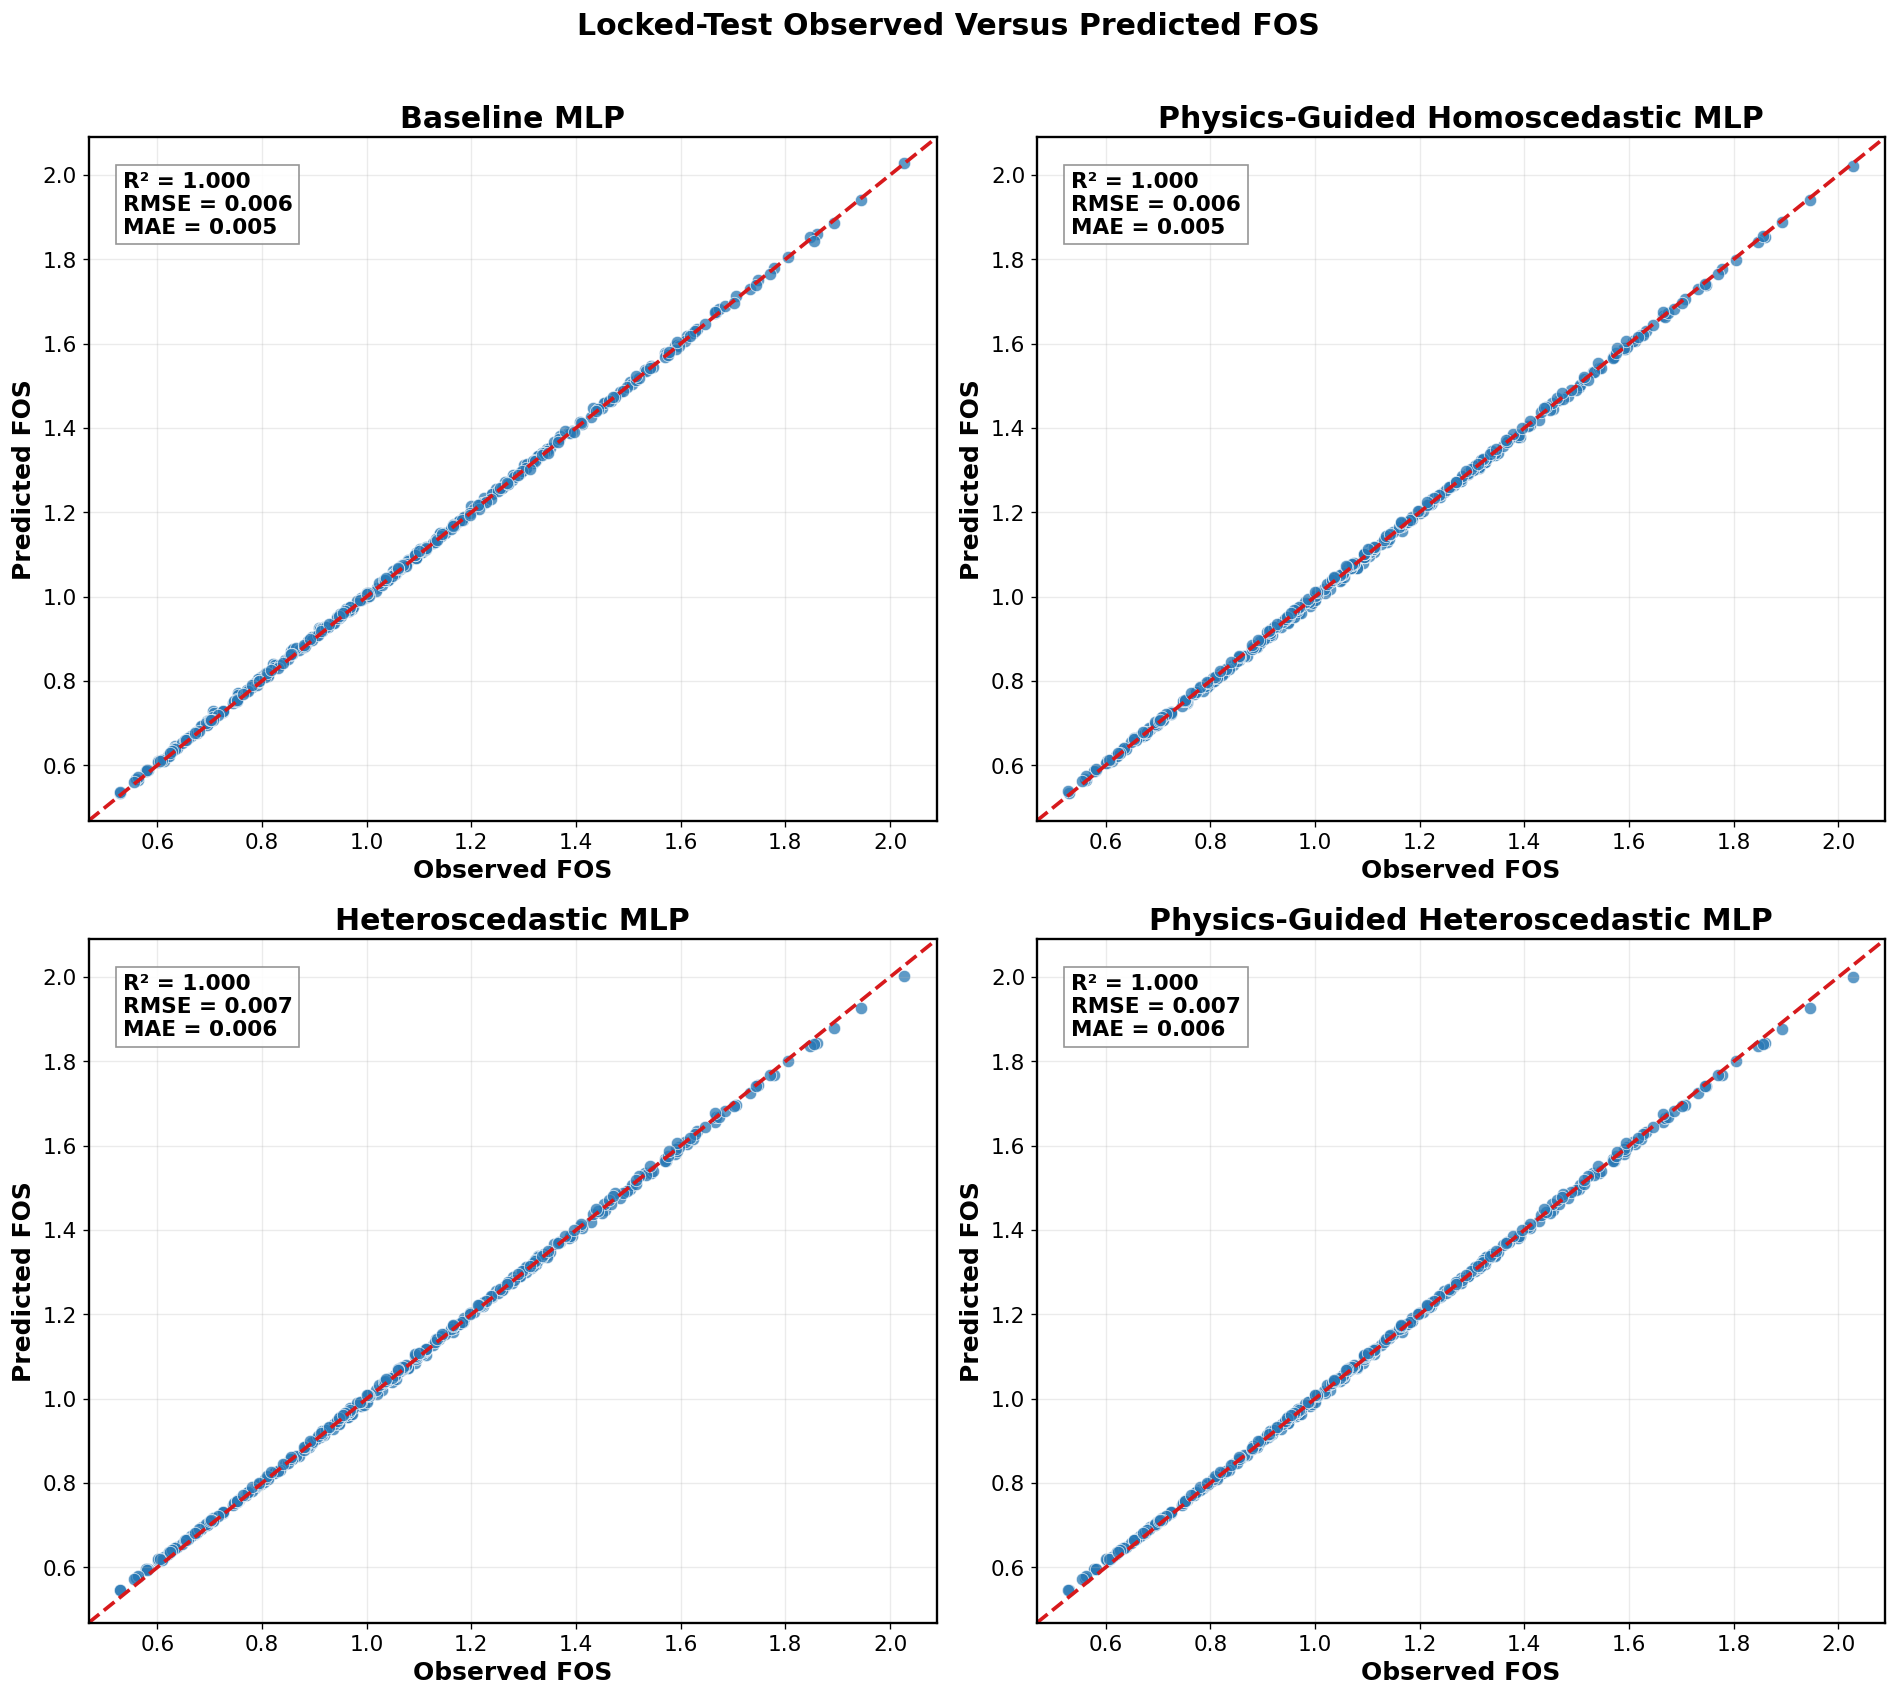

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
limits = [min(Y_TEST.min(), *(result["mean"].min() for result in predictions.values())),
          max(Y_TEST.max(), *(result["mean"].max() for result in predictions.values()))]
padding = 0.04 * (limits[1] - limits[0])
limits = [limits[0] - padding, limits[1] + padding]

for axis, (configuration_key, specification) in zip(axes.ravel(), CONFIGURATIONS.items()):
    predicted = predictions[configuration_key]["mean"]
    metrics = point_metrics(Y_TEST, predicted)
    axis.scatter(Y_TEST, predicted, s=55, alpha=0.75, color="#2878B5", edgecolor="white", linewidth=0.5)
    axis.plot(limits, limits, linestyle="--", linewidth=2.2, color="#D7191C")
    axis.set_xlim(limits)
    axis.set_ylim(limits)
    axis.set_title(specification["label"])
    axis.set_xlabel("Observed FOS")
    axis.set_ylabel("Predicted FOS")
    axis.grid(alpha=0.25)
    axis.text(
        0.04, 0.95,
        f"R² = {metrics['R²']:.3f}\nRMSE = {metrics['RMSE']:.3f}\nMAE = {metrics['MAE']:.3f}",
        transform=axis.transAxes, va="top", fontsize=FONT_TICK, fontweight="bold",
        bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "#888888"},
    )

fig.suptitle("Locked-Test Observed Versus Predicted FOS", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Figure_06_Observed_vs_Predicted_Ablation")
plt.show()
plt.close(fig)

### 8.5 PGUC-MLP residual diagnostics


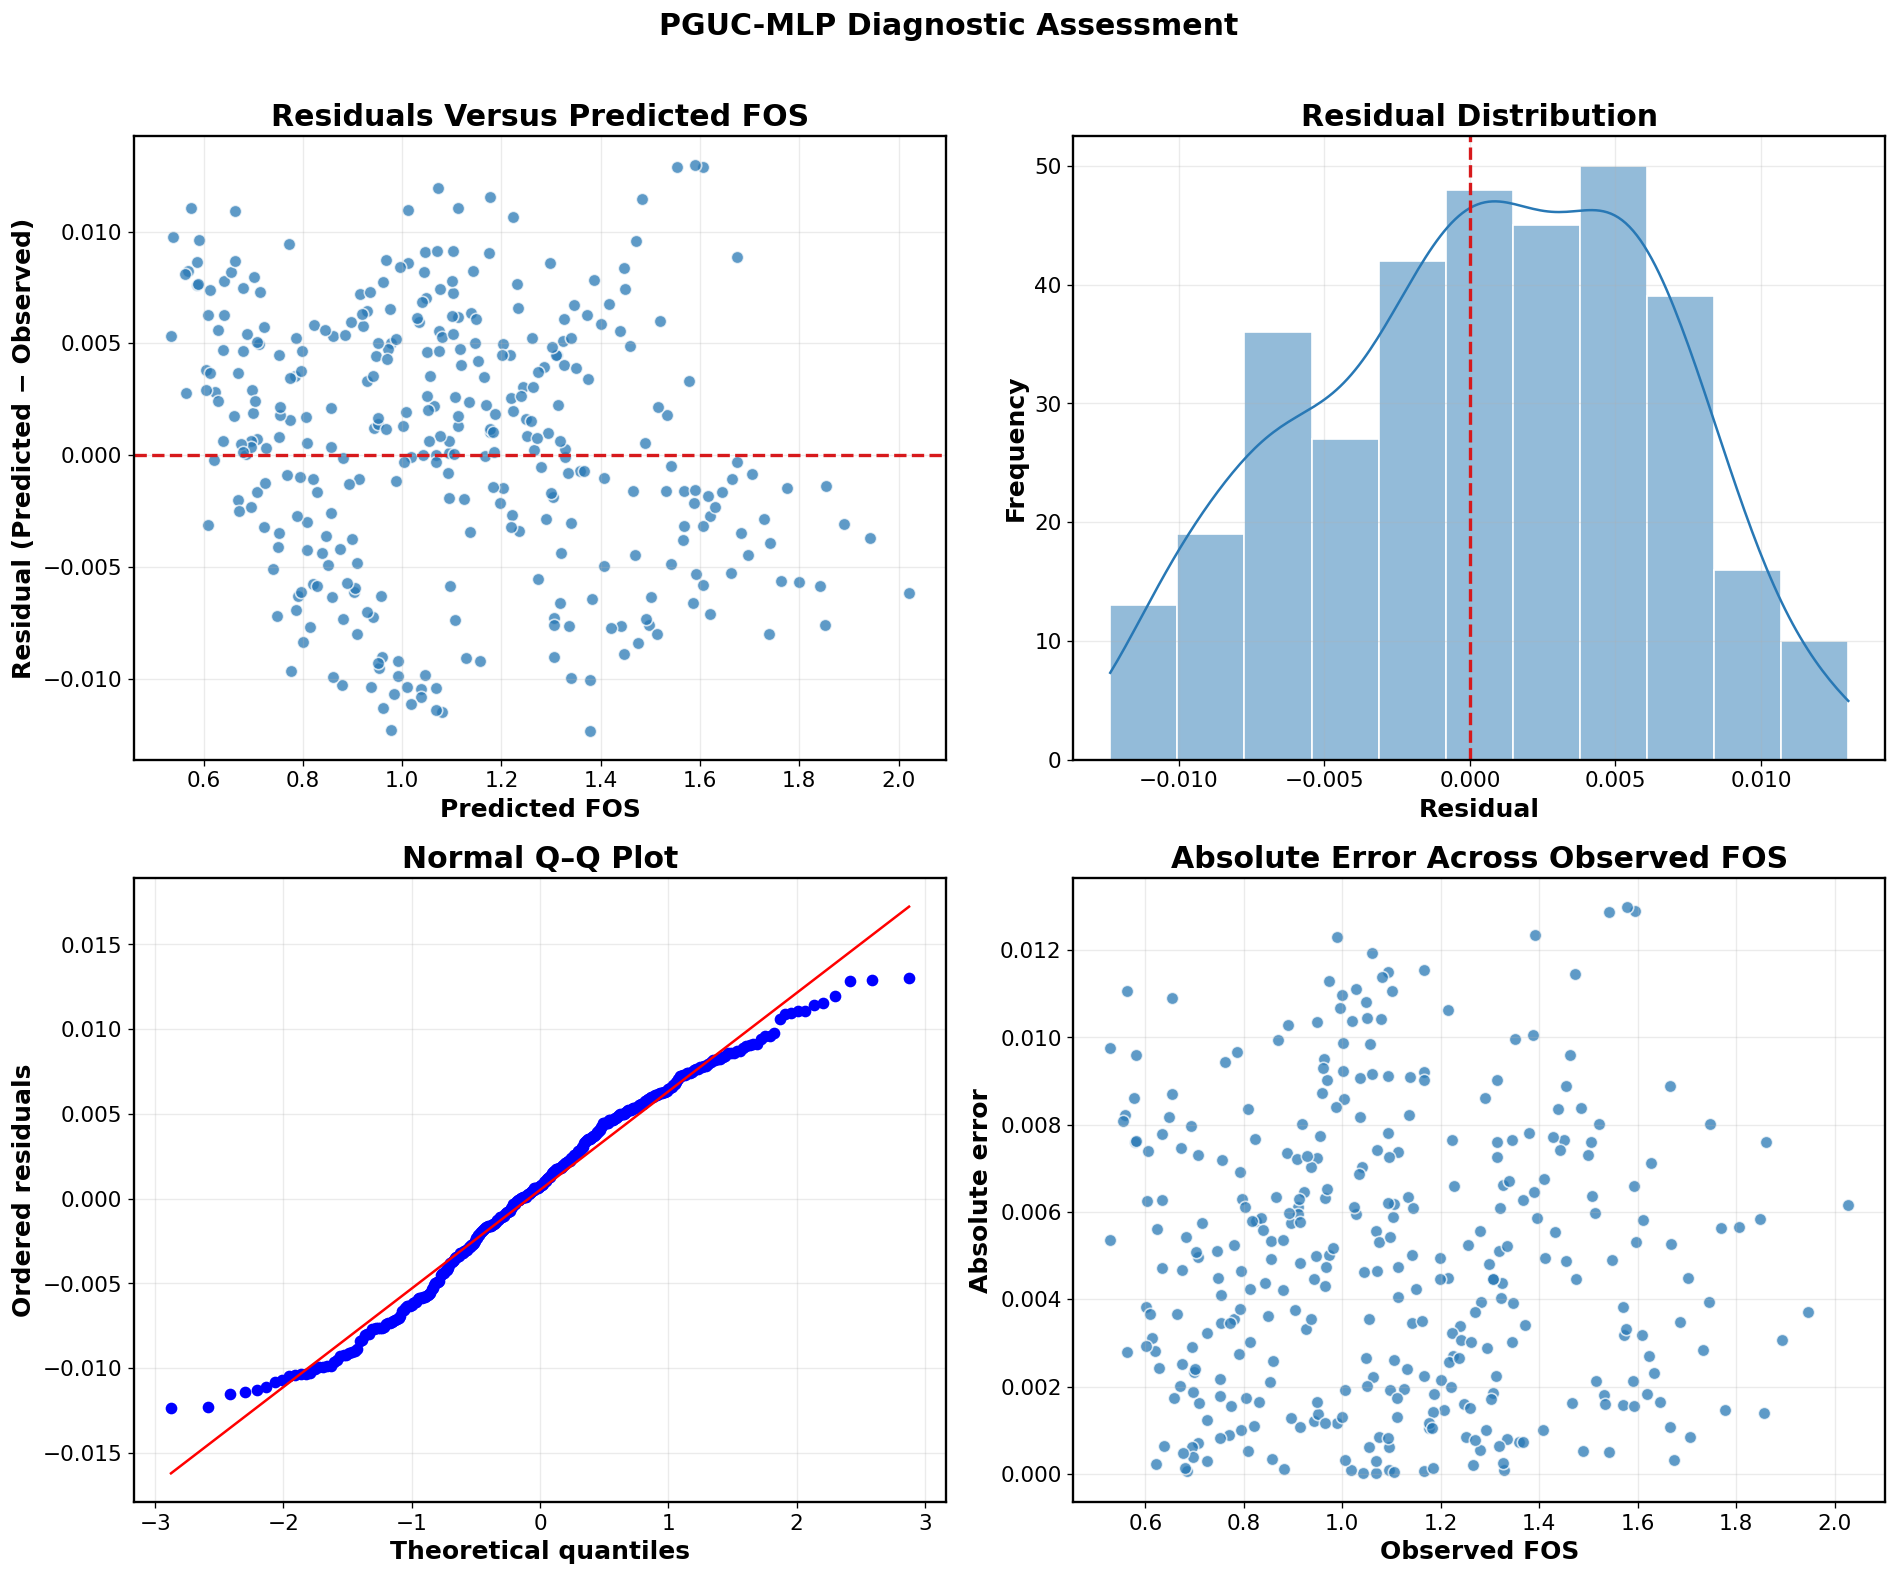

In [31]:
full_prediction = headline_result["mean"]
full_residual = full_prediction - Y_TEST

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

axes[0, 0].scatter(full_prediction, full_residual, s=55, alpha=0.75, color="#2878B5", edgecolor="white")
axes[0, 0].axhline(0, color="#D7191C", linestyle="--", linewidth=2)
axes[0, 0].set_title("Residuals Versus Predicted FOS")
axes[0, 0].set_xlabel("Predicted FOS")
axes[0, 0].set_ylabel("Residual (Predicted − Observed)")

sns.histplot(full_residual, kde=True, color="#2878B5", edgecolor="white", ax=axes[0, 1])
axes[0, 1].axvline(0, color="#D7191C", linestyle="--", linewidth=2)
axes[0, 1].set_title("Residual Distribution")
axes[0, 1].set_xlabel("Residual")
axes[0, 1].set_ylabel("Frequency")

stats.probplot(full_residual, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Normal Q–Q Plot")
axes[1, 0].set_xlabel("Theoretical quantiles")
axes[1, 0].set_ylabel("Ordered residuals")

axes[1, 1].scatter(Y_TEST, np.abs(full_residual), s=55, alpha=0.75, color="#2878B5", edgecolor="white")
axes[1, 1].set_title("Absolute Error Across Observed FOS")
axes[1, 1].set_xlabel("Observed FOS")
axes[1, 1].set_ylabel("Absolute error")

for axis in axes.ravel():
    axis.grid(alpha=0.25)

fig.suptitle("PGUC-MLP Diagnostic Assessment", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["performance"], "Supplementary_Figure_PGUC_MLP_Diagnostics")
plt.show()
plt.close(fig)

### 8.6 Ablation performance comparison

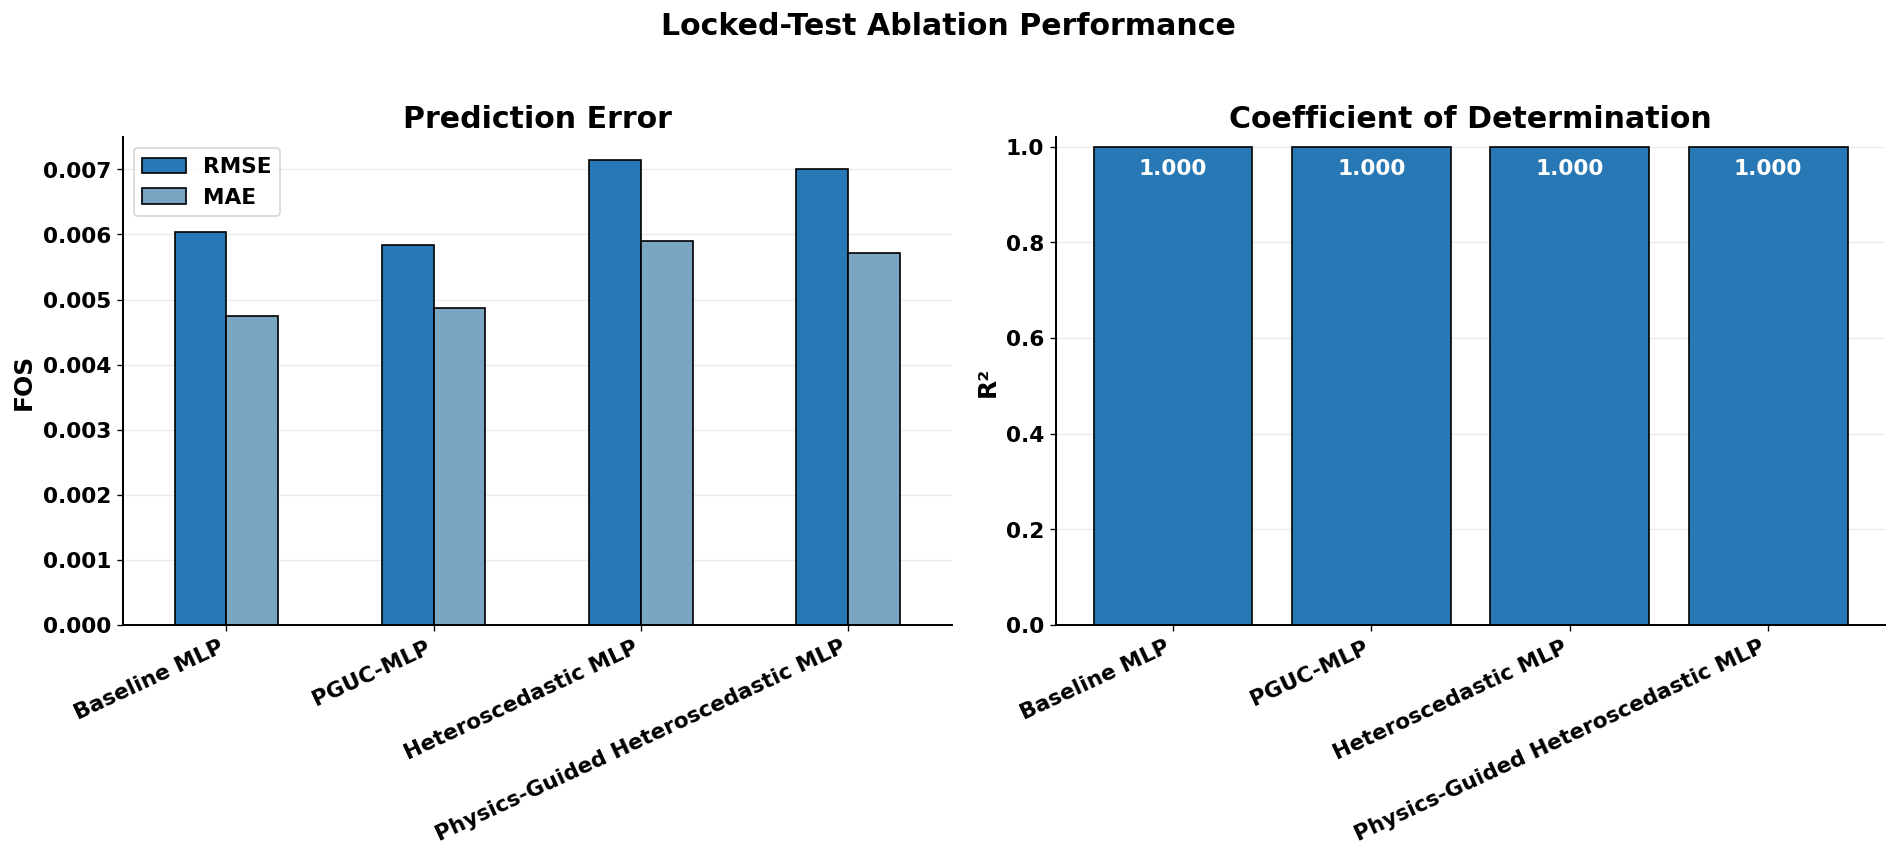

In [32]:
# ================================================================
# FIGURE 08: LOCKED-TEST ABLATION PERFORMANCE
# ================================================================

plot_table = performance_table.set_index("Configuration")

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7),
)


# ================================================================
# LEFT PANEL: PREDICTION ERROR
# No numerical values displayed on the bars
# ================================================================

error_metrics = plot_table[["RMSE", "MAE"]]

error_metrics.plot(
    kind="bar",
    ax=axes[0],
    color=["#2878B5", "#7AA6C2"],
    edgecolor="black",
    linewidth=1.0,
)

axes[0].set_title(
    "Prediction Error",
    fontsize=FONT_TITLE,
    fontweight="bold",
)

axes[0].set_xlabel("")
axes[0].set_ylabel(
    "FOS",
    fontsize=FONT_LABEL,
    fontweight="bold",
)

axes[0].tick_params(
    axis="x",
    rotation=25,
    labelsize=FONT_TICK,
    colors="black",
)

axes[0].tick_params(
    axis="y",
    labelsize=FONT_TICK,
    colors="black",
)

axes[0].legend(
    title=None,
    prop={
        "size": FONT_TICK,
        "weight": "bold",
    },
)

# Bold all tick labels
for tick_label in axes[0].get_xticklabels():
    tick_label.set_horizontalalignment("right")
    tick_label.set_fontweight("bold")

for tick_label in axes[0].get_yticklabels():
    tick_label.set_fontweight("bold")


# ================================================================
# RIGHT PANEL: COEFFICIENT OF DETERMINATION
# R² values displayed inside the bars
# ================================================================

r2_values = plot_table["R²"].to_numpy(dtype=float)

bars = axes[1].bar(
    plot_table.index,
    r2_values,
    color="#2878B5",
    edgecolor="black",
    linewidth=1.0,
)

axes[1].set_title(
    "Coefficient of Determination",
    fontsize=FONT_TITLE,
    fontweight="bold",
)

axes[1].set_xlabel("")
axes[1].set_ylabel(
    "R²",
    fontsize=FONT_LABEL,
    fontweight="bold",
)

axes[1].tick_params(
    axis="x",
    rotation=25,
    labelsize=FONT_TICK,
    colors="black",
)

axes[1].tick_params(
    axis="y",
    labelsize=FONT_TICK,
    colors="black",
)

axes[1].set_ylim(
    min(
        0,
        float(np.min(r2_values)) - 0.05,
    ),
    min(
        1.02,
        float(np.max(r2_values)) + 0.08,
    ),
)

# Place each R² value inside its corresponding bar.
# The label is positioned close to the upper end of the bar.
for bar, value in zip(bars, r2_values):

    bar_height = bar.get_height()

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar_height - 0.025,
        f"{value:.3f}",
        ha="center",
        va="top",
        fontsize=FONT_TICK,
        fontweight="bold",
        color="white",
        zorder=5,
    )

# Bold all tick labels
for tick_label in axes[1].get_xticklabels():
    tick_label.set_horizontalalignment("right")
    tick_label.set_fontweight("bold")

for tick_label in axes[1].get_yticklabels():
    tick_label.set_fontweight("bold")


# ================================================================
# GENERAL FORMATTING
# ================================================================

for axis in axes:

    axis.grid(
        axis="y",
        alpha=0.25,
        zorder=0,
    )

    axis.set_axisbelow(True)

    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)

    axis.spines["left"].set_color("black")
    axis.spines["bottom"].set_color("black")

    axis.spines["left"].set_linewidth(1.2)
    axis.spines["bottom"].set_linewidth(1.2)


fig.suptitle(
    "Locked-Test Ablation Performance",
    fontsize=FONT_TITLE,
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()


# ================================================================
# SAVE, DISPLAY AND CLOSE
# ================================================================

fig.tight_layout()

# ================================================================
# SAVE DIRECTLY
# ================================================================


performance_directory = str(
    os.fspath(DIRS["performance"])
)

os.makedirs(
    performance_directory,
    exist_ok=True,
)

figure_name = "Figure_08_Ablation_Performance"

fig.savefig(
    os.path.join(
        performance_directory,
        f"{figure_name}.png",
    ),
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
)

fig.savefig(
    os.path.join(
        performance_directory,
        f"{figure_name}.pdf",
    ),
    bbox_inches="tight",
    facecolor="white",
    edgecolor="none",
)

plt.show()
plt.close(fig)

### 8.7 Profile-wise prediction intervals and empirical calibration

The left panel shows the 95% profile-wise conformal interval. The right panel distinguishes secondary observation coverage from the primary simultaneous-profile coverage. With only 22 calibration profiles, attainable finite-sample confidence levels are discrete.


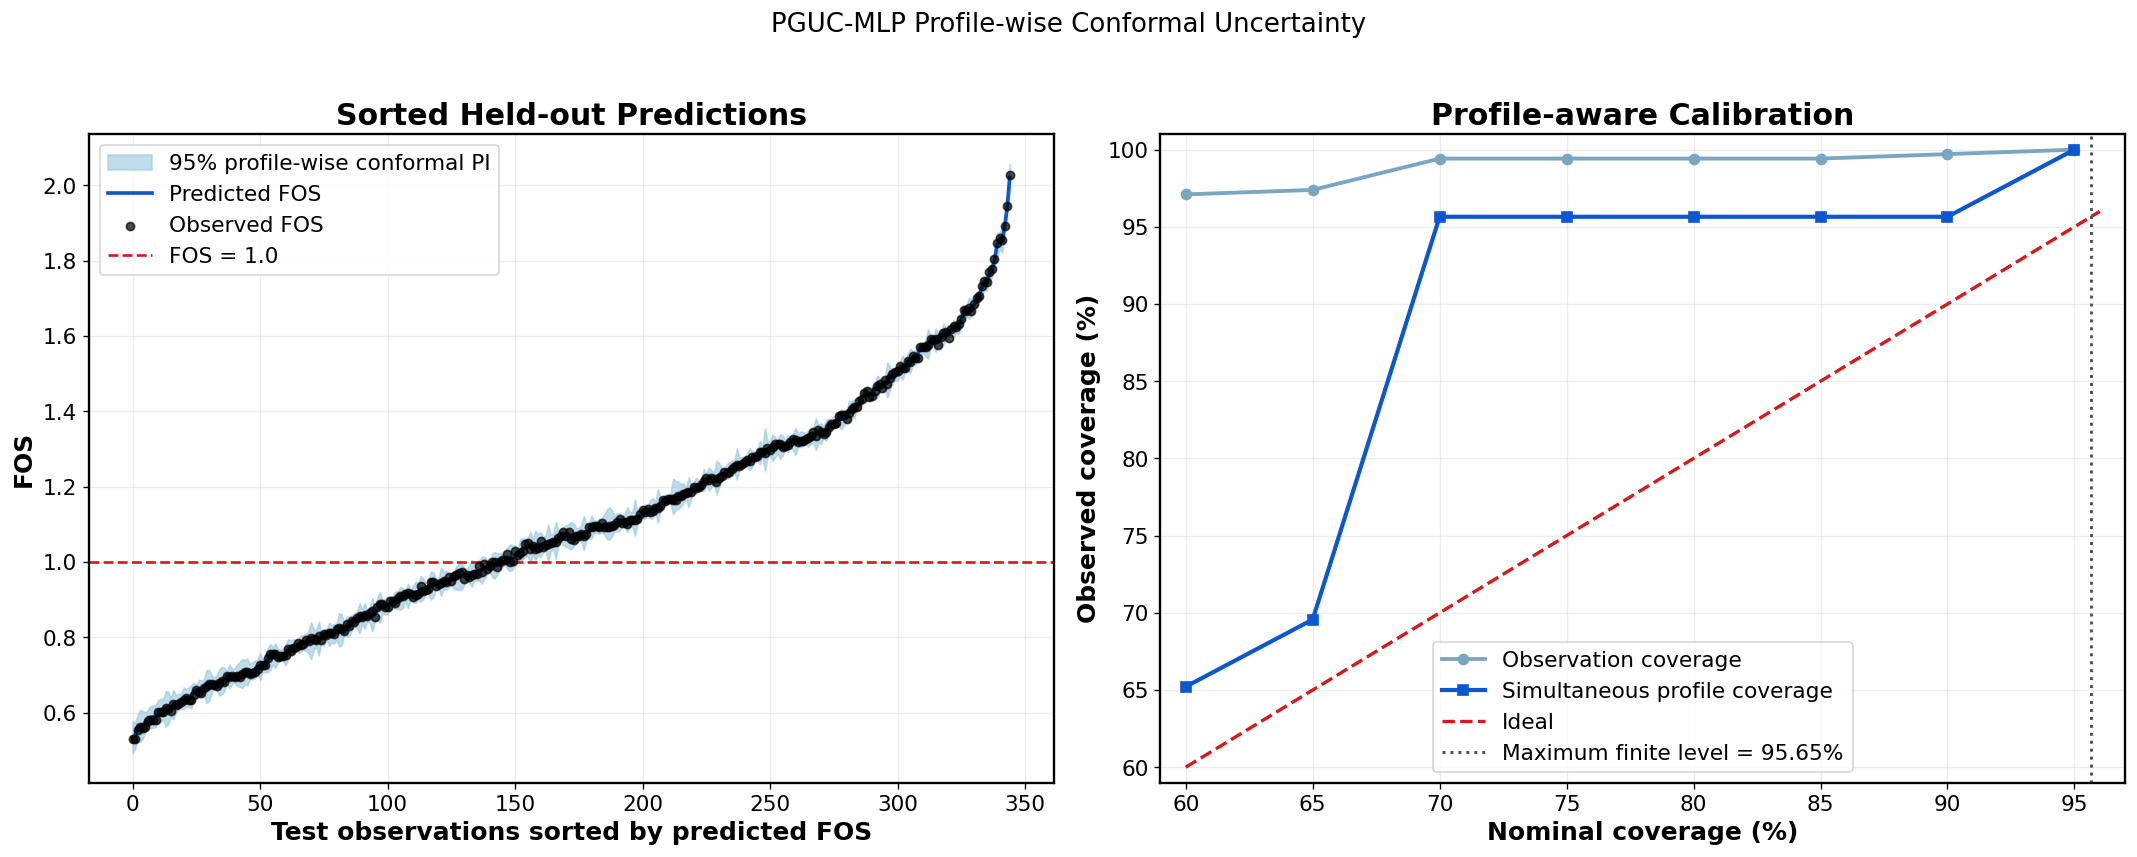

,Nominal coverage (%),Order statistic,Observation coverage (%),Simultaneous profile coverage (%),Mean interval width
0,60.0000,14,97.1014,65.2174,0.0267
1,65.0000,15,97.3913,69.5652,0.0276
2,70.0000,17,99.4203,95.6522,0.0329
3,75.0000,18,99.4203,95.6522,0.0368
4,80.0000,19,99.4203,95.6522,0.0387
5,85.0000,20,99.4203,95.6522,0.0400
6,90.0000,21,99.7101,95.6522,0.0440
7,95.0000,22,100.0000,100.0000,0.0481


In [33]:
sort_index = np.argsort(headline_result["mean"])
n_calibration_profiles = len(calibration_objects[HEADLINE_MODEL_KEY]["profile_scores"])
maximum_finite_coverage = n_calibration_profiles / (n_calibration_profiles + 1)
coverage_grid = np.array([0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95])

coverage_rows = []
for coverage in coverage_grid:
    quantile, order_index = conformal_order_statistic(
        calibration_objects[HEADLINE_MODEL_KEY]["profile_scores"], coverage
    )
    if not np.isfinite(quantile):
        coverage_rows.append({
            "Nominal coverage (%)": 100 * coverage,
            "Order statistic": order_index,
            "Observation coverage (%)": np.nan,
            "Simultaneous profile coverage (%)": np.nan,
            "Mean interval width": np.inf,
        })
        continue
    lower = headline_result["mean"] - quantile * headline_result["conformal_scale"]
    upper = headline_result["mean"] + quantile * headline_result["conformal_scale"]
    covered = (Y_TEST >= lower) & (Y_TEST <= upper)
    profile_picp, _, _ = profile_coverage(test_df, covered)
    coverage_rows.append({
        "Nominal coverage (%)": 100 * coverage,
        "Order statistic": order_index,
        "Observation coverage (%)": 100 * covered.mean(),
        "Simultaneous profile coverage (%)": profile_picp,
        "Mean interval width": np.mean(upper - lower),
    })

calibration_curve_table = pd.DataFrame(coverage_rows)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
x_axis = np.arange(len(Y_TEST))
axes[0].fill_between(
    x_axis,
    headline_result["lower_95"][sort_index],
    headline_result["upper_95"][sort_index],
    color="#9ECAE1", alpha=0.65, label="95% profile-wise conformal PI",
)
axes[0].plot(x_axis, headline_result["mean"][sort_index], color="#0B57D0", linewidth=2.2, label="Predicted FOS")
axes[0].scatter(x_axis, Y_TEST[sort_index], color="black", s=24, alpha=0.70, label="Observed FOS", zorder=3)
axes[0].axhline(1.0, color="#D7191C", linestyle="--", linewidth=1.6, label="FOS = 1.0")
axes[0].set_title("Sorted Held-out Predictions")
axes[0].set_xlabel("Test observations sorted by predicted FOS")
axes[0].set_ylabel("FOS")
axes[0].legend()
axes[0].grid(alpha=0.22)

finite_curve = calibration_curve_table.replace([np.inf, -np.inf], np.nan).dropna(subset=["Observation coverage (%)"])
axes[1].plot(
    finite_curve["Nominal coverage (%)"], finite_curve["Observation coverage (%)"],
    marker="o", linewidth=2.3, color="#7AA6C2", label="Observation coverage",
)
axes[1].plot(
    finite_curve["Nominal coverage (%)"], finite_curve["Simultaneous profile coverage (%)"],
    marker="s", linewidth=2.5, color="#0B57D0", label="Simultaneous profile coverage",
)
axes[1].plot([60, 96], [60, 96], "--", linewidth=2.0, color="#D7191C", label="Ideal")
axes[1].axvline(100 * maximum_finite_coverage, color="#555555", linestyle=":", linewidth=1.8,
                label=f"Maximum finite level = {100 * maximum_finite_coverage:.2f}%")
axes[1].set_title("Profile-aware Calibration")
axes[1].set_xlabel("Nominal coverage (%)")
axes[1].set_ylabel("Observed coverage (%)")
axes[1].set_xlim(59, 97)
axes[1].set_ylim(59, 101)
axes[1].legend()
axes[1].grid(alpha=0.22)

fig.suptitle("PGUC-MLP Profile-wise Conformal Uncertainty", y=1.02)
fig.tight_layout()
save_figure(fig, DIRS["uncertainty"], "Figure_04_Profile_Wise_Conformal_Intervals")
plt.show()
plt.close(fig)

show_table(calibration_curve_table, caption="Observation and simultaneous-profile empirical coverage")
calibration_curve_table.to_csv(DIRS["tables"] / "Table_Profile_Wise_Conformal_Calibration_Curve.csv", index=False)


### 8.8 Conditional performance, profile bootstrap and engineering decisions

The decision audit prioritises unsafe false assurance. A conformal interval wholly above FOS = 1.0 is classified definitely stable, one wholly below 1.0 definitely unstable, and an interval crossing 1.0 indeterminate.


In [34]:
conditional = test_df[["row_id", "profile_group", "H", "beta", TARGET]].copy()
conditional["Predicted FOS"] = headline_result["mean"]
conditional["Residual"] = conditional["Predicted FOS"] - conditional[TARGET]
conditional["FOS range"] = pd.cut(
    conditional[TARGET], [-np.inf, 1.0, 1.5, np.inf],
    labels=["FOS < 1.0", "1.0 ≤ FOS < 1.5", "FOS ≥ 1.5"], right=False,
)
conditional["Stability class"] = np.where(conditional[TARGET] < 1.0, "Unstable", "Stable")
conditional["Geometry"] = conditional.apply(lambda row: f"H={row['H']:g} m; β={row['beta']:g}°", axis=1)

for level in (90, 95):
    conditional[f"Lower {level}%"] = headline_result[f"lower_{level}"]
    conditional[f"Upper {level}%"] = headline_result[f"upper_{level}"]
    conditional[f"Covered {level}%"] = (
        (conditional[TARGET] >= conditional[f"Lower {level}%"]) &
        (conditional[TARGET] <= conditional[f"Upper {level}%"])
    )

def summarise_condition(frame, dimension, level):
    rows = []
    for group_name, group in frame.groupby(dimension, observed=True, sort=False):
        rows.append({
            "Dimension": dimension,
            "Group": str(group_name),
            "Nominal coverage (%)": level,
            "Observations": len(group),
            "Profiles": group["profile_group"].nunique(),
            "RMSE": np.sqrt(np.mean(group["Residual"] ** 2)),
            "MAE": np.mean(np.abs(group["Residual"])),
            "Bias": np.mean(group["Residual"]),
            "Observation coverage (%)": 100 * group[f"Covered {level}%"].mean(),
            "Mean interval width": np.mean(group[f"Upper {level}%"] - group[f"Lower {level}%"]),
        })
    return rows

conditional_rows = []
for level in (90, 95):
    for dimension in ("FOS range", "Stability class", "Geometry"):
        conditional_rows.extend(summarise_condition(conditional, dimension, level))
conditional_audit = pd.DataFrame(conditional_rows)
main_conditional_audit = conditional_audit[
    conditional_audit["Dimension"].isin(["FOS range", "Stability class"])
].copy()

def bootstrap_profile_blocks(frame, statistic, repetitions=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    profile_ids = frame["profile_group"].drop_duplicates().to_numpy()
    values = []
    for _ in range(repetitions):
        sampled_ids = rng.choice(profile_ids, size=len(profile_ids), replace=True)
        blocks = []
        for draw_index, profile_id in enumerate(sampled_ids):
            block = frame[frame["profile_group"] == profile_id].copy()
            block["bootstrap_profile"] = draw_index
            blocks.append(block)
        values.append(statistic(pd.concat(blocks, ignore_index=True)))
    return np.quantile(values, [0.025, 0.975])

bootstrap_rows = []
for level in (90, 95):
    observation_ci = bootstrap_profile_blocks(
        conditional, lambda x, l=level: 100 * x[f"Covered {l}%"].mean(), seed=SEED + level
    )
    profile_ci = bootstrap_profile_blocks(
        conditional,
        lambda x, l=level: 100 * x.groupby("bootstrap_profile")[f"Covered {l}%"].all().mean(),
        seed=SEED + 2 * level,
    )
    rmse_ci = bootstrap_profile_blocks(
        conditional, lambda x: np.sqrt(np.mean(x["Residual"] ** 2)), seed=SEED + 3 * level
    )
    covered = conditional[f"Covered {level}%"].to_numpy()
    profile_picp, covered_profiles, total_profiles = profile_coverage(conditional, covered)
    bootstrap_rows.append({
        "Nominal coverage (%)": level,
        "Observation coverage (%)": 100 * covered.mean(),
        "Observation coverage 95% CI lower": observation_ci[0],
        "Observation coverage 95% CI upper": observation_ci[1],
        "Simultaneous profile coverage (%)": profile_picp,
        "Profiles covered": f"{covered_profiles}/{total_profiles}",
        "Profile coverage 95% CI lower": profile_ci[0],
        "Profile coverage 95% CI upper": profile_ci[1],
        "RMSE": np.sqrt(np.mean(conditional["Residual"] ** 2)),
        "RMSE 95% CI lower": rmse_ci[0],
        "RMSE 95% CI upper": rmse_ci[1],
    })
bootstrap_audit = pd.DataFrame(bootstrap_rows)

safety_rows = []
for model_name, predicted in model_prediction_registry.items():
    predicted = np.asarray(predicted)
    safety_rows.append({
        "Model": model_name,
        "False-safe point predictions": int(((predicted >= 1.0) & (Y_TEST < 1.0)).sum()),
        "False-unstable point predictions": int(((predicted < 1.0) & (Y_TEST >= 1.0)).sum()),
        "Point accuracy at FOS=1.0 (%)": 100 * np.mean((predicted >= 1.0) == (Y_TEST >= 1.0)),
    })
safety_decision_table = pd.DataFrame(safety_rows)

lower_95 = headline_result["lower_95"]
upper_95 = headline_result["upper_95"]
interval_decision = np.where(lower_95 >= 1.0, "Definitely stable", np.where(upper_95 < 1.0, "Definitely unstable", "Indeterminate"))
incorrect_definite = (
    ((interval_decision == "Definitely stable") & (Y_TEST < 1.0)) |
    ((interval_decision == "Definitely unstable") & (Y_TEST >= 1.0))
)
interval_decision_table = pd.DataFrame({
    "Decision outcome": ["Definitely stable", "Definitely unstable", "Indeterminate", "Incorrect definite decisions"],
    "Observations": [
        int((interval_decision == "Definitely stable").sum()),
        int((interval_decision == "Definitely unstable").sum()),
        int((interval_decision == "Indeterminate").sum()),
        int(incorrect_definite.sum()),
    ],
})

show_table(conditional_audit, caption="Conditional held-out performance and coverage")
show_table(bootstrap_audit, caption="Profile-bootstrap uncertainty in held-out estimates")
show_table(safety_decision_table, caption="FOS=1.0 point-decision audit")
show_table(interval_decision_table, precision=0, caption="PGUC-MLP 95% interval-decision audit")

conditional_audit.to_excel(DIRS["tables"] / "Table_Conditional_Performance_and_Coverage.xlsx", index=False)
main_conditional_audit.to_excel(DIRS["tables"] / "Table_Main_Conditional_Performance.xlsx", index=False)
bootstrap_audit.to_excel(DIRS["tables"] / "Table_Profile_Bootstrap_Confidence_Intervals.xlsx", index=False)
safety_decision_table.to_excel(DIRS["tables"] / "Table_Safety_Threshold_Decisions.xlsx", index=False)
interval_decision_table.to_excel(DIRS["tables"] / "Table_Interval_Decision_Audit.xlsx", index=False)


,Dimension,Group,Nominal coverage (%),Observations,Profiles,RMSE,MAE,Bias,Observation coverage (%),Mean interval width
0,FOS range,FOS ≥ 1.5,90,46,12,0.0055,0.0046,-0.0019,97.8261,0.0372
1,FOS range,FOS < 1.0,90,143,19,0.0057,0.0049,0.0008,100.0000,0.0475
2,FOS range,1.0 ≤ FOS < 1.5,90,156,19,0.0060,0.0050,0.0010,100.0000,0.0428
3,Stability class,Stable,90,202,19,0.0059,0.0049,0.0003,99.5050,0.0415
4,Stability class,Unstable,90,143,19,0.0057,0.0049,0.0008,100.0000,0.0475
5,Geometry,H=60 m; β=25°,90,23,23,0.0076,0.0067,-0.0067,100.0000,0.0403
6,Geometry,H=80 m; β=25°,90,23,23,0.0068,0.0061,-0.0059,100.0000,0.0408
7,Geometry,H=100 m; β=25°,90,23,23,0.0065,0.0059,-0.0059,100.0000,0.0474
8,Geometry,H=120 m; β=25°,90,23,23,0.0062,0.0052,-0.0047,100.0000,0.0565
9,Geometry,H=60 m; β=30°,90,23,23,0.0059,0.0051,-0.0030,100.0000,0.0360


,Nominal coverage (%),Observation coverage (%),Observation coverage 95% CI lower,Observation coverage 95% CI upper,Simultaneous profile coverage (%),Profiles covered,Profile coverage 95% CI lower,Profile coverage 95% CI upper,RMSE,RMSE 95% CI lower,RMSE 95% CI upper
0,90,99.7101,99.1304,100.0000,95.6522,22/23,86.9565,100.0000,0.0058,0.0053,0.0064
1,95,100.0000,100.0000,100.0000,100.0000,23/23,100.0000,100.0000,0.0058,0.0053,0.0064


,Model,False-safe point predictions,False-unstable point predictions,Point accuracy at FOS=1.0 (%)
0,Mechanics-informed ridge,20,0,94.2029
1,Cubic response surface,1,0,99.7101
2,Monotonic histogram boosting,3,1,98.8406
3,Baseline MLP,1,0,99.7101
4,PGUC-MLP,1,2,99.1304


,Decision outcome,Observations
0,Definitely stable,192
1,Definitely unstable,134
2,Indeterminate,19
3,Incorrect definite decisions,0


### 8.9 Ensemble spread and conformal interval efficiency

For the headline homoscedastic ensemble, between-member variation is reported as an empirical model-spread signal. It is not labelled aleatoric uncertainty. Distribution-free predictive validity comes from profile-wise conformal calibration.


,Quantity,Mean,Median,Maximum
0,Between-member SD,0.0100,0.0091,0.0238
1,Regularised conformal scale,0.0100,0.0091,0.0238
2,90% profile-wise PI width,0.0440,0.0398,0.1044
3,95% profile-wise PI width,0.0481,0.0435,0.1140


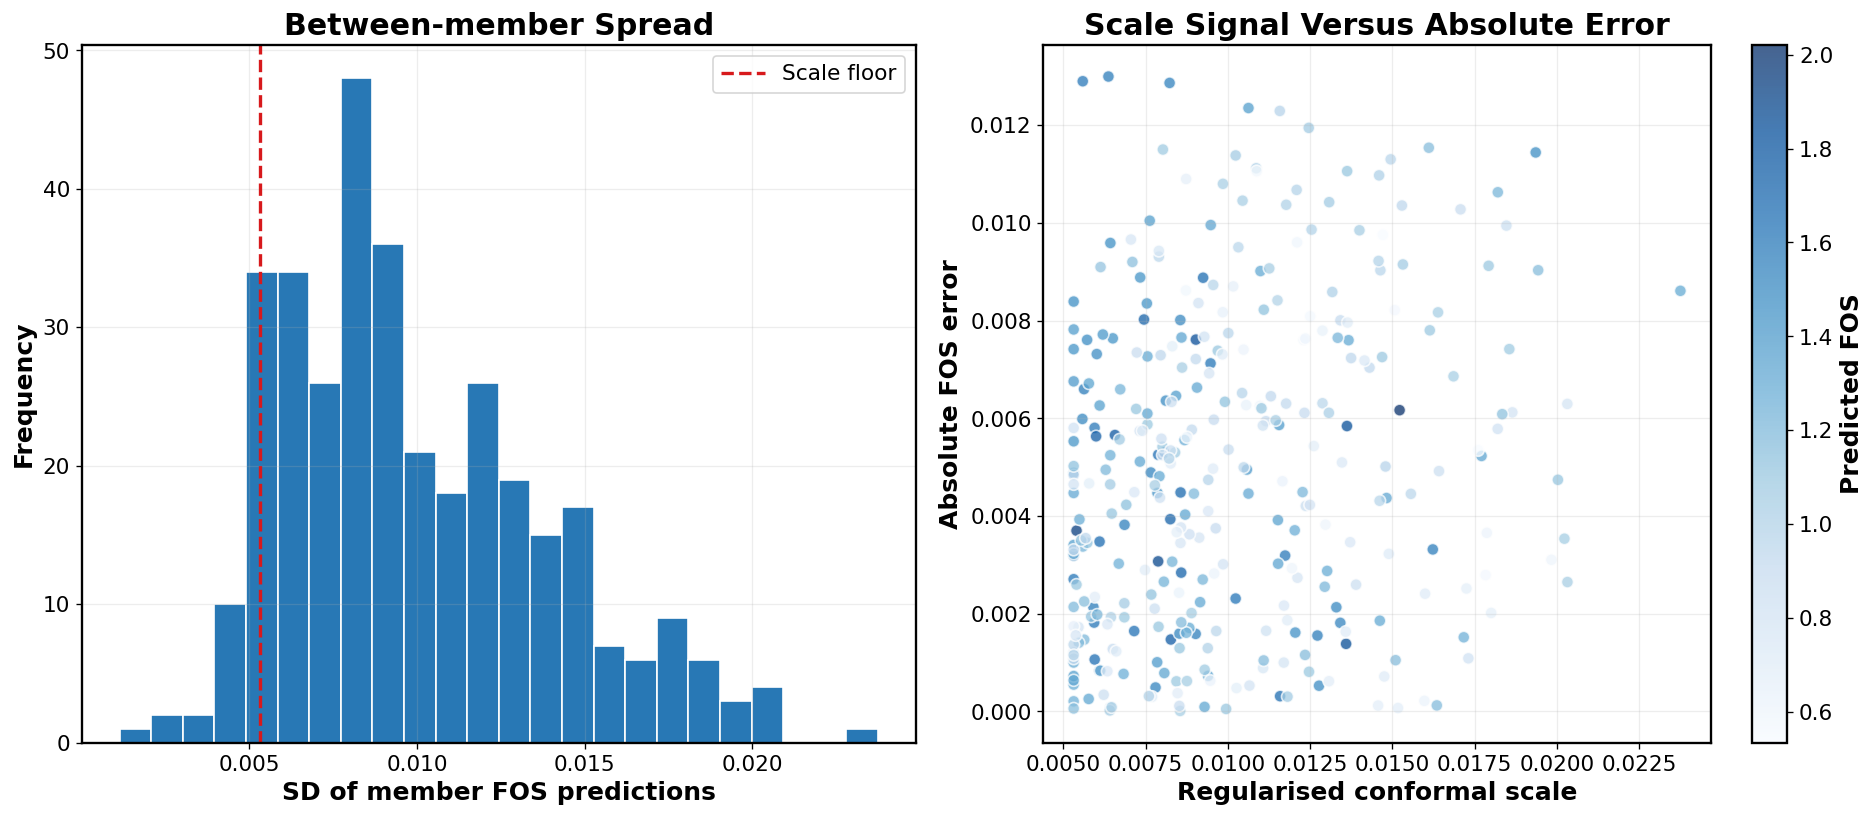

In [35]:
headline_member_sd = np.sqrt(headline_result["epistemic_variance"])
headline_scale = headline_result["conformal_scale"]

uncertainty_table = pd.DataFrame({
    "Quantity": [
        "Between-member SD",
        "Regularised conformal scale",
        "90% profile-wise PI width",
        "95% profile-wise PI width",
    ],
    "Mean": [
        headline_member_sd.mean(),
        headline_scale.mean(),
        np.mean(headline_result["upper_90"] - headline_result["lower_90"]),
        np.mean(headline_result["upper_95"] - headline_result["lower_95"]),
    ],
    "Median": [
        np.median(headline_member_sd),
        np.median(headline_scale),
        np.median(headline_result["upper_90"] - headline_result["lower_90"]),
        np.median(headline_result["upper_95"] - headline_result["lower_95"]),
    ],
    "Maximum": [
        headline_member_sd.max(),
        headline_scale.max(),
        np.max(headline_result["upper_90"] - headline_result["lower_90"]),
        np.max(headline_result["upper_95"] - headline_result["lower_95"]),
    ],
})
show_table(uncertainty_table, caption="Ensemble spread and conformal interval efficiency")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].hist(headline_member_sd, bins=24, color="#2878B5", edgecolor="white")
axes[0].axvline(HEADLINE_SCALE_FLOOR, color="#D7191C", linestyle="--", linewidth=2, label="Scale floor")
axes[0].set_title("Between-member Spread")
axes[0].set_xlabel("SD of member FOS predictions")
axes[0].set_ylabel("Frequency")
axes[0].legend()

axes[1].scatter(headline_scale, np.abs(headline_result["mean"] - Y_TEST), c=headline_result["mean"], cmap="Blues", s=52, alpha=0.75, edgecolor="white")
axes[1].set_title("Scale Signal Versus Absolute Error")
axes[1].set_xlabel("Regularised conformal scale")
axes[1].set_ylabel("Absolute FOS error")
colourbar = fig.colorbar(axes[1].collections[0], ax=axes[1])
colourbar.set_label("Predicted FOS", fontsize=FONT_LABEL, fontweight="bold")

for axis in axes:
    axis.grid(alpha=0.22)
fig.tight_layout()
save_figure(fig, DIRS["uncertainty"], "Supplementary_Figure_Ensemble_Spread")
plt.show()
plt.close(fig)

uncertainty_table.to_csv(DIRS["tables"] / "Table_Ensemble_Spread_and_Conformal_Efficiency.csv", index=False)


## 9. Physical Consistency and Sensitivity Analysis

### 9.1 Quantify monotonicity-violation rates

The audit uses development-domain observations and finite increases of 2%, 5% and 10% of each predictor range. Expected directions are positive for $c$ and $\phi$, and negative for $\gamma$, $H$ and $eta$. Moisture is not assigned a universal monotonic direction because its role depends on how the source FOS values were generated.

In [36]:
audit_sample = development_df.sample(n=min(500, len(development_df)), random_state=SEED).copy()
X_AUDIT = audit_sample[FEATURES].to_numpy(dtype=np.float32)
AUDIT_FRACTIONS = [0.02, 0.05, 0.10]
MONOTONIC_FEATURES = {"c": 1.0, "phi": 1.0, "gamma": -1.0, "H": -1.0, "beta": -1.0}
PHYSICS_TOLERANCE_FOS = 1e-4
monotonicity_rows = []

for configuration_key, specification in CONFIGURATIONS.items():
    base = predict_configuration(
        models_by_configuration[configuration_key], FINAL_PROCESSOR, X_AUDIT,
        FINAL_Y_MEAN, FINAL_Y_SCALE, specification["heteroscedastic"],
    )["mean"]

    for feature, direction in MONOTONIC_FEATURES.items():
        feature_index = FEATURES.index(feature)
        feature_min, feature_max = FINAL_PROCESSOR.bounds[feature_index]
        feature_range = feature_max - feature_min

        for fraction in AUDIT_FRACTIONS:
            changed_x = X_AUDIT.copy()
            changed_x[:, feature_index] = np.minimum(
                changed_x[:, feature_index] + fraction * feature_range,
                feature_max,
            )
            valid = changed_x[:, feature_index] > X_AUDIT[:, feature_index] + 1e-9
            changed = predict_configuration(
                models_by_configuration[configuration_key], FINAL_PROCESSOR, changed_x,
                FINAL_Y_MEAN, FINAL_Y_SCALE, specification["heteroscedastic"],
            )["mean"]
            signed_change = direction * (changed - base)
            violation_rate = 100 * np.mean(signed_change[valid] < -PHYSICS_TOLERANCE_FOS)
            monotonicity_rows.append({
                "Configuration key": configuration_key,
                "Configuration": specification["label"],
                "Predictor": SYMBOL_MAP[feature],
                "Perturbation (% of range)": 100 * fraction,
                "Valid comparisons": int(valid.sum()),
                "Violation rate (%)": violation_rate,
                "Mean signed response": signed_change[valid].mean(),
            })

monotonicity_table = pd.DataFrame(monotonicity_rows)
overall_violation = (
    monotonicity_table.groupby(["Configuration key", "Configuration"], as_index=False)["Violation rate (%)"]
    .mean()
    .rename(columns={"Violation rate (%)": "Mean violation rate (%)"})
)

show_table(monotonicity_table, caption="Finite-perturbation monotonicity audit")
show_table(overall_violation[["Configuration", "Mean violation rate (%)"]], caption="Overall physical-consistency comparison")

monotonicity_table.to_csv(DIRS["tables"] / "Table_Monotonicity_Audit.csv", index=False)
overall_violation.to_csv(DIRS["tables"] / "Table_Overall_Monotonicity_Violation.csv", index=False)

manuscript_ablation_table = performance_table.merge(overall_violation, on=["Configuration key", "Configuration"], how="left")
manuscript_columns = [
    "Configuration", "R²", "RMSE", "MAE", "MAPE (%)", "Pearson r", "Bias",
    "Mean violation rate (%)", "Observation PICP 90%", "Profile PICP 90%", "MPIW 90%", "Observation PICP 95%", "Profile PICP 95%", "MPIW 95%",
]
show_table(manuscript_ablation_table[manuscript_columns], caption="Manuscript-ready ablation performance table")
manuscript_ablation_table.to_excel(DIRS["tables"] / "Table_Physics_Coverage_Ablation.xlsx", index=False)
with pd.ExcelWriter(
    DIRS["tables"] / "Table_Main_Physics_Uncertainty_Safety_Audit.xlsx"
) as writer:
    manuscript_ablation_table.to_excel(writer, sheet_name="Model and physics audit", index=False)
    bootstrap_audit.to_excel(writer, sheet_name="Coverage and RMSE", index=False)
    safety_decision_table.to_excel(writer, sheet_name="Point safety decisions", index=False)
    interval_decision_table.to_excel(writer, sheet_name="Interval decisions", index=False)


,Configuration key,Configuration,Predictor,Perturbation (% of range),Valid comparisons,Violation rate (%),Mean signed response
0,standard_mlp,Baseline MLP,c,2.0000,494,0.0000,0.0066
1,standard_mlp,Baseline MLP,c,5.0000,494,0.0000,0.0163
2,standard_mlp,Baseline MLP,c,10.0000,494,0.0000,0.0326
3,standard_mlp,Baseline MLP,φ,2.0000,494,0.0000,0.0182
4,standard_mlp,Baseline MLP,φ,5.0000,494,0.0000,0.0451
5,standard_mlp,Baseline MLP,φ,10.0000,494,0.0000,0.0891
6,standard_mlp,Baseline MLP,γ,2.0000,499,0.2004,0.0014
7,standard_mlp,Baseline MLP,γ,5.0000,499,0.4008,0.0035
8,standard_mlp,Baseline MLP,γ,10.0000,499,0.6012,0.0067
9,standard_mlp,Baseline MLP,H,2.0000,397,0.0000,0.0029


,Configuration,Mean violation rate (%)
0,Physics-Guided Heteroscedastic MLP,0.0000
1,Physics-Guided Homoscedastic MLP,0.0000
2,Baseline MLP,0.0802
3,Heteroscedastic MLP,0.0000


,Configuration,R²,RMSE,MAE,MAPE (%),Pearson r,Bias,Mean violation rate (%),Observation PICP 90%,Profile PICP 90%,MPIW 90%,Observation PICP 95%,Profile PICP 95%,MPIW 95%
0,Baseline MLP,0.9997,0.0060,0.0047,0.5062,0.9999,0.0038,0.0802,—,—,—,—,—,—
1,PGUC-MLP,0.9997,0.0058,0.0049,0.4879,0.9998,0.0005,—,99.7101,95.6522,0.0440,100.0000,100.0000,0.0481
2,Heteroscedastic MLP,0.9995,0.0071,0.0059,0.6310,0.9999,0.0028,0.0000,—,—,—,—,—,—
3,Physics-Guided Heteroscedastic MLP,0.9995,0.0070,0.0057,0.6180,0.9999,0.0028,0.0000,—,—,—,—,—,—


### 9.2 Display physical-consistency comparison

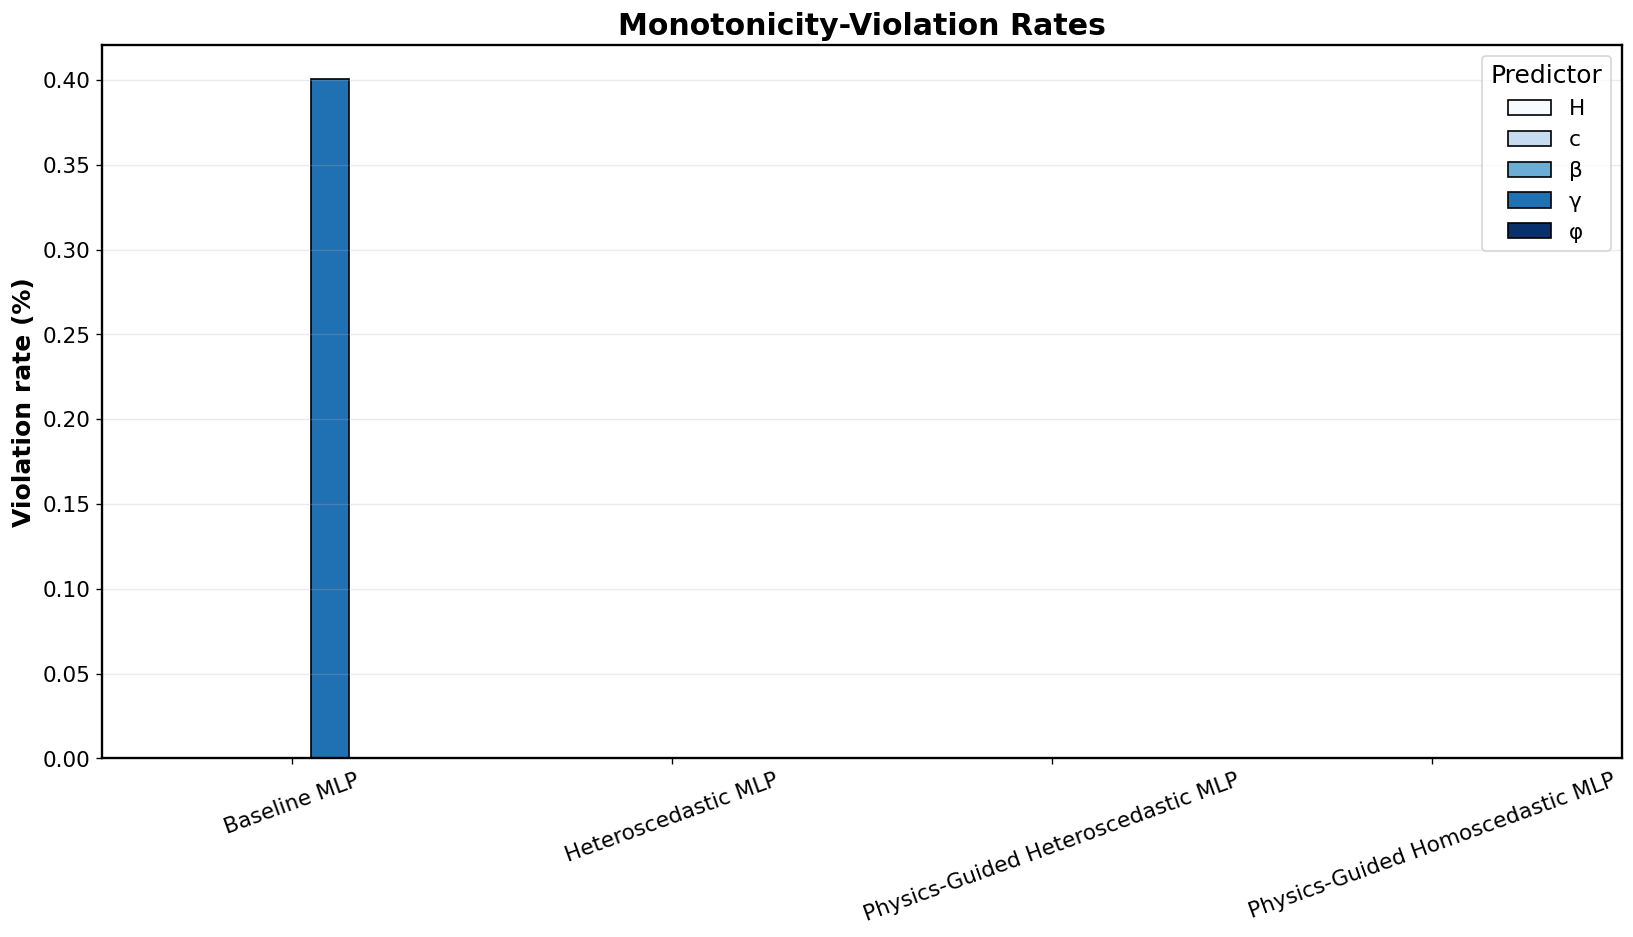

In [37]:
violation_plot = monotonicity_table.groupby(["Configuration", "Predictor"], as_index=False)["Violation rate (%)"].mean()
plot_matrix = violation_plot.pivot(index="Configuration", columns="Predictor", values="Violation rate (%)")

if plot_matrix.to_numpy().max() > 0:
    fig, ax = plt.subplots(figsize=(14, 8))
    plot_matrix.plot(kind="bar", ax=ax, colormap="Blues", edgecolor="black")
    ax.set_title("Monotonicity-Violation Rates")
    ax.set_xlabel("")
    ax.set_ylabel("Violation rate (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Predictor", fontsize=FONT_TICK, title_fontsize=FONT_LABEL)
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    save_figure(fig, DIRS["sensitivity"], "Figure_11_Monotonicity_Violation_Rates")
    plt.show()
    plt.close(fig)
else:
    print("All audited configurations recorded zero violations; the zero-information bar chart was omitted.")

### 9.3 Predictor-response sensitivity curves

Each curve is an average response over a fixed development-domain reference sample. Shaded regions show mean 95% profile-wise conformal limits for PGUC-MLP. These are model-response diagnostics, not causal effects.


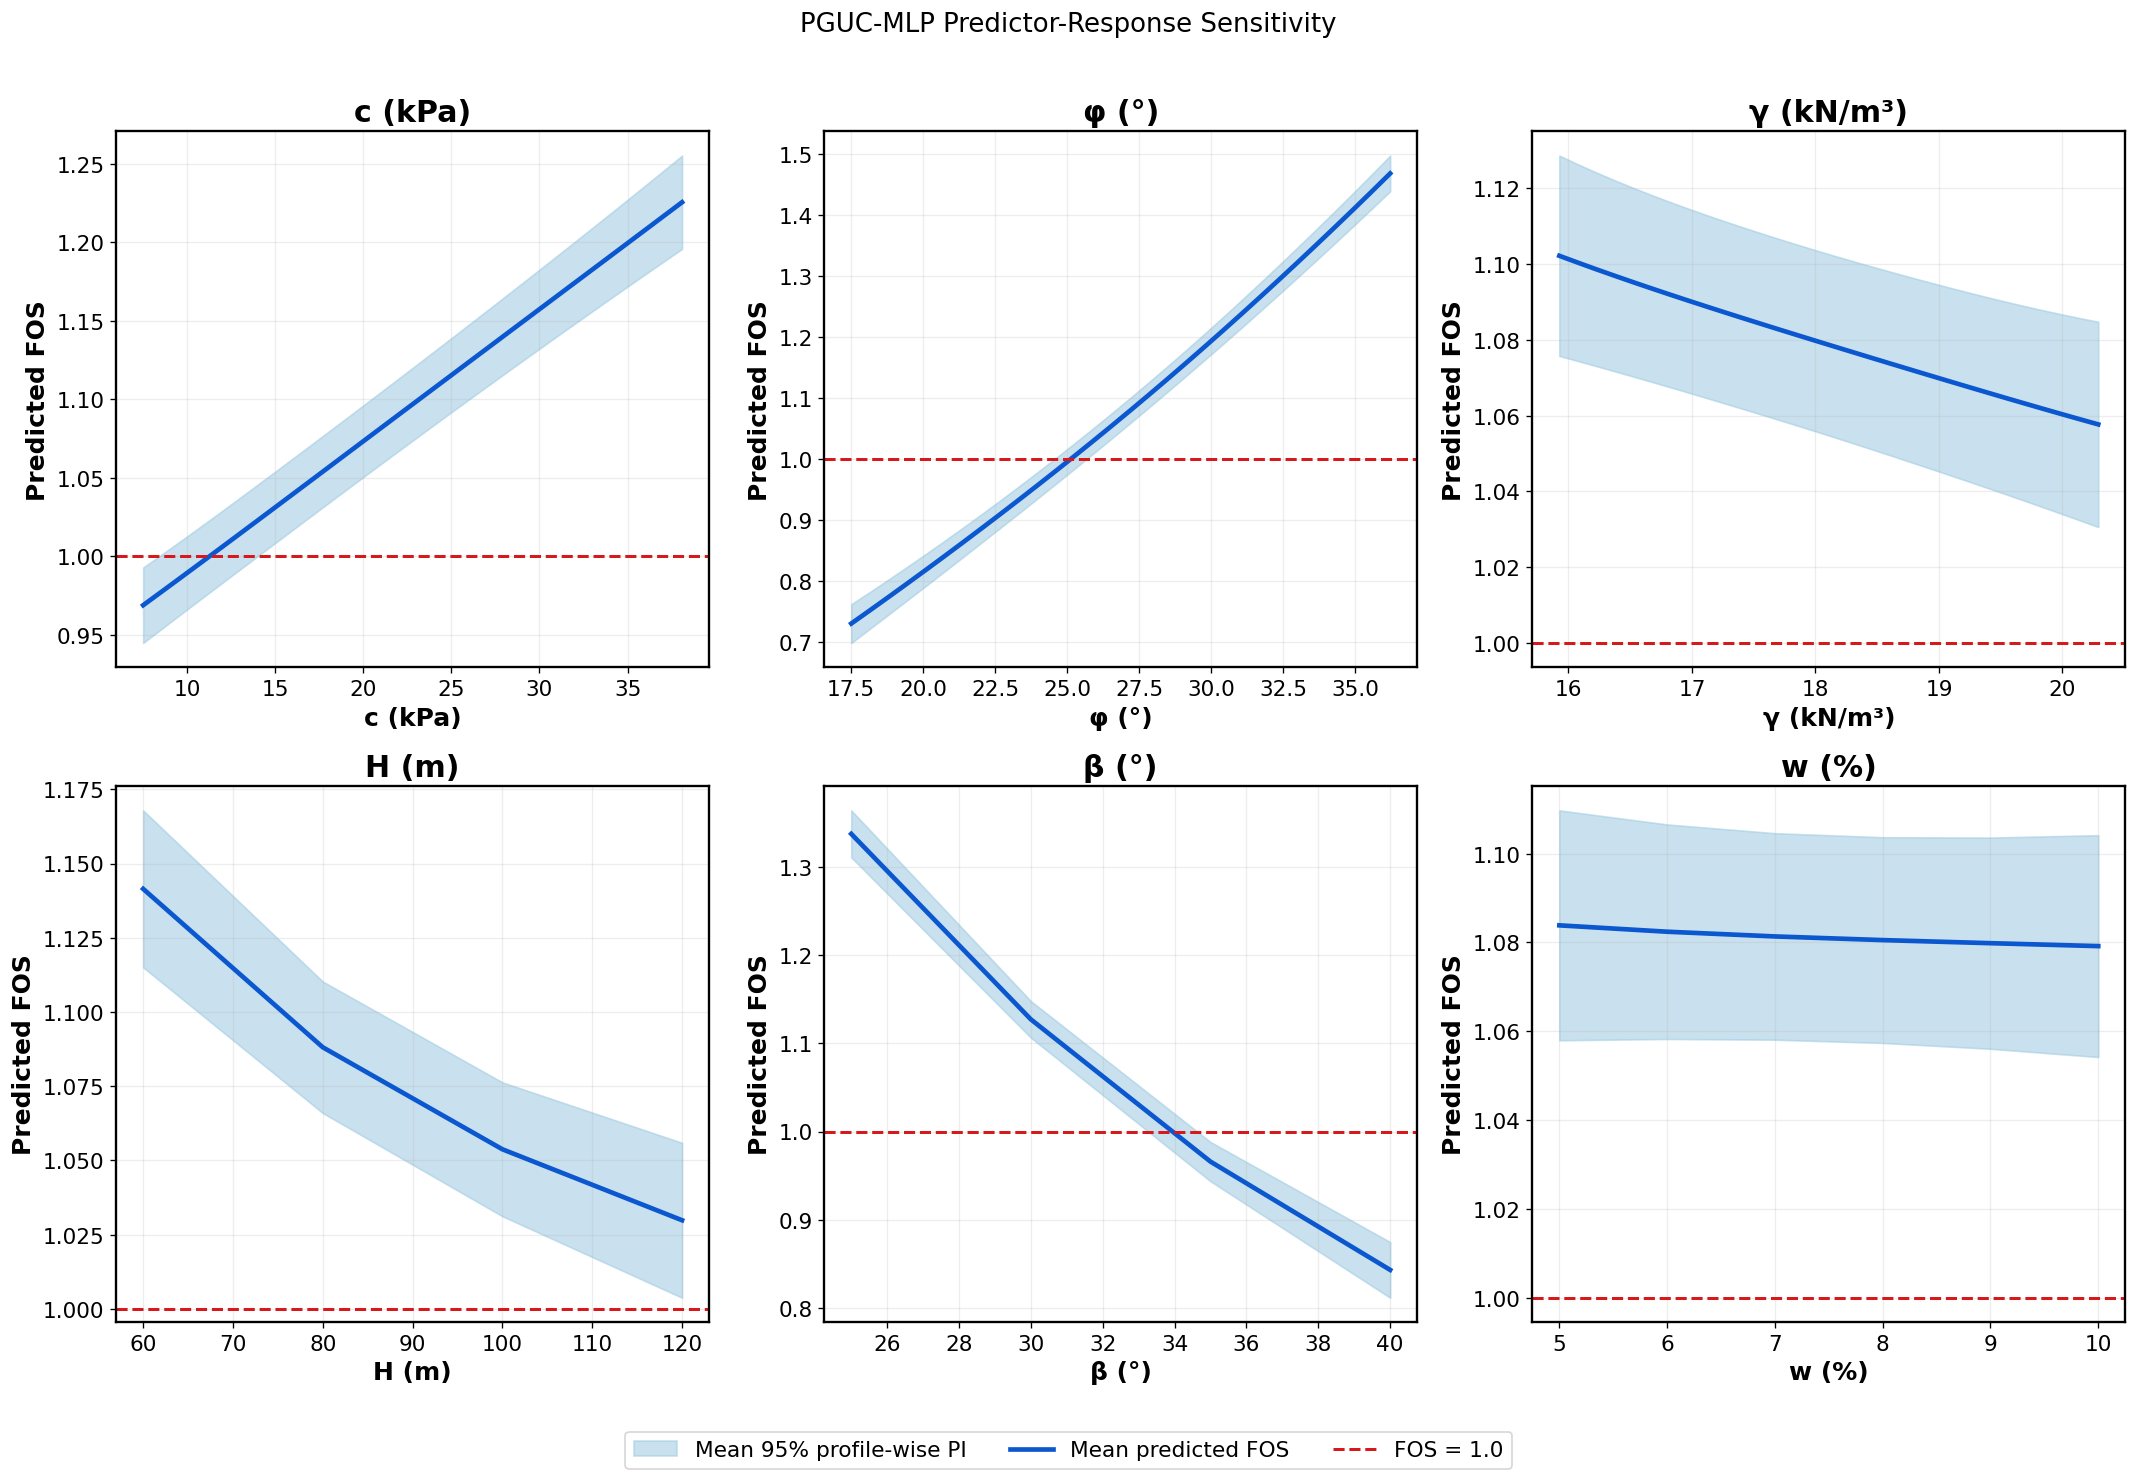

In [38]:
reference_sample = development_df.sample(n=min(300, len(development_df)), random_state=SEED + 1)
X_REFERENCE = reference_sample[FEATURES].to_numpy(dtype=np.float32)
q95_scalar = calibration_objects[HEADLINE_MODEL_KEY]["quantiles"][0.95]["quantile"]
sensitivity_rows = []

for feature_index, feature in enumerate(FEATURES):
    if feature in {"H", "beta", "w"}:
        grid = np.sort(development_df[feature].unique())
    else:
        grid = np.linspace(
            np.quantile(X_DEVELOPMENT[:, feature_index], 0.05),
            np.quantile(X_DEVELOPMENT[:, feature_index], 0.95),
            30,
        )
    for value in grid:
        changed_x = X_REFERENCE.copy()
        changed_x[:, feature_index] = value
        result = predict_configuration(
            models_by_configuration[HEADLINE_MODEL_KEY], FINAL_PROCESSOR, changed_x,
            FINAL_Y_MEAN, FINAL_Y_SCALE, CONFIGURATIONS[HEADLINE_MODEL_KEY]["heteroscedastic"],
        )
        local_scale = regularise_ensemble_scale(result["total_sigma"], HEADLINE_SCALE_FLOOR)
        lower_limit = result["mean"] - q95_scalar * local_scale
        upper_limit = result["mean"] + q95_scalar * local_scale
        sensitivity_rows.append({
            "Predictor": feature,
            "Value": value,
            "Mean predicted FOS": result["mean"].mean(),
            "Mean lower 95% profile-wise PI": np.mean(lower_limit),
            "Mean upper 95% profile-wise PI": np.mean(upper_limit),
        })

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(DIRS["tables"] / "Table_Predictor_Response_Sensitivity.csv", index=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for axis, feature in zip(axes.ravel(), FEATURES):
    subset = sensitivity_table[sensitivity_table["Predictor"] == feature]
    x_values = subset["Value"].to_numpy()
    mean_values = subset["Mean predicted FOS"].to_numpy()
    lower_values = subset["Mean lower 95% profile-wise PI"].to_numpy()
    upper_values = subset["Mean upper 95% profile-wise PI"].to_numpy()
    axis.fill_between(x_values, lower_values, upper_values, color="#9ECAE1", alpha=0.55, label="Mean 95% profile-wise PI")
    axis.plot(x_values, mean_values, color="#0B57D0", linewidth=2.8, label="Mean predicted FOS")
    axis.axhline(1.0, color="#D7191C", linestyle="--", linewidth=1.8, label="FOS = 1.0")
    axis.set_title(DISPLAY_LABELS[feature])
    axis.set_xlabel(DISPLAY_LABELS[feature])
    axis.set_ylabel("Predicted FOS")
    axis.grid(alpha=0.22)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("PGUC-MLP Predictor-Response Sensitivity", y=1.01)
fig.tight_layout(rect=[0, 0.04, 1, 1])
save_figure(fig, DIRS["sensitivity"], "Figure_05_Predictor_Response_Sensitivity")
plt.show()
plt.close(fig)


### 9.4 Moisture-content perturbation analysis

,Moisture perturbation (percentage points),Mean ΔFOS,Mean between-member SD,Mean 95% profile-wise PI width
0,-2.0000,0.0013,0.0101,0.0488
1,-1.0000,0.0007,0.0100,0.0481
2,-0.5000,0.0003,0.0099,0.0480
3,0.5000,-0.0004,0.0099,0.0480
4,1.0000,-0.0007,0.0100,0.0482
5,2.0000,-0.0012,0.0101,0.0487


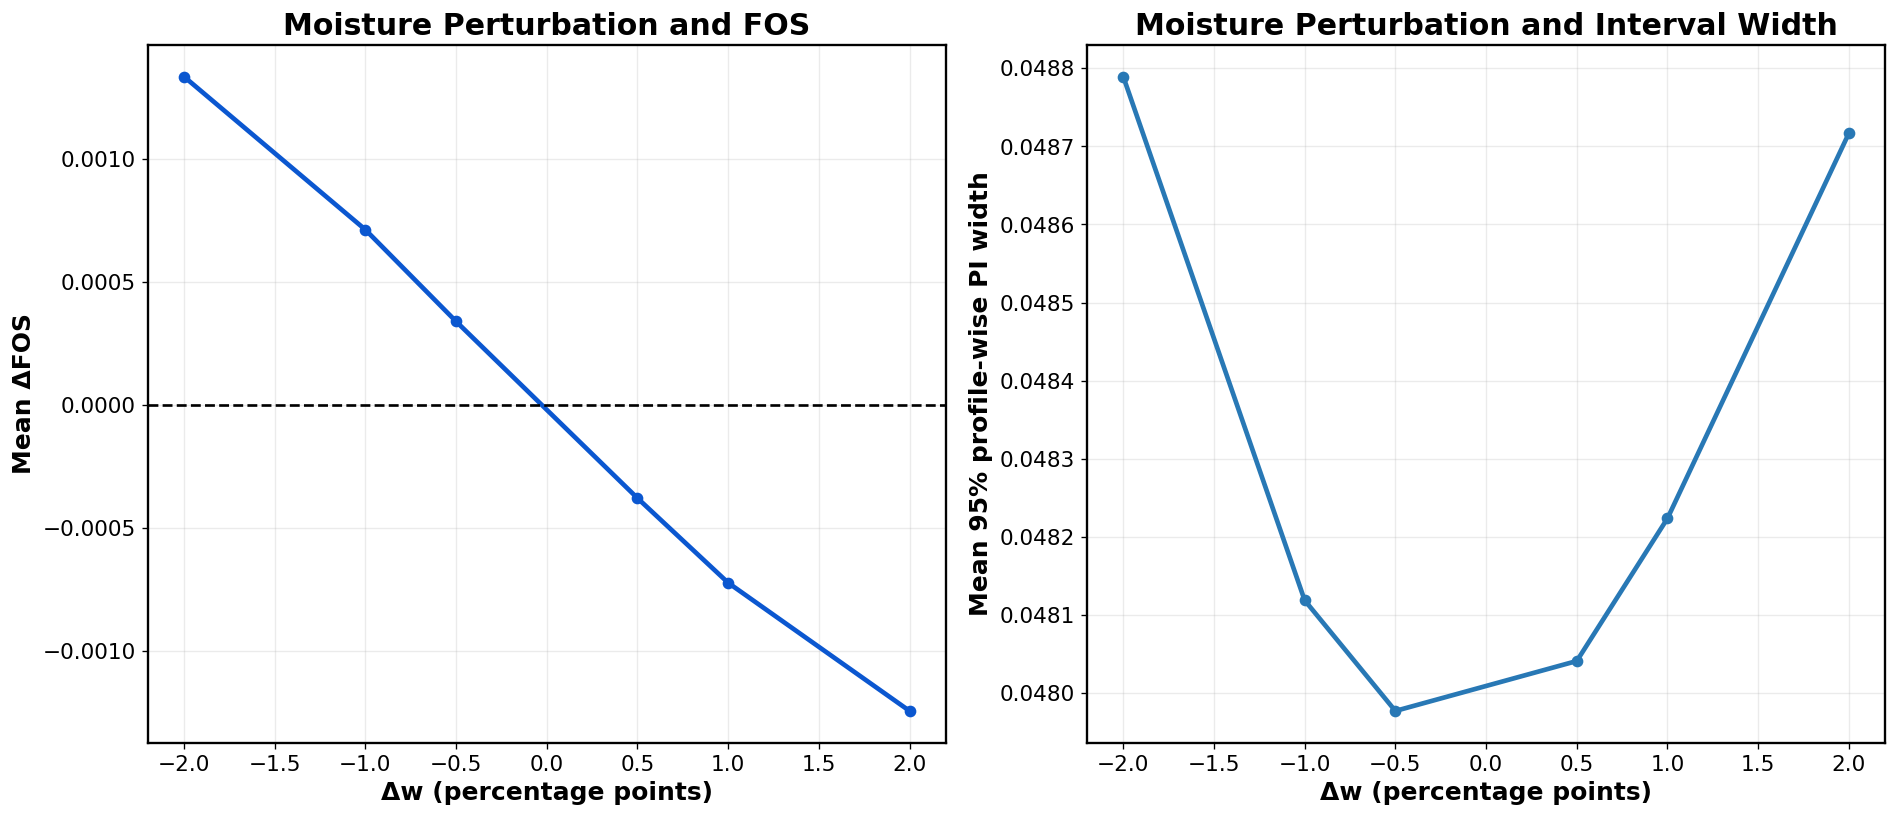

In [39]:
moisture_deltas = [-2.0, -1.0, -0.5, 0.5, 1.0, 2.0]
moisture_index = FEATURES.index("w")
moisture_min, moisture_max = FINAL_PROCESSOR.bounds[moisture_index]

moisture_reference = development_df.sample(n=min(500, len(development_df)), random_state=SEED + 2)
X_MOISTURE = moisture_reference[FEATURES].to_numpy(dtype=np.float32)

base_moisture_result = predict_configuration(
    models_by_configuration[HEADLINE_MODEL_KEY], FINAL_PROCESSOR, X_MOISTURE,
    FINAL_Y_MEAN, FINAL_Y_SCALE, CONFIGURATIONS[HEADLINE_MODEL_KEY]["heteroscedastic"],
)

moisture_rows = []
for delta in moisture_deltas:
    changed_x = X_MOISTURE.copy()
    changed_x[:, moisture_index] = np.clip(changed_x[:, moisture_index] + delta, moisture_min, moisture_max)
    result = predict_configuration(
        models_by_configuration[HEADLINE_MODEL_KEY], FINAL_PROCESSOR, changed_x,
        FINAL_Y_MEAN, FINAL_Y_SCALE, CONFIGURATIONS[HEADLINE_MODEL_KEY]["heteroscedastic"],
    )
    local_scale = regularise_ensemble_scale(result["total_sigma"], HEADLINE_SCALE_FLOOR)
    interval_width = 2 * q95_scalar * local_scale
    moisture_rows.append({
        "Moisture perturbation (percentage points)": delta,
        "Mean ΔFOS": np.mean(result["mean"] - base_moisture_result["mean"]),
        "Mean between-member SD": np.mean(np.sqrt(result["epistemic_variance"])),
        "Mean 95% profile-wise PI width": np.mean(interval_width),
    })

moisture_table = pd.DataFrame(moisture_rows)
show_table(moisture_table, caption="Moisture-content perturbation sensitivity")
moisture_table.to_excel(DIRS["tables"] / "Table_Moisture_Perturbation_Sensitivity.xlsx", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].plot(moisture_table.iloc[:, 0], moisture_table["Mean ΔFOS"], marker="o", linewidth=2.8, color="#0B57D0")
axes[0].axhline(0, color="black", linestyle="--", linewidth=1.6)
axes[0].set_title("Moisture Perturbation and FOS")
axes[0].set_xlabel("Δw (percentage points)")
axes[0].set_ylabel("Mean ΔFOS")

axes[1].plot(moisture_table.iloc[:, 0], moisture_table["Mean 95% profile-wise PI width"], marker="o", linewidth=2.8, color="#2878B5")
axes[1].set_title("Moisture Perturbation and Interval Width")
axes[1].set_xlabel("Δw (percentage points)")
axes[1].set_ylabel("Mean 95% profile-wise PI width")

for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
save_figure(fig, DIRS["sensitivity"], "Supplementary_Figure_Moisture_Perturbation")
plt.show()
plt.close(fig)


## 10. SHAP Explainability

### 10.1 Calculate exact six-feature SHAP values

The model wrappers accept only the six original predictors. Mechanics-informed representations are reconstructed internally. All locked test observations are explained against a development-set background.

In [40]:
# ============================================================
# EXACT SHAP ANALYSIS FOR:
# 1. PREDICTED FOS
# 2. PROFILE-WISE CONFORMAL 95% PREDICTION-INTERVAL WIDTH
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Prepare SHAP background and explanation datasets
# ------------------------------------------------------------

background_df = development_df.sample(
    n=min(SHAP_BACKGROUND_SIZE, len(development_df)),
    random_state=SEED,
)[FEATURES]

X_BACKGROUND = background_df.to_numpy(dtype=np.float64)

X_EXPLAIN = test_df[FEATURES].to_numpy(dtype=np.float64)


# ------------------------------------------------------------
# Extract profile-wise 95% conformal quantiles
# ------------------------------------------------------------

def extract_asymmetric_quantiles(quantile_object):
    """
    Extract the lower- and upper-tail conformal quantiles from q95.

    The function supports common dictionary key conventions and
    also handles a nested dictionary containing a 95% entry.
    """

    if not isinstance(quantile_object, dict):
        raise TypeError(
            "q95 must be a dictionary containing separate lower- "
            "and upper-tail conformal quantiles."
        )

    # Common direct key combinations
    possible_key_pairs = [
        ("lower", "upper"),
        ("q_lower", "q_upper"),
        ("lower_q", "upper_q"),
        ("lower_quantile", "upper_quantile"),
        ("q_low", "q_high"),
        ("low", "high"),
        ("lower_tail", "upper_tail"),
    ]

    for lower_key, upper_key in possible_key_pairs:

        if (
            lower_key in quantile_object
            and upper_key in quantile_object
        ):
            lower_value = float(
                np.asarray(
                    quantile_object[lower_key],
                    dtype=float,
                ).squeeze()
            )

            upper_value = float(
                np.asarray(
                    quantile_object[upper_key],
                    dtype=float,
                ).squeeze()
            )

            return lower_value, upper_value

    # Search one level deeper if q95 is nested
    for nested_key, nested_value in quantile_object.items():

        if isinstance(nested_value, dict):

            try:
                return extract_asymmetric_quantiles(nested_value)

            except (KeyError, TypeError, ValueError):
                continue

    raise KeyError(
        "The lower and upper 95% conformal quantiles could not be "
        f"identified. Available q95 keys: {list(quantile_object.keys())}"
    )


q95_lower, q95_upper = extract_asymmetric_quantiles(q95)

if not np.isfinite(q95_lower) or not np.isfinite(q95_upper):
    raise ValueError(
        "The extracted q95 lower and upper quantiles must be finite."
    )

if q95_lower < 0 or q95_upper < 0:
    raise ValueError(
        "The q95 lower and upper quantiles must be non-negative."
    )

print(f"95% lower-tail conformal quantile: {q95_lower:.6f}")
print(f"95% upper-tail conformal quantile: {q95_upper:.6f}")


# ------------------------------------------------------------
# Prediction function for ensemble mean FOS
# ------------------------------------------------------------

def predict_full_mean(x):
    """
    Return the headline PGUC-MLP ensemble mean FOS prediction.
    """

    x = np.atleast_2d(
        np.asarray(x, dtype=np.float32)
    )

    result = predict_configuration(
        models_by_configuration[HEADLINE_MODEL_KEY],
        FINAL_PROCESSOR,
        x,
        FINAL_Y_MEAN,
        FINAL_Y_SCALE,
        CONFIGURATIONS[HEADLINE_MODEL_KEY]["heteroscedastic"],
    )

    return np.asarray(
        result["mean"],
        dtype=float,
    ).reshape(-1)


# ------------------------------------------------------------
# Prediction function for profile-wise conformal 95% PI width
# ------------------------------------------------------------

def predict_full_interval_width(x):
    """
    Return the profile-wise conformal 95% prediction-interval width.

    Lower limit:
        mean - q95_lower * total_sigma

    Upper limit:
        mean + q95_upper * total_sigma

    Width:
        upper limit - lower limit
    """

    x = np.atleast_2d(
        np.asarray(x, dtype=np.float32)
    )

    result = predict_configuration(
        models_by_configuration[HEADLINE_MODEL_KEY],
        FINAL_PROCESSOR,
        x,
        FINAL_Y_MEAN,
        FINAL_Y_SCALE,
        CONFIGURATIONS[HEADLINE_MODEL_KEY]["heteroscedastic"],
    )

    predicted_mean = np.asarray(
        result["mean"],
        dtype=float,
    ).reshape(-1)

    total_sigma = regularise_ensemble_scale(
        np.asarray(result["total_sigma"], dtype=float).reshape(-1),
        HEADLINE_SCALE_FLOOR,
    )

    lower_95 = (
        predicted_mean
        - q95_lower * total_sigma
    )

    upper_95 = (
        predicted_mean
        + q95_upper * total_sigma
    )

    interval_width = upper_95 - lower_95

    return np.asarray(
        interval_width,
        dtype=float,
    ).reshape(-1)


# ------------------------------------------------------------
# Validate prediction-function outputs before running SHAP
# ------------------------------------------------------------

validation_rows = min(5, len(X_EXPLAIN))

mean_validation = predict_full_mean(
    X_EXPLAIN[:validation_rows]
)

width_validation = predict_full_interval_width(
    X_EXPLAIN[:validation_rows]
)

if mean_validation.shape != (validation_rows,):
    raise ValueError(
        "predict_full_mean returned an invalid output shape: "
        f"{mean_validation.shape}"
    )

if width_validation.shape != (validation_rows,):
    raise ValueError(
        "predict_full_interval_width returned an invalid output shape: "
        f"{width_validation.shape}"
    )

if not np.all(np.isfinite(mean_validation)):
    raise ValueError(
        "The FOS prediction function returned non-finite values."
    )

if not np.all(np.isfinite(width_validation)):
    raise ValueError(
        "The interval-width function returned non-finite values."
    )

if np.any(width_validation < 0):
    raise ValueError(
        "Negative 95% prediction-interval widths were produced."
    )

print("Prediction functions validated successfully.")


# ------------------------------------------------------------
# Construct SHAP masker and exact explainers
# ------------------------------------------------------------

masker = shap.maskers.Independent(
    X_BACKGROUND,
    max_samples=len(X_BACKGROUND),
)

mean_explainer = shap.Explainer(
    predict_full_mean,
    masker,
    algorithm="exact",
    feature_names=SYMBOLS,
)

width_explainer = shap.Explainer(
    predict_full_interval_width,
    masker,
    algorithm="exact",
    feature_names=SYMBOLS,
)


# ------------------------------------------------------------
# Calculate exact SHAP values
# ------------------------------------------------------------

exact_max_evals = 2 ** len(FEATURES)

print("\nCalculating exact SHAP values for predicted FOS...")

mean_shap = mean_explainer(
    X_EXPLAIN,
    max_evals=exact_max_evals,
    batch_size=128,
)

print("\nCalculating exact SHAP values for 95% PI width...")

width_shap = width_explainer(
    X_EXPLAIN,
    max_evals=exact_max_evals,
    batch_size=128,
)


# ------------------------------------------------------------
# Standardise SHAP array dimensions
# ------------------------------------------------------------

mean_shap_values = np.asarray(
    mean_shap.values,
    dtype=float,
)

width_shap_values = np.asarray(
    width_shap.values,
    dtype=float,
)

if mean_shap_values.ndim == 3 and mean_shap_values.shape[-1] == 1:
    mean_shap_values = mean_shap_values[:, :, 0]

if width_shap_values.ndim == 3 and width_shap_values.shape[-1] == 1:
    width_shap_values = width_shap_values[:, :, 0]

expected_shape = (
    len(X_EXPLAIN),
    len(FEATURES),
)

if mean_shap_values.shape != expected_shape:
    raise ValueError(
        "Unexpected mean SHAP-value shape. "
        f"Expected {expected_shape}, obtained {mean_shap_values.shape}."
    )

if width_shap_values.shape != expected_shape:
    raise ValueError(
        "Unexpected interval-width SHAP-value shape. "
        f"Expected {expected_shape}, obtained {width_shap_values.shape}."
    )


# ------------------------------------------------------------
# Check SHAP additivity for predicted FOS
# ------------------------------------------------------------

mean_base = np.asarray(
    mean_shap.base_values,
    dtype=float,
).reshape(-1)

if mean_base.size == 1:
    mean_base = np.repeat(
        mean_base,
        len(X_EXPLAIN),
    )

elif mean_base.size != len(X_EXPLAIN):
    raise ValueError(
        "Unexpected number of mean SHAP base values: "
        f"{mean_base.size}"
    )

predicted_fos = predict_full_mean(X_EXPLAIN)

reconstructed_fos = (
    mean_base
    + mean_shap_values.sum(axis=1)
)

mean_additivity_error = np.max(
    np.abs(
        reconstructed_fos
        - predicted_fos
    )
)


# ------------------------------------------------------------
# Check SHAP additivity for 95% PI width
# ------------------------------------------------------------

width_base = np.asarray(
    width_shap.base_values,
    dtype=float,
).reshape(-1)

if width_base.size == 1:
    width_base = np.repeat(
        width_base,
        len(X_EXPLAIN),
    )

elif width_base.size != len(X_EXPLAIN):
    raise ValueError(
        "Unexpected number of interval-width SHAP base values: "
        f"{width_base.size}"
    )

predicted_width = predict_full_interval_width(
    X_EXPLAIN
)

reconstructed_width = (
    width_base
    + width_shap_values.sum(axis=1)
)

width_additivity_error = np.max(
    np.abs(
        reconstructed_width
        - predicted_width
    )
)


# ------------------------------------------------------------
# Create local SHAP results table
# ------------------------------------------------------------

shap_table = test_df[
    ["row_id", *FEATURES, TARGET]
].copy()

shap_table["Predicted FOS"] = predicted_fos

shap_table[
    "Predicted 95% PI width"
] = predicted_width

for feature_index, symbol in enumerate(SYMBOLS):

    shap_table[
        f"SHAP_{symbol}"
    ] = mean_shap_values[:, feature_index]

    shap_table[
        f"SHAP_PI_width_{symbol}"
    ] = width_shap_values[:, feature_index]


# ------------------------------------------------------------
# Export local SHAP results
# ------------------------------------------------------------

shap_table.to_csv(
    DIRS["tables"]
    / "Table_Local_SHAP_Values_All_Test_Cases.csv",
    index=False,
)

shap_table.to_excel(
    DIRS["tables"]
    / "Table_Local_SHAP_Values_All_Test_Cases.xlsx",
    index=False,
)


# ------------------------------------------------------------
# Save SHAP arrays
# ------------------------------------------------------------

np.savez_compressed(
    DIRS["xai"]
    / "PGUC_MLP_Q1_SHAP_Values.npz",

    mean_values=mean_shap_values,
    mean_base_values=mean_base,

    width_values=width_shap_values,
    width_base_values=width_base,

    predicted_fos=predicted_fos,
    predicted_width=predicted_width,

    q95_lower=q95_lower,
    q95_upper=q95_upper,

    data=X_EXPLAIN,
    feature_names=np.asarray(SYMBOLS),
)


# ------------------------------------------------------------
# Create global SHAP-importance table
# ------------------------------------------------------------

shap_global_table = pd.DataFrame({
    "Predictor": SYMBOLS,

    "Mean |SHAP| for FOS":
        np.mean(
            np.abs(mean_shap_values),
            axis=0,
        ),

    "Mean signed SHAP for FOS":
        np.mean(
            mean_shap_values,
            axis=0,
        ),

    "Mean |SHAP| for 95% PI width":
        np.mean(
            np.abs(width_shap_values),
            axis=0,
        ),

    "Mean signed SHAP for 95% PI width":
        np.mean(
            width_shap_values,
            axis=0,
        ),
}).sort_values(
    "Mean |SHAP| for FOS",
    ascending=False,
).reset_index(drop=True)


# ------------------------------------------------------------
# Display and export global results
# ------------------------------------------------------------

show_table(
    shap_global_table,
    caption="Global SHAP importance",
)

print(
    "Maximum FOS SHAP additivity error: "
    f"{mean_additivity_error:.3e}"
)

print(
    "Maximum 95% PI-width SHAP additivity error: "
    f"{width_additivity_error:.3e}"
)

shap_global_table.to_csv(
    DIRS["tables"]
    / "Table_Global_SHAP_Importance.csv",
    index=False,
)

shap_global_table.to_excel(
    DIRS["tables"]
    / "Table_Global_SHAP_Importance.xlsx",
    index=False,
)

print("\nExact SHAP analysis completed successfully.")

95% lower-tail conformal quantile: 2.399655
95% upper-tail conformal quantile: 2.399655
Prediction functions validated successfully.

Calculating exact SHAP values for predicted FOS...


ExactExplainer explainer: 346it [00:38,  7.68it/s]



Calculating exact SHAP values for 95% PI width...


ExactExplainer explainer: 346it [00:34,  7.09it/s]


,Predictor,Mean |SHAP| for FOS,Mean signed SHAP for FOS,Mean |SHAP| for 95% PI width,Mean signed SHAP for 95% PI width
0,φ,0.2136,0.0082,0.0067,0.0020
1,β,0.1596,-0.0271,0.0086,0.0016
2,c,0.0575,0.0061,0.0042,-0.0015
3,H,0.0351,0.0020,0.0044,0.0004
4,γ,0.0083,-0.0021,0.0024,-0.0013
5,w,0.0014,-0.0002,0.0026,-0.0010


Maximum FOS SHAP additivity error: 1.110e-15
Maximum 95% PI-width SHAP additivity error: 2.776e-16

Exact SHAP analysis completed successfully.


### 10.2 Two-panel SHAP beeswarm figure

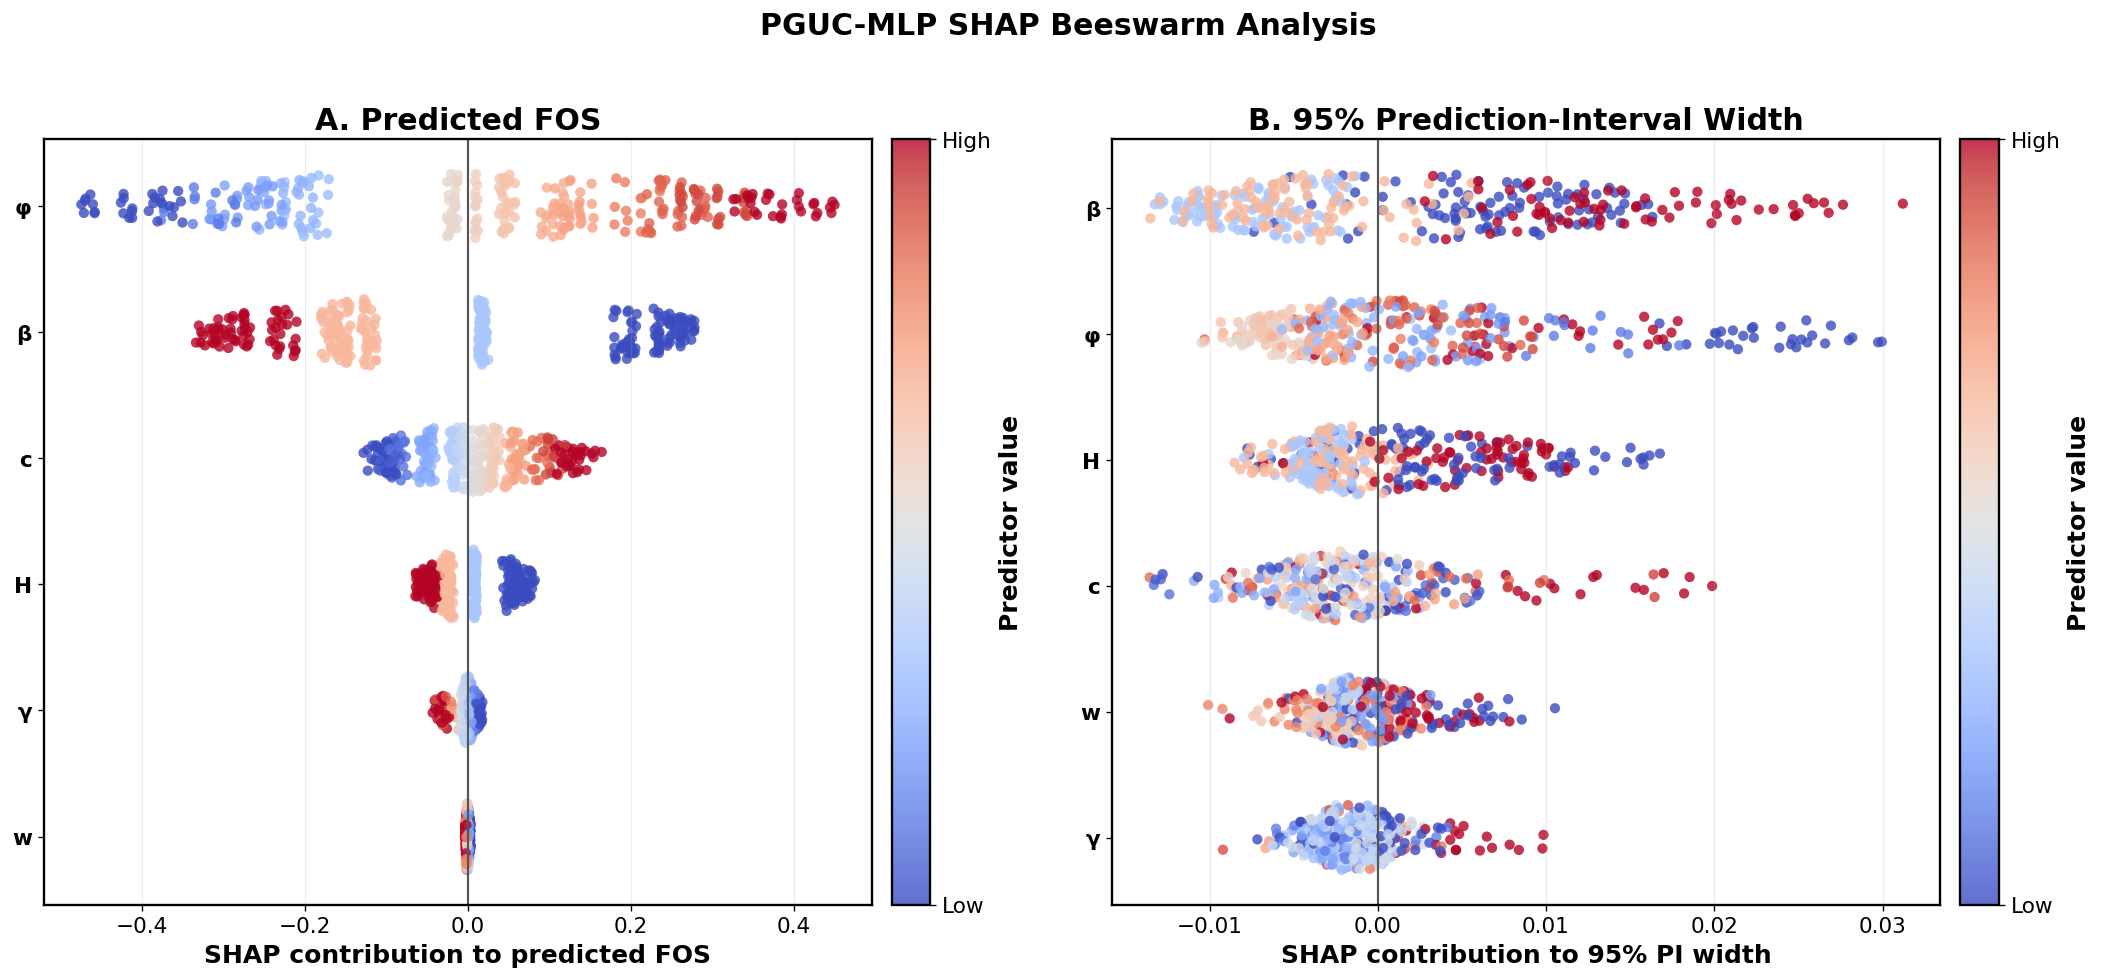

In [41]:
def beeswarm_axis(ax, shap_values, feature_values, title, seed):
    rng = np.random.default_rng(seed)
    order = np.argsort(np.mean(np.abs(shap_values), axis=0))[::-1]
    scatter = None

    for row_position, feature_index in enumerate(order):
        values = shap_values[:, feature_index]
        feature = feature_values[:, feature_index]
        ranks = stats.rankdata(values, method="average") / max(len(values), 1)
        jitter = (rng.random(len(values)) - 0.5) * 0.55 * (0.35 + 0.65 * np.sin(np.pi * ranks))
        lower, upper = np.quantile(feature, [0.05, 0.95])
        normalised = np.clip((feature - lower) / max(upper - lower, 1e-12), 0, 1)
        scatter = ax.scatter(
            values,
            np.full(len(values), row_position) + jitter,
            c=normalised,
            cmap="coolwarm",
            vmin=0,
            vmax=1,
            s=38,
            alpha=0.80,
            edgecolor="none",
        )

    ax.axvline(0, color="#555555", linewidth=1.3)
    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels([SYMBOLS[index] for index in order], fontweight="bold")
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.22)
    return scatter

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
scatter_a = beeswarm_axis(axes[0], mean_shap.values, X_EXPLAIN, "A. Predicted FOS", SEED)
scatter_b = beeswarm_axis(axes[1], width_shap.values, X_EXPLAIN, "B. 95% Prediction-Interval Width", SEED + 1)
axes[0].set_xlabel("SHAP contribution to predicted FOS")
axes[1].set_xlabel("SHAP contribution to 95% PI width")

for axis, scatter in zip(axes, [scatter_a, scatter_b]):
    colourbar = fig.colorbar(scatter, ax=axis, pad=0.02)
    colourbar.set_ticks([0, 1])
    colourbar.set_ticklabels(["Low", "High"])
    colourbar.set_label("Predictor value", fontsize=FONT_LABEL, fontweight="bold")
    colourbar.ax.tick_params(labelsize=FONT_TICK)

fig.suptitle("PGUC-MLP SHAP Beeswarm Analysis", fontsize=FONT_TITLE, fontweight="bold", y=1.02)
fig.tight_layout()
save_figure(fig, DIRS["xai"], "Figure_06_SHAP_Beeswarm_Prediction_and_Interval_Width")
plt.show()
plt.close(fig)

### 10.3 SHAP dependence plots for all predictors

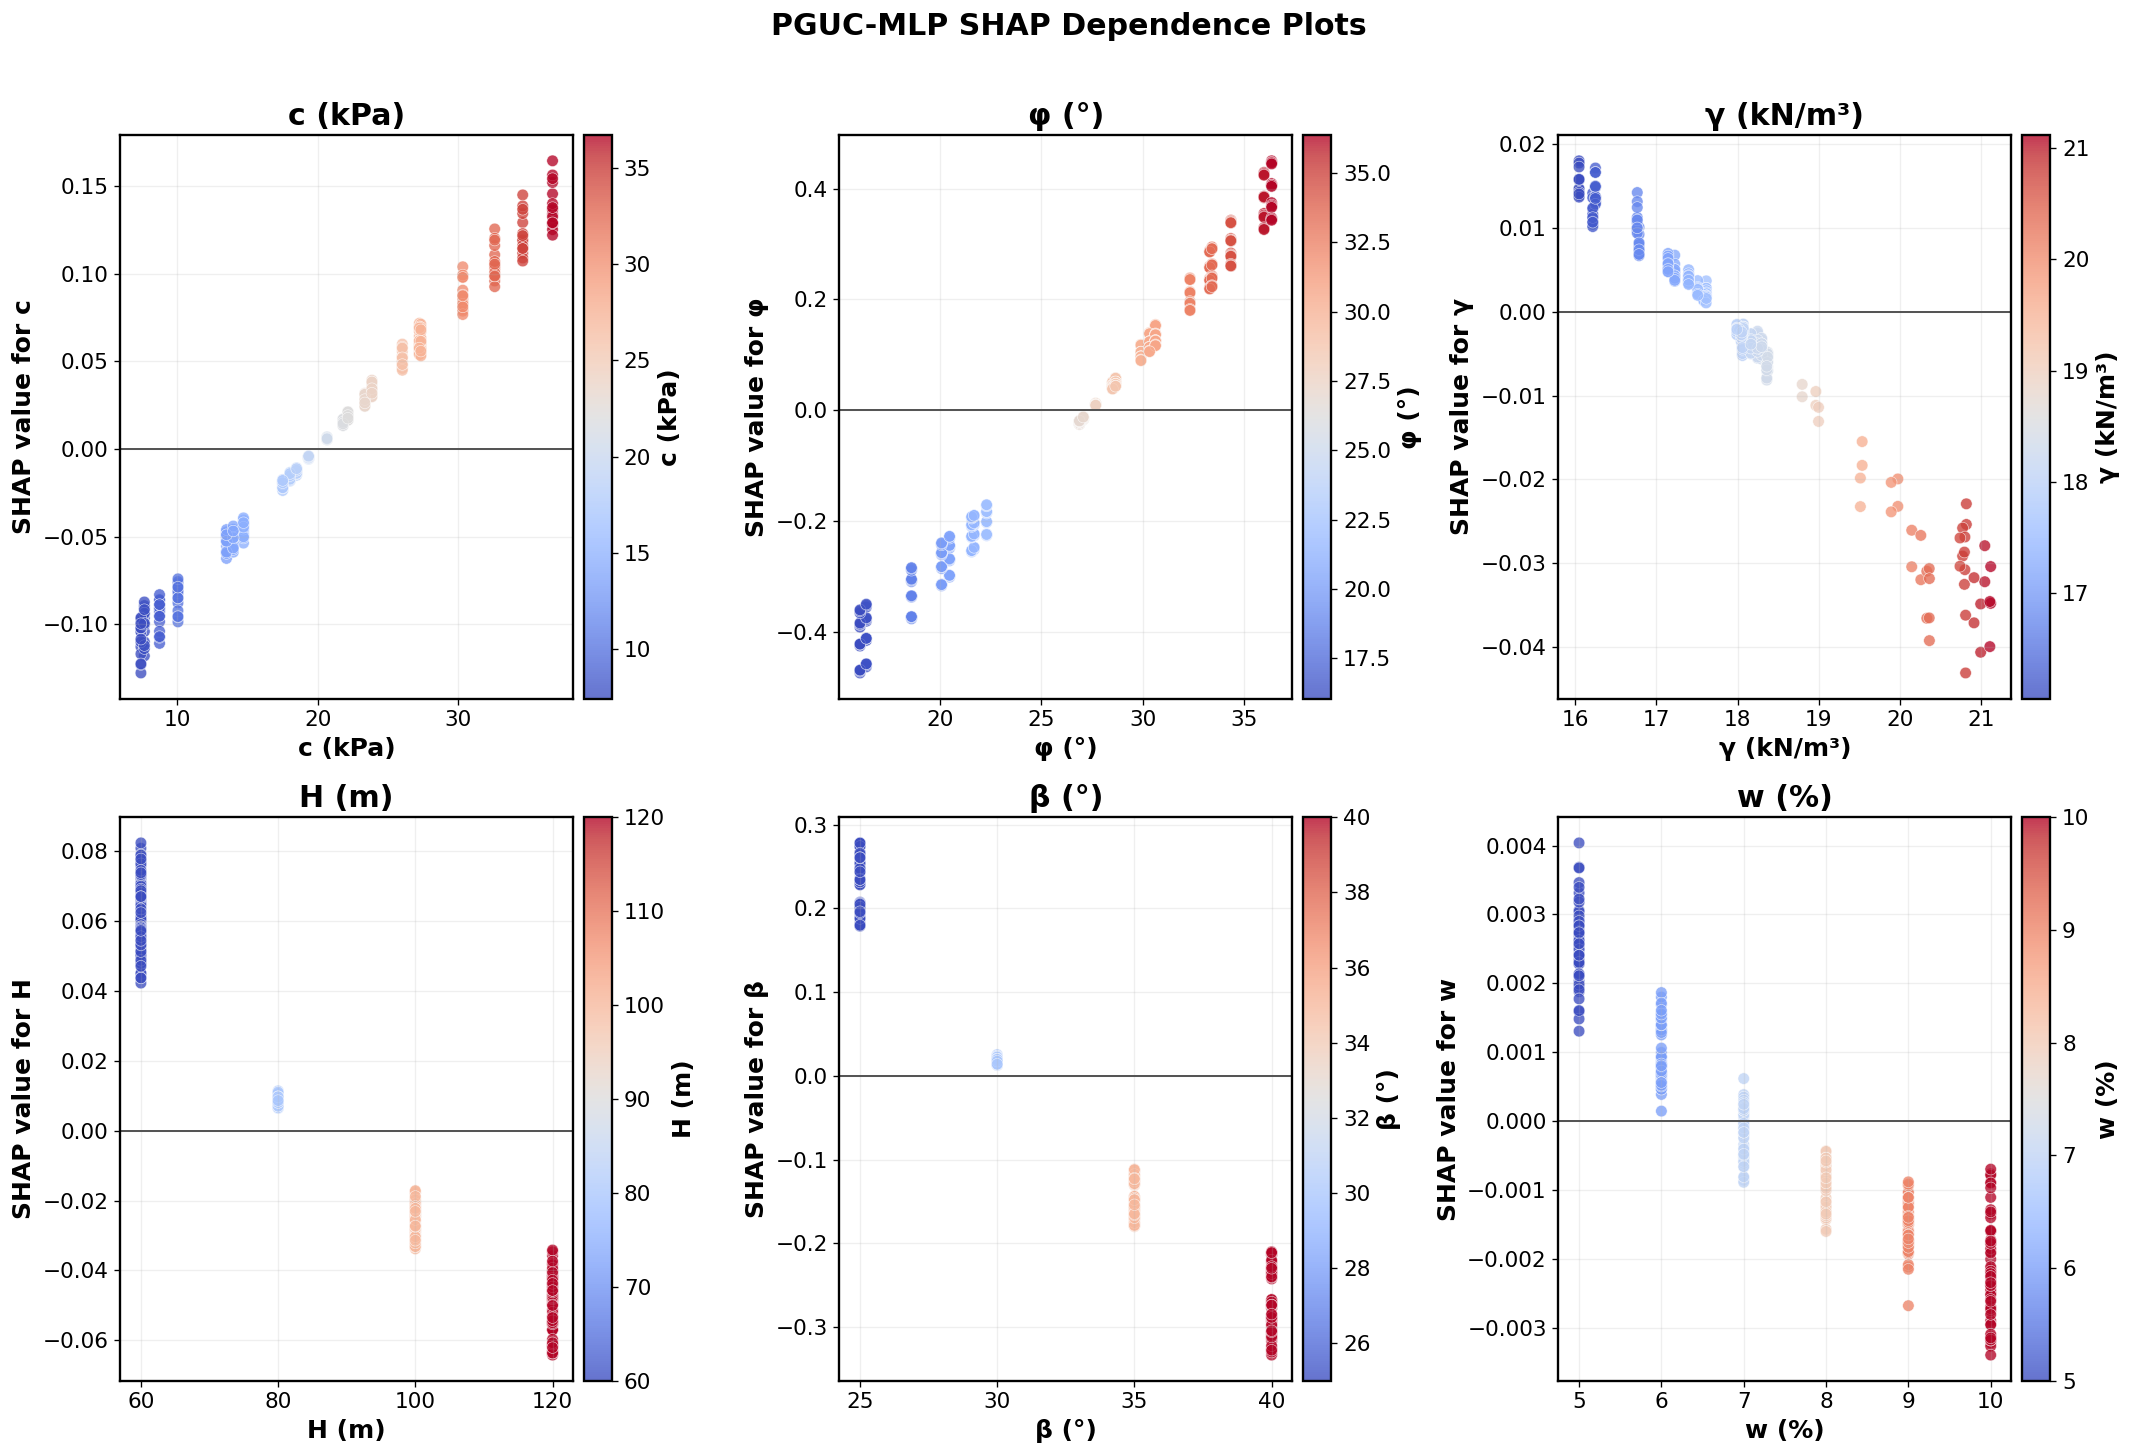

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for feature_index, (axis, feature, symbol) in enumerate(zip(axes.ravel(), FEATURES, SYMBOLS)):
    colour_values = X_EXPLAIN[:, feature_index]
    scatter = axis.scatter(
        X_EXPLAIN[:, feature_index],
        mean_shap.values[:, feature_index],
        c=colour_values,
        cmap="coolwarm",
        s=48,
        alpha=0.78,
        edgecolor="white",
        linewidth=0.35,
    )
    axis.axhline(0, color="#555555", linewidth=1.2)
    axis.set_title(DISPLAY_LABELS[feature])
    axis.set_xlabel(DISPLAY_LABELS[feature])
    axis.set_ylabel(f"SHAP value for {symbol}")
    axis.grid(alpha=0.20)
    colourbar = fig.colorbar(scatter, ax=axis, pad=0.02)
    colourbar.set_label(DISPLAY_LABELS[feature], fontsize=FONT_LABEL, fontweight="bold")
    colourbar.ax.tick_params(labelsize=FONT_TICK)

fig.suptitle("PGUC-MLP SHAP Dependence Plots", fontsize=FONT_TITLE, fontweight="bold", y=1.01)
fig.tight_layout()
save_figure(fig, DIRS["xai"], "Supplementary_Figure_SHAP_Dependence_All_Predictors")
plt.show()
plt.close(fig)

## 11. SHAP-IQ FSII Analysis

### 11.1 Build the order-three FSII explainer

The analysis calculates all 41 effects: 6 main effects, 15 pairwise interactions and 20 third-order interactions. Every test case uses the complete 64-coalition budget with an empirical marginal background.

In [43]:
INTERACTION_KEYS = [
    interaction
    for order in range(1, SHAPIQ_MAX_ORDER + 1)
    for interaction in combinations(range(len(FEATURES)), order)
]

if len(INTERACTION_KEYS) != 41:
    raise RuntimeError(f"Expected 41 order-one to order-three effects, found {len(INTERACTION_KEYS)}.")

def interaction_label(interaction):
    return " × ".join(SYMBOLS[index] for index in interaction)

INTERACTION_LABELS = [interaction_label(interaction) for interaction in INTERACTION_KEYS]
INTERACTION_TO_COLUMN = {interaction: index for index, interaction in enumerate(INTERACTION_KEYS)}

def shapiq_model(x):
    return predict_full_mean(np.atleast_2d(np.asarray(x, dtype=np.float32)))

fsii_explainer = shapiq.TabularExplainer(
    model=shapiq_model,
    data=X_BACKGROUND,
    index="FSII",
    max_order=SHAPIQ_MAX_ORDER,
    imputer="marginal",
    approximator="auto",
    random_state=SEED,
    verbose=False,
    sample_size=min(SHAP_BACKGROUND_SIZE, len(X_BACKGROUND)),
    categorical_features=[],
    joint_marginal_distribution=True,
)

effect_count_table = pd.DataFrame({
    "Order": [1, 2, 3, "Total"],
    "Number of effects": [6, 15, 20, 41],
})
show_table(effect_count_table, precision=0, caption="SHAP-IQ FSII effect structure")

,Order,Number of effects
0,1,6
1,2,15
2,3,20
3,Total,41


### 11.2 Calculate or resume local FSII values for all test observations

In [44]:
fsii_checkpoint = DIRS["shapiq"] / "PGUC_MLP_Q1_Local_FSII_Order3_Checkpoint.npz"
n_test = len(X_EXPLAIN)

if fsii_checkpoint.exists():
    saved = np.load(fsii_checkpoint, allow_pickle=False)
    LOCAL_FSII = saved["values"]
    PROCESSED_FSII = saved["processed"].astype(bool)
    LOCAL_FSII_BASE = saved["baseline"] if "baseline" in saved.files else np.full(n_test, np.nan)
    if "baseline" not in saved.files:
        LOCAL_FSII[:] = np.nan
        PROCESSED_FSII[:] = False
    if LOCAL_FSII.shape != (n_test, len(INTERACTION_KEYS)):
        raise RuntimeError("The saved FSII checkpoint does not match the current test set.")
else:
    LOCAL_FSII = np.full((n_test, len(INTERACTION_KEYS)), np.nan, dtype=np.float64)
    PROCESSED_FSII = np.zeros(n_test, dtype=bool)
    LOCAL_FSII_BASE = np.full(n_test, np.nan, dtype=np.float64)

remaining = np.where(~PROCESSED_FSII)[0]
print(f"Completed: {PROCESSED_FSII.sum():,} | Remaining: {len(remaining):,}")

for iteration, position in enumerate(tqdm(remaining, desc="Order-three FSII"), start=1):
    explanation = fsii_explainer.explain(
        X_EXPLAIN[position],
        budget=SHAPIQ_BUDGET,
        random_state=SEED + int(position),
    )
    values = {tuple(sorted(key)): float(value) for key, value in explanation.dict_values.items()}
    baseline_value = float(getattr(explanation, "baseline_value", np.nan))
    if not np.isfinite(baseline_value):
        raise ValueError("SHAP-IQ did not return a finite baseline value.")
    LOCAL_FSII_BASE[position] = baseline_value
    missing = [key for key in INTERACTION_KEYS if key not in values]
    if missing:
        raise KeyError(f"SHAP-IQ result is missing effects: {missing}")

    for interaction, column_index in INTERACTION_TO_COLUMN.items():
        LOCAL_FSII[position, column_index] = values[interaction]
    PROCESSED_FSII[position] = True

    if iteration % SHAPIQ_CHECKPOINT_EVERY == 0 or iteration == len(remaining):
        np.savez_compressed(
            fsii_checkpoint, values=LOCAL_FSII, baseline=LOCAL_FSII_BASE, processed=PROCESSED_FSII
        )

if not np.isfinite(LOCAL_FSII).all() or not np.isfinite(LOCAL_FSII_BASE).all():
    raise RuntimeError("FSII computation contains missing or infinite values.")

fsii_prediction = shapiq_model(X_EXPLAIN)
fsii_reconstruction = LOCAL_FSII_BASE + LOCAL_FSII.sum(axis=1)
fsii_reconstruction_error = fsii_reconstruction - fsii_prediction
maximum_fsii_reconstruction_error = float(np.max(np.abs(fsii_reconstruction_error)))
if maximum_fsii_reconstruction_error > 1e-5:
    warnings.warn(
        f"Maximum FSII reconstruction error is {maximum_fsii_reconstruction_error:.3e}; "
        "report the observed numerical approximation error explicitly."
    )

fsii_reconstruction_table = pd.DataFrame({
    "row_id": test_df["row_id"].to_numpy(),
    "FSII baseline": LOCAL_FSII_BASE,
    "Sum of order-one to order-three FSII": LOCAL_FSII.sum(axis=1),
    "Reconstructed prediction": fsii_reconstruction,
    "Model prediction": fsii_prediction,
    "Reconstruction error": fsii_reconstruction_error,
})
fsii_reconstruction_table.to_csv(
    DIRS["tables"] / "Table_FSII_Reconstruction_Audit.csv", index=False
)
print(f"Maximum FSII reconstruction error: {maximum_fsii_reconstruction_error:.3e}")

local_fsii_table = pd.DataFrame(LOCAL_FSII, columns=INTERACTION_LABELS)
local_fsii_table.insert(0, "row_id", test_df["row_id"].to_numpy())
local_fsii_table.to_csv(DIRS["tables"] / "Table_Local_FSII_All_Test_Cases.csv", index=False)
local_fsii_table.to_excel(DIRS["tables"] / "Table_Local_FSII_All_Test_Cases.xlsx", index=False)
print("All local FSII values are complete.")

Completed: 345 | Remaining: 0


Order-three FSII: 0it [00:00, ?it/s]

Maximum FSII reconstruction error: 1.228e-13
All local FSII values are complete.


### 11.3 Aggregate and display global FSII effects

In [45]:
global_fsii_rows = []

for column_index, interaction in enumerate(INTERACTION_KEYS):
    values = LOCAL_FSII[:, column_index]
    features = [SYMBOLS[index] for index in interaction]
    global_fsii_rows.append({
        "Feature set": interaction_label(interaction),
        "Order": len(interaction),
        "Feature 1": features[0],
        "Feature 2": features[1] if len(features) >= 2 else "",
        "Feature 3": features[2] if len(features) >= 3 else "",
        "Interaction magnitude": np.mean(np.abs(values)),
        "Mean signed FSII": np.mean(values),
        "FSII SD": np.std(values, ddof=1),
        "Positive fraction": np.mean(values > 0),
        "Negative fraction": np.mean(values < 0),
    })

global_fsii_table = (
    pd.DataFrame(global_fsii_rows)
    .sort_values("Interaction magnitude", ascending=False)
    .reset_index(drop=True)
)
top15_fsii = global_fsii_table.head(15).copy()

show_table(top15_fsii, caption="Top 15 global SHAP-IQ FSII effects")
global_fsii_table.to_csv(DIRS["tables"] / "Table_SHAP_IQ_All_41_FSII_Effects.csv", index=False)
global_fsii_table.to_excel(DIRS["tables"] / "Table_SHAP_IQ_All_41_FSII_Effects.xlsx", index=False)
top15_fsii.to_excel(DIRS["tables"] / "Table_SHAP_IQ_Top15_FSII_Effects.xlsx", index=False)

,Feature set,Order,Feature 1,Feature 2,Feature 3,Interaction magnitude,Mean signed FSII,FSII SD,Positive fraction,Negative fraction
0,φ,1,φ,,,0.2168,0.0089,0.2526,0.5652,0.4348
1,β,1,β,,,0.1589,-0.0257,0.1839,0.5333,0.4667
2,c,1,c,,,0.0574,0.0062,0.0697,0.5217,0.4783
3,φ × β,2,φ,β,,0.0367,-0.0015,0.0493,0.4609,0.5391
4,H,1,H,,,0.0350,0.0035,0.0405,0.5333,0.4667
5,c × H,2,c,H,,0.0093,-0.0007,0.0133,0.4899,0.5101
6,γ,1,γ,,,0.0081,-0.0017,0.0112,0.4522,0.5478
7,c × γ,2,c,γ,,0.0024,0.0007,0.0032,0.7217,0.2783
8,φ × H,2,φ,H,,0.0021,-0.0003,0.0029,0.4029,0.5971
9,c × β,2,c,β,,0.0020,-0.0003,0.0027,0.3971,0.6029


### 11.4 Main-manuscript first- and second-order FSII effects

The main paper reports interpretable main and pairwise effects. The full order-three UpSet view is retained in the supplement.


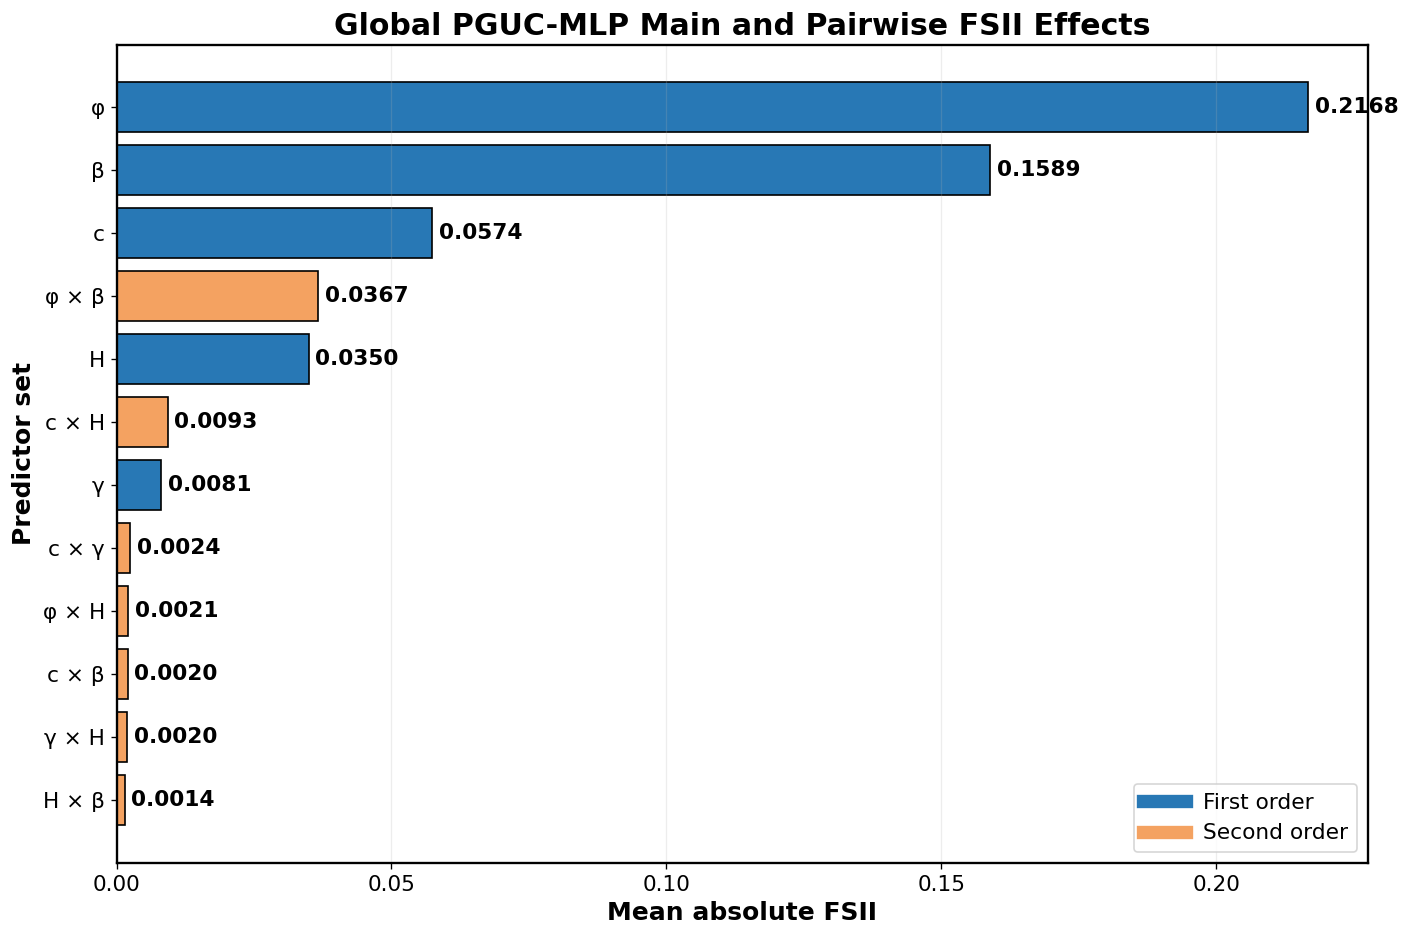

In [46]:
main_pairwise_fsii = (
    global_fsii_table[global_fsii_table["Order"].isin([1, 2])]
    .nlargest(12, "Interaction magnitude")
    .sort_values("Interaction magnitude", ascending=True)
)

order_colours = {1: "#2878B5", 2: "#F4A261"}
fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(
    main_pairwise_fsii["Feature set"],
    main_pairwise_fsii["Interaction magnitude"],
    color=[order_colours[int(order)] for order in main_pairwise_fsii["Order"]],
    edgecolor="black",
)
ax.bar_label(bars, labels=[f"{value:.4f}" for value in main_pairwise_fsii["Interaction magnitude"]], padding=4, fontweight="bold")
ax.set_title("Global PGUC-MLP Main and Pairwise FSII Effects")
ax.set_xlabel("Mean absolute FSII")
ax.set_ylabel("Predictor set")
ax.grid(axis="x", alpha=0.22)
ax.legend(
    handles=[
        Line2D([0], [0], color=order_colours[1], lw=8, label="First order"),
        Line2D([0], [0], color=order_colours[2], lw=8, label="Second order"),
    ],
    frameon=True,
)
fig.tight_layout()
save_figure(fig, DIRS["shapiq"], "Figure_07_FSII_Main_and_Pairwise_Effects")
plt.show()
plt.close(fig)

main_pairwise_fsii.to_excel(DIRS["tables"] / "Table_Main_Manuscript_FSII_Effects.xlsx", index=False)


### 11.5 Supplementary order-three FSII UpSet figure

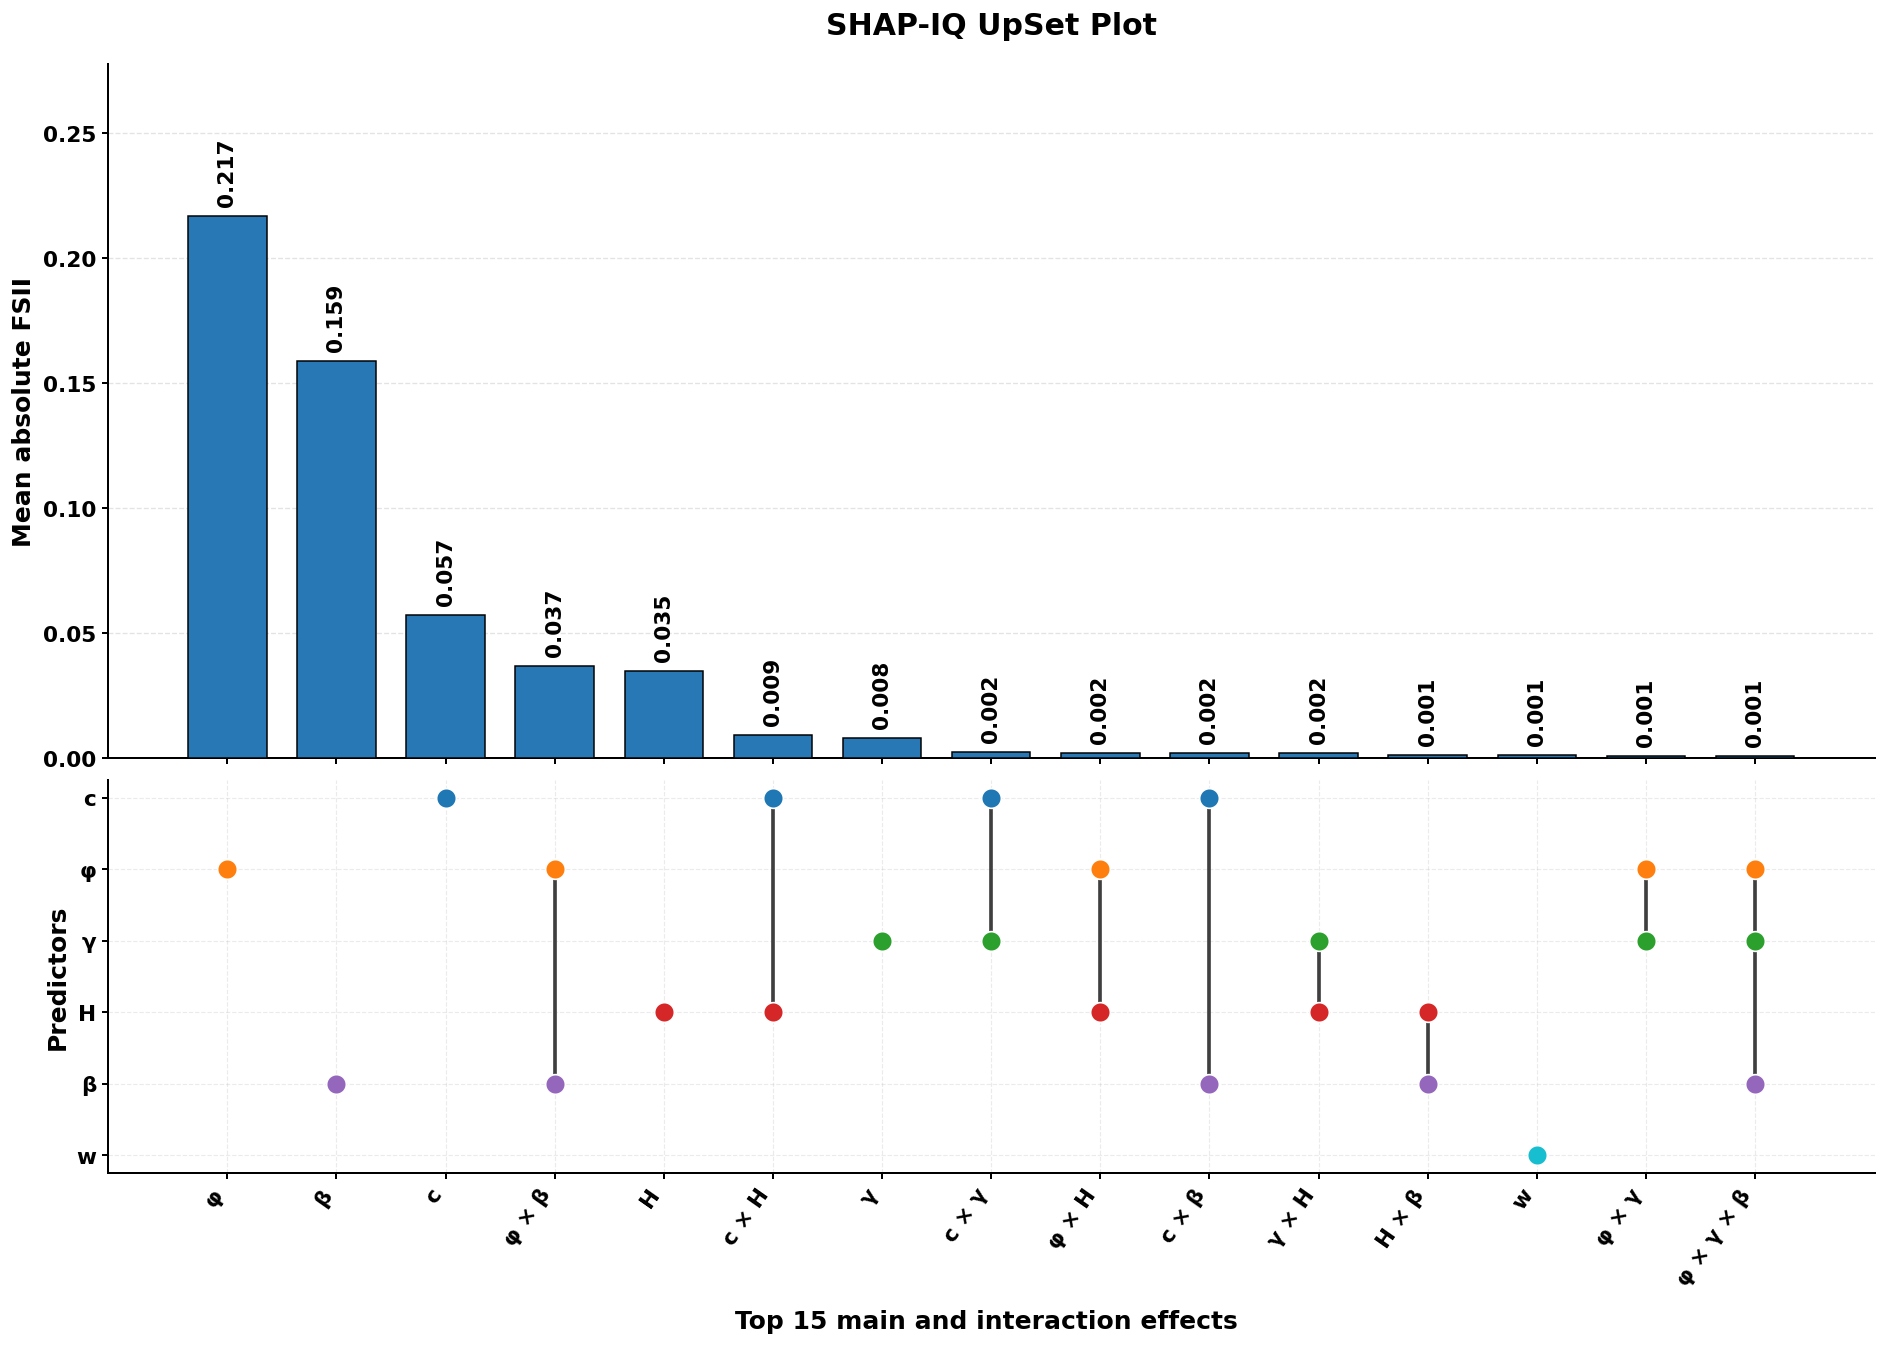

In [47]:
# ================================================================
# FIGURE 16: SHAP-IQ UPSET PLOT
# TOP 15 MAIN AND INTERACTION EFFECTS
# ================================================================

FEATURE_COLOURS = {
    "c": "#1F77B4",
    "φ": "#FF7F0E",
    "γ": "#2CA02C",
    "H": "#D62728",
    "β": "#9467BD",
    "w": "#17BECF",
}


def plot_shapiq_upset(effect_table):

    # ------------------------------------------------------------
    # VALIDATE REQUIRED COLUMNS
    # ------------------------------------------------------------

    required_columns = {
        "Interaction magnitude",
        "Feature set",
        "Feature 1",
        "Feature 2",
        "Feature 3",
    }

    missing_columns = required_columns.difference(
        effect_table.columns
    )

    if missing_columns:
        raise KeyError(
            "The following required columns are missing from "
            f"global_fsii_table: {sorted(missing_columns)}"
        )

    # ------------------------------------------------------------
    # PREPARE TOP 15 EFFECTS
    # ------------------------------------------------------------

    top = (
        effect_table.copy()
        .dropna(subset=["Interaction magnitude"])
        .sort_values(
            "Interaction magnitude",
            ascending=False,
        )
        .head(15)
        .reset_index(drop=True)
    )

    if top.empty:
        raise ValueError(
            "No valid FSII effects were found in global_fsii_table."
        )

    # Use SYMBOLS when already defined by the notebook.
    plot_symbols = (
        list(SYMBOLS)
        if "SYMBOLS" in globals()
        else ["c", "φ", "γ", "H", "β", "w"]
    )

    feature_to_y = {
        feature: index
        for index, feature in enumerate(plot_symbols)
    }

    x_positions = np.arange(len(top))

    bar_values = top[
        "Interaction magnitude"
    ].to_numpy(dtype=float)

    maximum_value = max(
        float(np.max(bar_values)),
        1e-12,
    )

    # ------------------------------------------------------------
    # CREATE FIGURE
    # ------------------------------------------------------------

    fig, (ax_bar, ax_matrix) = plt.subplots(
        2,
        1,
        figsize=(19, 12),
        sharex=True,
        gridspec_kw={
            "height_ratios": [3.0, 1.7],
            "hspace": 0.04,
        },
    )

    # ------------------------------------------------------------
    # UPPER PANEL: FSII MAGNITUDES
    # ------------------------------------------------------------

    bars = ax_bar.bar(
        x_positions,
        bar_values,
        width=0.72,
        color="#2878B5",
        edgecolor="black",
        linewidth=0.9,
        zorder=3,
    )

    ax_bar.set_title(
        "SHAP-IQ UpSet Plot",
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=18,
    )

    ax_bar.set_ylabel(
        "Mean absolute FSII",
        fontsize=FONT_LABEL,
        fontweight="bold",
    )

    ax_bar.set_ylim(
        0,
        maximum_value * 1.28,
    )

    ax_bar.grid(
        axis="y",
        color="#B0B0B0",
        linestyle="--",
        linewidth=0.8,
        alpha=0.35,
        zorder=0,
    )

    ax_bar.tick_params(
        axis="both",
        labelsize=FONT_TICK,
        colors="black",
        width=1.2,
    )

    for tick_label in ax_bar.get_yticklabels():
        tick_label.set_fontweight("bold")

    # Numerical label above each bar
    for bar, value in zip(bars, bar_values):

        ax_bar.text(
            bar.get_x() + bar.get_width() / 2,
            value + maximum_value * 0.018,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=FONT_TICK,
            fontweight="bold",
            color="black",
        )

    # ------------------------------------------------------------
    # LOWER PANEL: INTERACTION MEMBERSHIP MATRIX
    # ------------------------------------------------------------

    for x_position, (_, row) in zip(
        x_positions,
        top.iterrows(),
    ):

        involved = []

        for feature_column in [
            "Feature 1",
            "Feature 2",
            "Feature 3",
        ]:
            feature = row[feature_column]

            if (
                pd.notna(feature)
                and str(feature).strip()
                and str(feature).lower() != "nan"
            ):
                involved.append(str(feature).strip())

        # Remove duplicates without changing their order
        involved = list(dict.fromkeys(involved))

        unknown_features = [
            feature
            for feature in involved
            if feature not in feature_to_y
        ]

        if unknown_features:
            raise KeyError(
                "The following feature symbols are not present in "
                f"SYMBOLS: {unknown_features}"
            )

        y_values = [
            feature_to_y[feature]
            for feature in involved
        ]

        # Connector for pairwise and third-order interactions
        if len(y_values) > 1:
            ax_matrix.plot(
                [x_position, x_position],
                [min(y_values), max(y_values)],
                color="#3F3F3F",
                linewidth=2.2,
                solid_capstyle="round",
                zorder=2,
            )

        # Coloured membership points
        for feature, y_value in zip(
            involved,
            y_values,
        ):
            ax_matrix.scatter(
                x_position,
                y_value,
                s=140,
                color=FEATURE_COLOURS.get(
                    feature,
                    "#666666",
                ),
                edgecolor="white",
                linewidth=1.0,
                zorder=4,
            )

    ax_matrix.set_yticks(
        np.arange(len(plot_symbols))
    )

    ax_matrix.set_yticklabels(
        plot_symbols,
        fontsize=FONT_TICK,
        fontweight="bold",
        color="black",
    )

    ax_matrix.invert_yaxis()

    ax_matrix.set_xticks(x_positions)

    ax_matrix.set_xticklabels(
        top["Feature set"],
        rotation=55,
        ha="right",
        fontsize=FONT_TICK,
        fontweight="bold",
        color="black",
    )

    ax_matrix.set_xlabel(
        "Top 15 main and interaction effects "
        ,
        fontsize=FONT_LABEL,
        fontweight="bold",
        labelpad=12,
    )

    ax_matrix.set_ylabel(
        "Predictors",
        fontsize=FONT_LABEL,
        fontweight="bold",
    )

    ax_matrix.grid(
        color="#B0B0B0",
        linestyle="--",
        linewidth=0.7,
        alpha=0.25,
        zorder=0,
    )

    ax_matrix.tick_params(
        axis="both",
        colors="black",
        width=1.2,
    )

    # ------------------------------------------------------------
    # AXIS FORMATTING
    # ------------------------------------------------------------

    for axis in (ax_bar, ax_matrix):
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)

        axis.spines["left"].set_color("black")
        axis.spines["bottom"].set_color("black")

        axis.spines["left"].set_linewidth(1.2)
        axis.spines["bottom"].set_linewidth(1.2)

    fig.tight_layout()

    # ------------------------------------------------------------
    # FINAL LAYOUT
    # ------------------------------------------------------------

    fig.tight_layout()

    # ------------------------------------------------------------
    # SAVE DIRECTLY WITHOUT save_figure()
    # ------------------------------------------------------------

    import os

    shapiq_directory = str(
        os.fspath(DIRS["shapiq"])
    )

    os.makedirs(
        shapiq_directory,
        exist_ok=True,
    )

    figure_name = (
        "Supplementary_Figure_SHAP_IQ_Order3_Top15_UpSet"
    )

    png_file = os.path.join(
        shapiq_directory,
        f"{figure_name}.png",
    )

    pdf_file = os.path.join(
        shapiq_directory,
        f"{figure_name}.pdf",
    )

    fig.savefig(
        str(png_file),
        dpi=600,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="none",
    )

    fig.savefig(
        str(pdf_file),
        bbox_inches="tight",
        facecolor="white",
        edgecolor="none",
    )

    plt.show()
    plt.close(fig)


# Generate Figure 16
plot_shapiq_upset(global_fsii_table)

## 12. Local FSII Contribution Network

### 12.1 Select a decision-critical held-out case

The representative case is a held-out observation whose 95% profile-wise interval crosses FOS = 1.0. The case closest to the decision threshold is selected transparently. Ordinary SHAP contributions are retained in the numerical export, while the publication network itself uses a single internally consistent FSII decomposition: pure first-order effects and the two strongest pairwise interactions. Third-order effects are reported numerically but omitted from the network for readability.


In [48]:
crossing = np.where((full_result["lower_95"] <= 1.0) & (full_result["upper_95"] >= 1.0))[0]
if len(crossing) == 0:
    raise RuntimeError("No held-out profile 95% interval crosses FOS = 1.0; report this result instead of selecting an unrelated case.")
representative_position = int(crossing[np.argmin(np.abs(full_result["mean"][crossing] - 1.0))])
representative_row = test_df.iloc[representative_position]
representative_shap = mean_shap.values[representative_position]
representative_fsii = LOCAL_FSII[representative_position]
representative_base = float(mean_base[representative_position])

local_interactions = pd.DataFrame({
    "Interaction": INTERACTION_LABELS,
    "Key": INTERACTION_KEYS,
    "Order": [len(key) for key in INTERACTION_KEYS],
    "Local FSII": representative_fsii,
})
local_interactions["Magnitude"] = local_interactions["Local FSII"].abs()

selected_pairwise = local_interactions[local_interactions["Order"] == 2].nlargest(2, "Magnitude")
selected_inflow_interactions = selected_pairwise.copy().reset_index(drop=True)

representative_table = pd.DataFrame({
    "Item": [
        "Test row ID", *SYMBOLS, "SHAP baseline FOS", "Predicted FOS", "Actual FOS",
        "Lower 95% PI", "Upper 95% PI", "SHAP reconstruction error",
    ],
    "Value": [
        int(representative_row["row_id"]),
        *[representative_row[feature] for feature in FEATURES],
        representative_base,
        full_result["mean"][representative_position],
        Y_TEST[representative_position],
        full_result["lower_95"][representative_position],
        full_result["upper_95"][representative_position],
        representative_base + representative_shap.sum() - full_result["mean"][representative_position],
    ],
})

local_shap_table = pd.DataFrame({
    "Predictor": SYMBOLS,
    "Observed value": [representative_row[feature] for feature in FEATURES],
    "Local SHAP contribution": representative_shap,
}).sort_values("Local SHAP contribution", key=np.abs, ascending=False)

show_table(representative_table, caption="Representative InFlow test case")
show_table(local_shap_table, caption="Local SHAP contributions")
show_table(selected_inflow_interactions[["Interaction", "Order", "Local FSII", "Magnitude"]], caption="Displayed local FSII interaction overlays")

with pd.ExcelWriter(DIRS["tables"] / "Table_Shapley_InFlow_Representative_Case.xlsx") as writer:
    representative_table.to_excel(writer, sheet_name="Case", index=False)
    local_shap_table.to_excel(writer, sheet_name="Local SHAP", index=False)
    selected_inflow_interactions.drop(columns="Key").to_excel(writer, sheet_name="Interaction overlays", index=False)

,Item,Value
0,Test row ID,1828.0000
1,c,8.7345
2,φ,34.3611
3,γ,17.2250
4,H,60.0000
5,β,40.0000
6,w,10.0000
7,SHAP baseline FOS,1.1090
8,Predicted FOS,1.0009
9,Actual FOS,0.9996


,Predictor,Observed value,Local SHAP contribution
4,β,40.0000,-0.3143
1,φ,34.3611,0.2626
0,c,8.7345,-0.1071
3,H,60.0000,0.0488
2,γ,17.2250,0.0043
5,w,10.0000,-0.0022


,Interaction,Order,Local FSII,Magnitude
0,φ × β,2,-0.0865,0.0865
1,c × H,2,-0.0274,0.0274


### 12.2 Draw the local first- and second-order FSII network

All coloured arrows use values from the same local FSII decomposition. Dashed grey arrows indicate interaction membership only and are not additional predictive contributions.


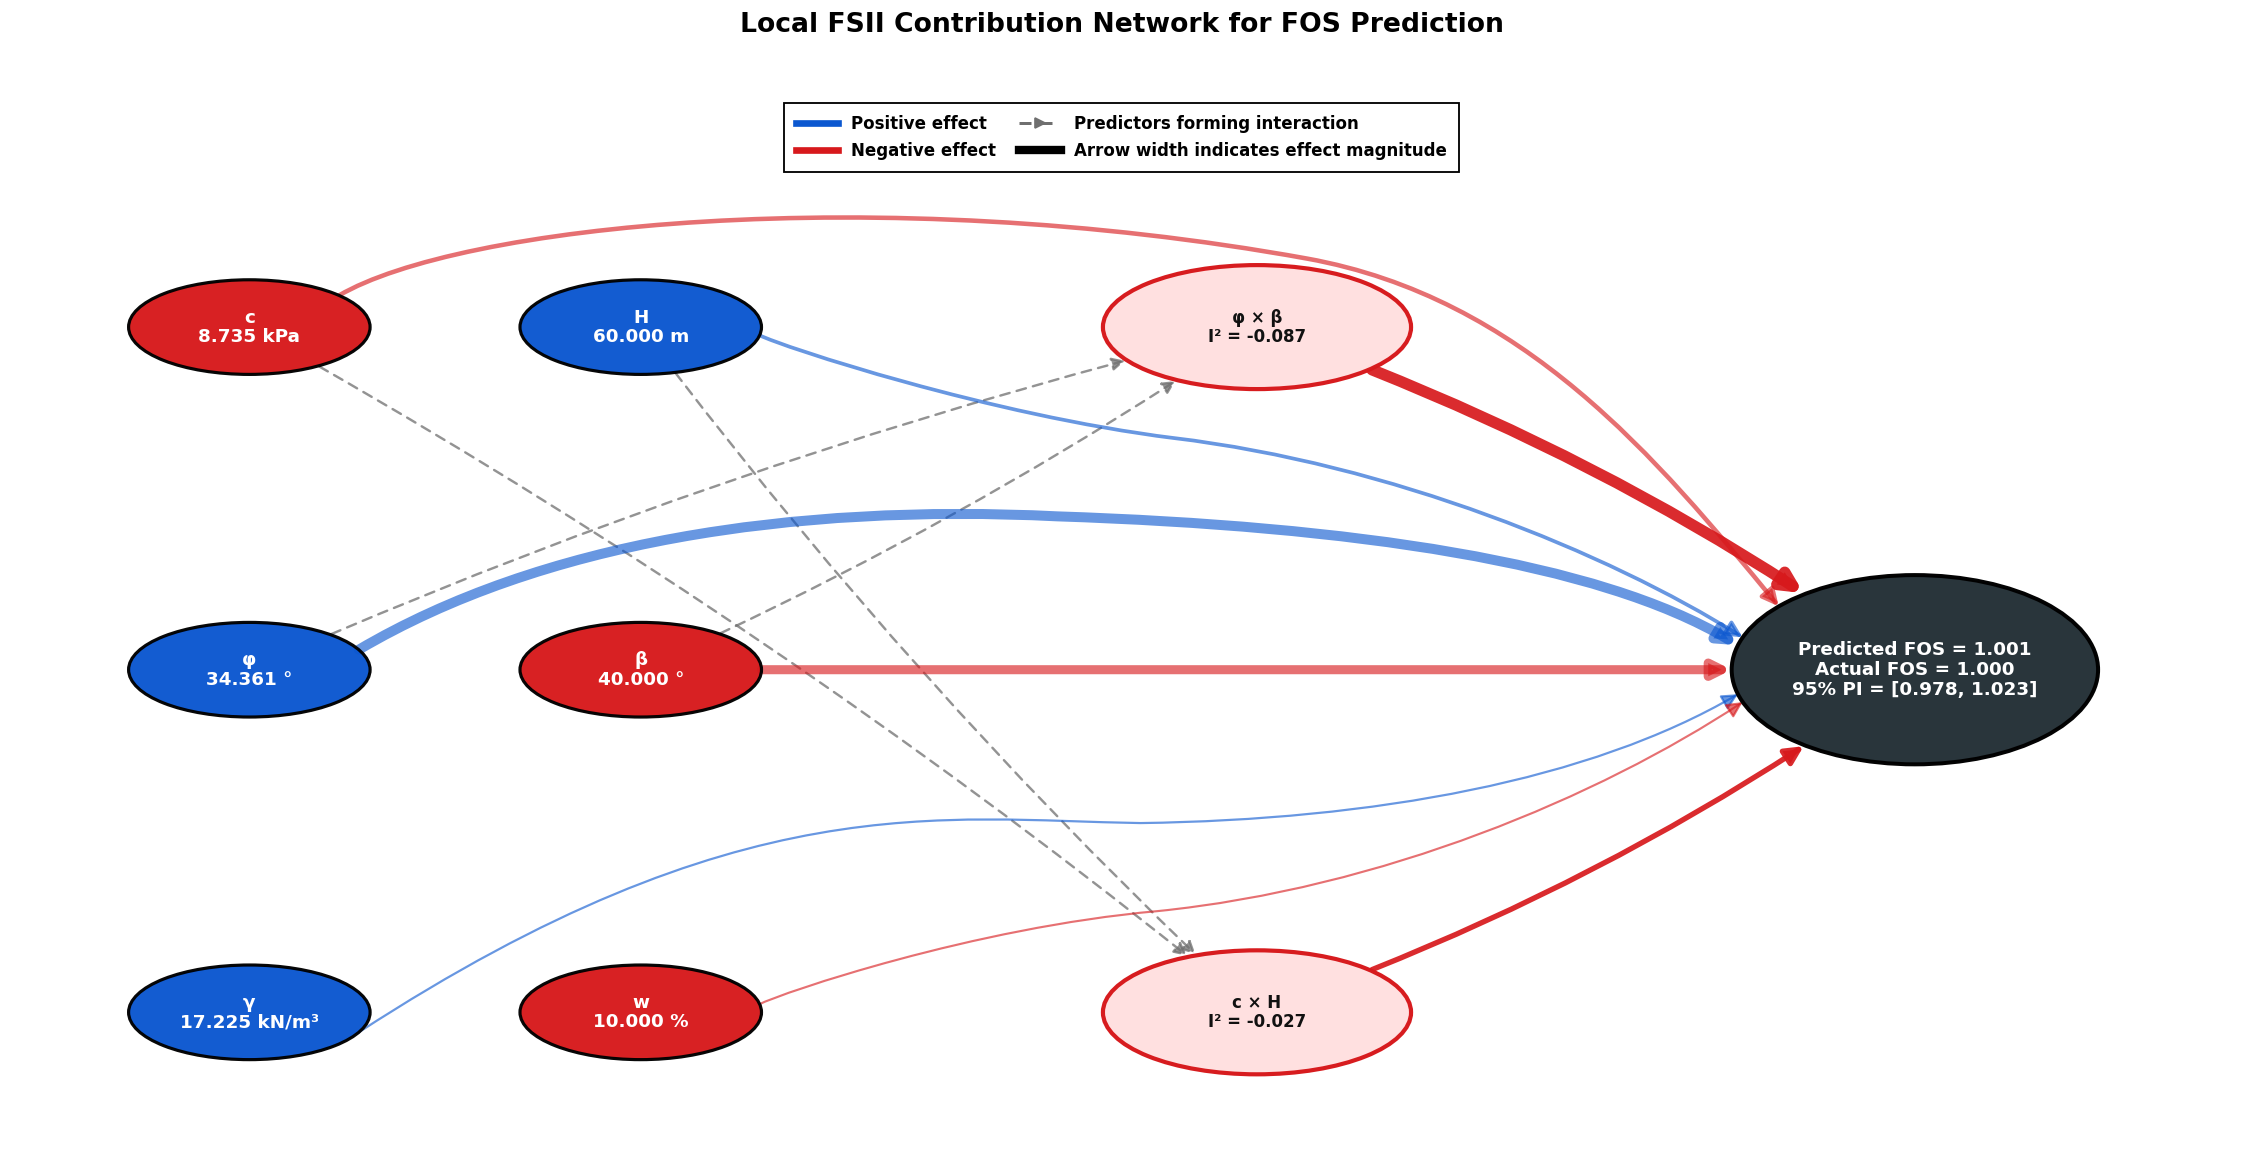

,Representative position,Order,Key,Predictor index,Feature,Predictor,Observed value,Unit,Pure local first-order FSII,Absolute local first-order FSII,Influence sign,First-order rank
0,283,1,"(0,)",0,c,c,8.7345,kPa,-0.0941,0.0941,Negative,3
1,283,1,"(1,)",1,phi,φ,34.3611,°,0.3047,0.3047,Positive,1
2,283,1,"(2,)",2,gamma,γ,17.2250,kN/m³,0.0047,0.0047,Positive,5
3,283,1,"(3,)",3,H,H,60.0000,m,0.0621,0.0621,Positive,4
4,283,1,"(4,)",4,beta,β,40.0000,°,-0.2688,0.2688,Negative,2
5,283,1,"(5,)",5,w,w,10.0000,%,-0.0019,0.0019,Negative,6


,Representative position,Order,Second-order rank,Key,Predictor 1 index,Predictor 2 index,Predictor 1,Predictor 2,Predictor 1 feature,Predictor 2 feature,Interaction,Pure local second-order FSII,Absolute local second-order FSII,Influence sign
0,283,2,1,"(1, 4)",1,4,φ,β,phi,beta,φ × β,-0.0865,0.0865,Negative
1,283,2,2,"(0, 3)",0,3,c,H,c,H,c × H,-0.0274,0.0274,Negative


,Component,Value
0,Sum of pure first-order FSII,0.0067
1,Sum of displayed pure second-order FSII,-0.1139
2,Sum of all pure second-order FSII,-0.1090
3,Sum of pure third-order FSII (not displayed),-0.0058
4,Original predicted FOS,1.0009
5,Actual FOS,0.9996
6,Lower 95% prediction limit,0.9784
7,Upper 95% prediction limit,1.0235



Joint first- and second-order FSII network completed successfully.
First-order effects displayed: 6
Second-order effects displayed: 2
All second-order effects exported: 15
Predicted FOS: 1.001
Actual FOS: 1.000
95% PI: [0.978, 1.023]
Both pure first- and pure second-order FSII effects point towards the prediction.
All arrows terminate at the oval boundaries.
No ordinary SHAP values were mixed with FSII values.
All 15 second-order FSII effects remain in the exported CSV and Excel tables.


In [49]:
# ================================================================
# NEW CELL — JOINT FIRST- AND SECOND-ORDER FSII PREDICTION NETWORK
#
# Uses the notebook's actual objects created in the representative-case cell:
#   local_interactions          -> all 41 local FSII effects
#   selected_inflow_interactions -> two displayed order-2 effects
#   representative_row          -> displayed predictor values
#   full_result                 -> prediction and 95% PI
#
# Pure order-1 and order-2 FSII values are obtained from the SAME
# SHAP-IQ decomposition. Ordinary SHAP values are not mixed into it.
# ================================================================

import ast
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.path import Path as BezierPath


# ================================================================
# DISPLAY CONTROLS
# ================================================================

# The current notebook selected the two strongest local pairwise
# interactions in the representative-case cell. Change to None to display all 15 pairs.
MAX_DISPLAYED_SECOND_ORDER = 2

POSITIVE_COLOUR = "#0B57D0"
NEGATIVE_COLOUR = "#D7191C"
OUTPUT_COLOUR = "#263238"
MEMBERSHIP_COLOUR = "#6F6F6F"
POSITIVE_FILL = "#DCE9FF"
NEGATIVE_FILL = "#FFE0E0"

NODE_FONT = 11
INTERACTION_FONT = 10
OUTPUT_FONT = 11
TITLE_FONT = 16

PREDICTOR_WIDTH = 1.45
PREDICTOR_HEIGHT = 0.58
INTERACTION_WIDTH = 1.85
INTERACTION_HEIGHT = 0.76
OUTPUT_WIDTH = 2.20
OUTPUT_HEIGHT = 1.16


# ================================================================
# VALIDATE THE EXACT NOTEBOOK OBJECTS
# ================================================================

required_objects = [
    "local_interactions",
    "selected_inflow_interactions",
    "representative_position",
    "representative_row",
    "full_result",
    "Y_TEST",
    "FEATURES",
    "SYMBOLS",
    "UNITS",
    "DIRS",
]

missing_objects = [name for name in required_objects if name not in globals()]

if missing_objects:
    raise NameError(
        "Missing required notebook objects: "
        f"{missing_objects}. Run the preceding SHAP, FSII and representative-case cells first."
    )

if not isinstance(local_interactions, pd.DataFrame):
    raise TypeError("local_interactions must be a pandas DataFrame.")

required_interaction_columns = {
    "Interaction", "Key", "Order", "Local FSII", "Magnitude"
}

missing_columns = required_interaction_columns - set(local_interactions.columns)

if missing_columns:
    raise KeyError(
        "local_interactions is missing columns: "
        f"{sorted(missing_columns)}"
    )

required_result_keys = {"mean", "lower_95", "upper_95"}
missing_result_keys = required_result_keys - set(full_result.keys())

if missing_result_keys:
    raise KeyError(
        "full_result is missing keys: "
        f"{sorted(missing_result_keys)}"
    )

FEATURES = list(FEATURES)
SYMBOLS = list(SYMBOLS)

if len(FEATURES) != len(SYMBOLS):
    raise ValueError("FEATURES and SYMBOLS must have equal lengths.")


# ================================================================
# HELPERS
# ================================================================

def effect_colour(value):
    return POSITIVE_COLOUR if float(value) >= 0 else NEGATIVE_COLOUR


def effect_fill(value):
    return POSITIVE_FILL if float(value) >= 0 else NEGATIVE_FILL


def normalise_key(value):
    """Return an interaction key as a tuple of integer indices."""
    if isinstance(value, np.ndarray):
        value = value.tolist()

    if isinstance(value, (tuple, list, set)):
        return tuple(int(item) for item in value)

    if isinstance(value, (int, np.integer)):
        return (int(value),)

    if isinstance(value, str):
        parsed = ast.literal_eval(value)
        if isinstance(parsed, (tuple, list, set)):
            return tuple(int(item) for item in parsed)
        if isinstance(parsed, (int, np.integer)):
            return (int(parsed),)

    raise ValueError(f"Cannot interpret FSII key: {value!r}")


def draw_anchored_arrow(
    ax,
    source,
    target,
    source_patch,
    target_patch,
    colour,
    width,
    radius=0.0,
    linestyle="-",
    alpha=0.85,
    mutation_scale=21,
    zorder=4,
):
    """Draw an arrow that touches, but does not enter, both ovals."""
    arrow = FancyArrowPatch(
        posA=source,
        posB=target,
        patchA=source_patch,
        patchB=target_patch,
        connectionstyle=f"arc3,rad={radius}",
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=width,
        linestyle=linestyle,
        color=colour,
        alpha=alpha,
        shrinkA=0,
        shrinkB=0,
        capstyle="round",
        joinstyle="round",
        zorder=zorder,
    )
    ax.add_patch(arrow)
    return arrow


def ellipse_point(centre, width, height, angle_degrees):
    """Return an exact boundary point on an axis-aligned ellipse."""
    angle = np.deg2rad(float(angle_degrees))
    return (
        centre[0] + 0.5 * width * np.cos(angle),
        centre[1] + 0.5 * height * np.sin(angle),
    )


def draw_routed_arrow(
    ax,
    vertices,
    codes,
    colour,
    width,
    linestyle="-",
    alpha=0.62,
    mutation_scale=20,
    zorder=15,
):
    """Draw a stable multi-segment Bezier arrow on a prescribed route."""
    path = BezierPath(vertices, codes)

    arrow = FancyArrowPatch(
        path=path,
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=width,
        linestyle=linestyle,
        color=colour,
        alpha=alpha,
        shrinkA=0,
        shrinkB=0,
        capstyle="round",
        joinstyle="round",
        zorder=zorder,
    )
    ax.add_patch(arrow)
    return arrow


# ================================================================
# READ PURE FIRST- AND SECOND-ORDER FSII FROM local_interactions
# ================================================================

fsii_source = local_interactions.copy()
fsii_source["Key"] = fsii_source["Key"].apply(normalise_key)
fsii_source["Order"] = pd.to_numeric(fsii_source["Order"], errors="raise").astype(int)
fsii_source["Local FSII"] = pd.to_numeric(
    fsii_source["Local FSII"], errors="raise"
).astype(float)
fsii_source["Magnitude"] = fsii_source["Local FSII"].abs()

if not np.isfinite(fsii_source["Local FSII"]).all():
    raise ValueError("local_interactions contains non-finite Local FSII values.")


# Six genuine first-order FSII effects
first_order_source = fsii_source[fsii_source["Order"] == 1].copy()

first_order_lookup = {
    tuple(row["Key"]): float(row["Local FSII"])
    for _, row in first_order_source.iterrows()
}

expected_first_order_keys = {(index,) for index in range(len(FEATURES))}
missing_first_order_keys = expected_first_order_keys - set(first_order_lookup)

if missing_first_order_keys:
    raise ValueError(
        "The complete local FSII table is missing first-order keys: "
        f"{sorted(missing_first_order_keys)}"
    )

first_order_records = []

for index, (feature, symbol) in enumerate(zip(FEATURES, SYMBOLS)):
    value = first_order_lookup[(index,)]
    first_order_records.append({
        "Representative position": int(representative_position),
        "Order": 1,
        "Key": str((index,)),
        "Predictor index": index,
        "Feature": feature,
        "Predictor": symbol,
        "Observed value": float(representative_row[feature]),
        "Unit": UNITS.get(feature, ""),
        "Pure local first-order FSII": value,
        "Absolute local first-order FSII": abs(value),
        "Influence sign": "Positive" if value >= 0 else "Negative",
    })

first_order_table = pd.DataFrame(first_order_records)
first_order_table["First-order rank"] = (
    first_order_table["Absolute local first-order FSII"]
    .rank(method="first", ascending=False)
    .astype(int)
)


# All fifteen genuine second-order FSII effects
second_order_source = fsii_source[fsii_source["Order"] == 2].copy()

if second_order_source.empty:
    raise ValueError("No second-order effects were found in local_interactions.")

second_order_records = []

for _, row in second_order_source.iterrows():
    key = tuple(sorted(normalise_key(row["Key"])))
    if len(key) != 2 or key[0] == key[1]:
        raise ValueError(f"Invalid second-order key: {key}")

    first_index, second_index = key
    value = float(row["Local FSII"])

    second_order_records.append({
        "Representative position": int(representative_position),
        "Order": 2,
        "Key tuple": key,
        "Key": str(key),
        "Predictor 1 index": first_index,
        "Predictor 2 index": second_index,
        "Predictor 1": SYMBOLS[first_index],
        "Predictor 2": SYMBOLS[second_index],
        "Predictor 1 feature": FEATURES[first_index],
        "Predictor 2 feature": FEATURES[second_index],
        "Interaction": f"{SYMBOLS[first_index]} × {SYMBOLS[second_index]}",
        "Pure local second-order FSII": value,
        "Absolute local second-order FSII": abs(value),
        "Influence sign": "Positive" if value >= 0 else "Negative",
    })

all_second_order_table = (
    pd.DataFrame(second_order_records)
    .sort_values("Absolute local second-order FSII", ascending=False)
    .reset_index(drop=True)
)
all_second_order_table.insert(
    2, "Second-order rank", np.arange(1, len(all_second_order_table) + 1)
)


# Use the already selected two pairs when available. This preserves
# the notebook's original the representative-case cell selection exactly.
selected_keys = {
    tuple(sorted(normalise_key(key)))
    for key in selected_inflow_interactions["Key"]
}

displayed_second_order_table = all_second_order_table[
    all_second_order_table["Key tuple"].isin(selected_keys)
].copy()

if displayed_second_order_table.empty:
    displayed_second_order_table = all_second_order_table.copy()

if MAX_DISPLAYED_SECOND_ORDER is not None:
    displayed_second_order_table = displayed_second_order_table.head(
        int(MAX_DISPLAYED_SECOND_ORDER)
    ).copy()

displayed_second_order_table = displayed_second_order_table.reset_index(drop=True)


# ================================================================
# MODEL OUTPUTS — KEPT EXACTLY AS GENERATED UPSTREAM
# ================================================================

predicted_fos = float(full_result["mean"][representative_position])
actual_fos = float(np.asarray(Y_TEST).reshape(-1)[representative_position])
lower_95_fos = float(full_result["lower_95"][representative_position])
upper_95_fos = float(full_result["upper_95"][representative_position])

sum_first_order = float(first_order_table["Pure local first-order FSII"].sum())
sum_all_second_order = float(
    all_second_order_table["Pure local second-order FSII"].sum()
)
sum_displayed_second_order = float(
    displayed_second_order_table["Pure local second-order FSII"].sum()
)

# The notebook calculated FSII through order three. This new figure
# deliberately visualises orders one and two only; therefore it does
# not falsely claim that these two orders alone reconstruct the model.
third_order_source = fsii_source[fsii_source["Order"] == 3].copy()
sum_third_order = float(third_order_source["Local FSII"].sum())

prediction_summary_table = pd.DataFrame({
    "Component": [
        "Sum of pure first-order FSII",
        "Sum of displayed pure second-order FSII",
        "Sum of all pure second-order FSII",
        "Sum of pure third-order FSII (not displayed)",
        "Original predicted FOS",
        "Actual FOS",
        "Lower 95% prediction limit",
        "Upper 95% prediction limit",
    ],
    "Value": [
        sum_first_order,
        sum_displayed_second_order,
        sum_all_second_order,
        sum_third_order,
        predicted_fos,
        actual_fos,
        lower_95_fos,
        upper_95_fos,
    ],
})


# ================================================================
# EXPORT COMPLETE NUMERICAL TABLES
# ================================================================

tables_directory = os.fspath(DIRS["tables"])
os.makedirs(tables_directory, exist_ok=True)

first_order_table.to_csv(
    os.path.join(tables_directory, "Table_Joint_FSII_Pure_First_Order.csv"), index=False
)
first_order_table.to_excel(
    os.path.join(tables_directory, "Table_Joint_FSII_Pure_First_Order.xlsx"), index=False
)
displayed_second_order_table.drop(columns="Key tuple").to_csv(
    os.path.join(tables_directory, "Table_Joint_FSII_Displayed_Second_Order.csv"), index=False
)
displayed_second_order_table.drop(columns="Key tuple").to_excel(
    os.path.join(tables_directory, "Table_Joint_FSII_Displayed_Second_Order.xlsx"), index=False
)
all_second_order_table.drop(columns="Key tuple").to_csv(
    os.path.join(tables_directory, "Table_Joint_FSII_All_Second_Order.csv"), index=False
)
all_second_order_table.drop(columns="Key tuple").to_excel(
    os.path.join(tables_directory, "Table_Joint_FSII_All_Second_Order.xlsx"), index=False
)
prediction_summary_table.to_csv(
    os.path.join(tables_directory, "Table_Joint_FSII_Prediction_Summary.csv"), index=False
)
prediction_summary_table.to_excel(
    os.path.join(tables_directory, "Table_Joint_FSII_Prediction_Summary.xlsx"), index=False
)


# ================================================================
# LAYOUT
# ================================================================

number_of_predictors = len(SYMBOLS)
left_count = int(np.ceil(number_of_predictors / 2))
right_count = number_of_predictors - left_count
number_of_interactions = len(displayed_second_order_table)

vertical_extent = max(4.2, 1.20 * (max(left_count, right_count, number_of_interactions) - 1))

left_y = np.linspace(vertical_extent / 2, -vertical_extent / 2, left_count)
right_y = (
    np.linspace(vertical_extent / 2, -vertical_extent / 2, right_count)
    if right_count else np.array([])
)
interaction_y = np.linspace(
    vertical_extent / 2, -vertical_extent / 2, number_of_interactions
)

LEFT_X = -5.90
RIGHT_X = -3.55
INTERACTION_X = 0.15
OUTPUT_X = 4.10

feature_positions = {}

for index, symbol in enumerate(SYMBOLS[:left_count]):
    feature_positions[symbol] = (LEFT_X, float(left_y[index]))

for index, symbol in enumerate(SYMBOLS[left_count:]):
    feature_positions[symbol] = (RIGHT_X, float(right_y[index]))

interaction_positions = {
    index: (INTERACTION_X, float(y_value))
    for index, y_value in enumerate(interaction_y)
}

output_position = (OUTPUT_X, 0.0)


# ================================================================
# DRAW FIGURE
# ================================================================

fig, ax = plt.subplots(
    figsize=(19, max(10, 1.20 * max(left_count, number_of_interactions) + 6)),
    facecolor="white",
)
ax.set_facecolor("white")

predictor_patches = {}
interaction_patches = {}


# First-order nodes
for _, row in first_order_table.iterrows():
    feature = row["Feature"]
    symbol = row["Predictor"]
    value = float(row["Pure local first-order FSII"])
    position = feature_positions[symbol]

    patch = Ellipse(
        position,
        width=PREDICTOR_WIDTH,
        height=PREDICTOR_HEIGHT,
        facecolor=effect_colour(value),
        edgecolor="black",
        linewidth=1.9,
        alpha=0.97,
        zorder=20,
    )
    ax.add_patch(patch)
    predictor_patches[symbol] = patch

    observed = float(row["Observed value"])
    unit = str(row["Unit"]).strip()
    observed_text = f"{observed:.3f}" + (f" {unit}" if unit else "")

    ax.text(
        position[0],
        position[1],
        f"{symbol}\n{observed_text}",
        ha="center",
        va="center",
        color="white",
        fontsize=NODE_FONT,
        fontweight="bold",
        linespacing=1.10,
        zorder=21,
    )


# Second-order nodes
for row_index, row in displayed_second_order_table.iterrows():
    value = float(row["Pure local second-order FSII"])
    position = interaction_positions[row_index]

    patch = Ellipse(
        position,
        width=INTERACTION_WIDTH,
        height=INTERACTION_HEIGHT,
        facecolor=effect_fill(value),
        edgecolor=effect_colour(value),
        linewidth=2.5,
        alpha=0.99,
        zorder=18,
    )
    ax.add_patch(patch)
    interaction_patches[row_index] = patch

    pair = f'{row["Predictor 1"]} × {row["Predictor 2"]}'
    ax.text(
        position[0],
        position[1],
        f"{pair}\nI² = {value:+.3f}",
        ha="center",
        va="center",
        color="#111111",
        fontsize=INTERACTION_FONT,
        fontweight="bold",
        linespacing=1.12,
        zorder=19,
    )


# Prediction node
output_patch = Ellipse(
    output_position,
    width=OUTPUT_WIDTH,
    height=OUTPUT_HEIGHT,
    facecolor=OUTPUT_COLOUR,
    edgecolor="black",
    linewidth=2.4,
    alpha=0.99,
    zorder=22,
)
ax.add_patch(output_patch)

ax.text(
    output_position[0],
    output_position[1],
    (
        f"Predicted FOS = {predicted_fos:.3f}\n"
        f"Actual FOS = {actual_fos:.3f}\n"
        f"95% PI = [{lower_95_fos:.3f}, {upper_95_fos:.3f}]"
    ),
    ha="center",
    va="center",
    color="white",
    fontsize=OUTPUT_FONT,
    fontweight="bold",
    linespacing=1.17,
    zorder=23,
)


# ================================================================
# FIRST-ORDER → PREDICTION ARROWS
# ================================================================

first_values = first_order_table["Pure local first-order FSII"].to_numpy(float)
first_scale = max(float(np.max(np.abs(first_values))), 1e-12)

# Fixed publication routes. These affect geometry only; every arrow keeps
# its original FSII sign colour, magnitude-scaled width and opacity.
def route_name(symbol):
    """Map Unicode/MathText symbol variants to stable route names."""
    cleaned = str(symbol).strip().replace("$", "").replace("{", "").replace("}", "")
    aliases = {
        "c": "c", "H": "H", "w": "w",
        "φ": "phi", "phi": "phi", "\\phi": "phi",
        "β": "beta", "beta": "beta", "\\beta": "beta",
        "γ": "gamma", "gamma": "gamma", "\\gamma": "gamma",
    }
    return aliases.get(cleaned)


route_angles = {
    "c": (42, 138),
    "H": (-10, 160),
    "phi": (25, 165),
    "beta": (0, 180),
    "gamma": (-25, 195),
    "w": (10, 200),
}

for row_index, row in first_order_table.iterrows():
    symbol = row["Predictor"]
    route = route_name(symbol)
    value = float(row["Pure local first-order FSII"])
    width = 1.25 + 4.75 * abs(value) / first_scale

    if route in route_angles:
        source_angle, target_angle = route_angles[route]
        start = ellipse_point(
            feature_positions[symbol],
            PREDICTOR_WIDTH,
            PREDICTOR_HEIGHT,
            source_angle,
        )
        end = ellipse_point(
            output_position,
            OUTPUT_WIDTH,
            OUTPUT_HEIGHT,
            target_angle,
        )

        # Independent multi-segment lanes reproduce the supplied routing.
        if route == "c":
            vertices = [
                start,
                (-4.65, 2.72), (-2.15, 3.00), (0.45, 2.52),
                (1.75, 2.28), (2.55, 1.30), end,
            ]

        elif route == "H":
            vertices = [
                start,
                (-2.70, 1.98), (-1.45, 1.56), (-0.35, 1.42),
                (0.95, 1.26), (2.25, 0.72), end,
            ]

        elif route == "phi":
            vertices = [
                start,
                (-4.15, 0.78), (-2.65, 1.02), (-1.05, 0.94),
                (0.72, 0.88), (2.20, 0.66), end,
            ]

        elif route == "beta":
            vertices = [
                start,
                (-1.70, 0.0), (1.55, 0.0), end,
            ]

        elif route == "gamma":
            vertices = [
                start,
                (-2.95, -0.70), (-1.75, -0.92), (-0.55, -0.94),
                (0.85, -0.92), (2.15, -0.68), end,
            ]

        else:  # w
            vertices = [
                start,
                (-2.70, -1.98), (-1.55, -1.58), (-0.45, -1.48),
                (0.90, -1.34), (2.20, -0.78), end,
            ]

        if len(vertices) == 4:
            codes = [
                BezierPath.MOVETO,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
            ]
        else:
            codes = [
                BezierPath.MOVETO,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
            ]

        draw_routed_arrow(
            ax=ax,
            vertices=vertices,
            codes=codes,
            colour=effect_colour(value),
            width=width,
            alpha=0.62,
            mutation_scale=20,
            zorder=15,
        )

    else:
        # Safe fallback if a future notebook uses different predictor symbols.
        draw_anchored_arrow(
            ax,
            feature_positions[symbol],
            output_position,
            predictor_patches[symbol],
            output_patch,
            effect_colour(value),
            width,
            radius=0.0,
            alpha=0.62,
            mutation_scale=20,
            zorder=15,
        )


# ================================================================
# PREDICTOR → INTERACTION MEMBERSHIP ARROWS
# ================================================================

for row_index, row in displayed_second_order_table.iterrows():
    target = interaction_positions[row_index]
    members = [row["Predictor 1"], row["Predictor 2"]]

    for member, radius in zip(members, (-0.045, 0.045)):
        member_route = route_name(member)
        target_y = target[1]

        # The two long left-column membership arrows follow the marked
        # open corridors: c arches over H into c × H, while gamma arches
        # over w into gamma × H. Their dashed-grey encoding is unchanged.
        if member_route == "c" and target_y > 0.10:
            membership_start = ellipse_point(
                feature_positions[member],
                PREDICTOR_WIDTH,
                PREDICTOR_HEIGHT,
                5,
            )
            membership_end = ellipse_point(
                target,
                INTERACTION_WIDTH,
                INTERACTION_HEIGHT,
                170,
            )
            membership_vertices = [
                membership_start,
                (-4.60, 2.52), (-3.45, 2.56), (-2.35, 2.35),
                (-1.45, 2.20), (-0.75, 2.14), membership_end,
            ]
            membership_codes = [
                BezierPath.MOVETO,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
            ]
            draw_routed_arrow(
                ax=ax,
                vertices=membership_vertices,
                codes=membership_codes,
                colour=MEMBERSHIP_COLOUR,
                width=1.45,
                alpha=0.75,
                mutation_scale=16,
                zorder=9,
                linestyle=(0, (4, 3)),
            )

        elif member_route == "gamma" and target_y < -0.10:
            membership_start = ellipse_point(
                feature_positions[member],
                PREDICTOR_WIDTH,
                PREDICTOR_HEIGHT,
                -5,
            )
            membership_end = ellipse_point(
                target,
                INTERACTION_WIDTH,
                INTERACTION_HEIGHT,
                190,
            )
            membership_vertices = [
                membership_start,
                (-4.60, -2.48), (-3.45, -2.52), (-2.35, -2.34),
                (-1.45, -2.20), (-0.75, -2.14), membership_end,
            ]
            membership_codes = [
                BezierPath.MOVETO,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
                BezierPath.CURVE4, BezierPath.CURVE4, BezierPath.CURVE4,
            ]
            draw_routed_arrow(
                ax=ax,
                vertices=membership_vertices,
                codes=membership_codes,
                colour=MEMBERSHIP_COLOUR,
                width=1.45,
                alpha=0.75,
                mutation_scale=16,
                zorder=9,
                linestyle=(0, (4, 3)),
            )

        else:
            draw_anchored_arrow(
                ax,
                feature_positions[member],
                target,
                predictor_patches[member],
                interaction_patches[row_index],
                MEMBERSHIP_COLOUR,
                1.45,
                radius=radius,
                linestyle=(0, (4, 3)),
                alpha=0.75,
                mutation_scale=16,
                zorder=9,
            )


# ================================================================
# SECOND-ORDER → PREDICTION ARROWS
# ================================================================

second_values = displayed_second_order_table[
    "Pure local second-order FSII"
].to_numpy(float)
second_scale = max(float(np.max(np.abs(second_values))), 1e-12)

for row_index, row in displayed_second_order_table.iterrows():
    value = float(row["Pure local second-order FSII"])
    position = interaction_positions[row_index]
    width = 1.55 + 5.25 * abs(value) / second_scale

    if position[1] > 0.10:
        radius = -0.075
    elif position[1] < -0.10:
        radius = 0.075
    else:
        radius = 0.0

    draw_anchored_arrow(
        ax,
        position,
        output_position,
        interaction_patches[row_index],
        output_patch,
        effect_colour(value),
        width,
        radius=radius,
        alpha=0.92,
        mutation_scale=22,
        zorder=12,
    )


# ================================================================
# LEGEND
# ================================================================

legend_items = [
    Line2D([0], [0], color=POSITIVE_COLOUR, linewidth=4,
           label="Positive effect"),
    Line2D([0], [0], color=NEGATIVE_COLOUR, linewidth=4,
           label="Negative effect"),
    Line2D([0], [0], color=MEMBERSHIP_COLOUR, linewidth=1.8,
           linestyle=(0, (4, 3)), marker=">", markersize=6,
           markevery=[1], label="Predictors forming interaction"),
    Line2D([0], [0], color="black", linewidth=5,
           label="Arrow width indicates effect magnitude"),
]

legend = ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=True,
    fancybox=False,
    framealpha=1.0,
    fontsize=10,
    borderpad=0.75,
    columnspacing=1.35,
    handlelength=2.5,
)
legend.get_frame().set_facecolor("white")
legend.get_frame().set_edgecolor("black")
legend.get_frame().set_linewidth(1.1)

for legend_text in legend.get_texts():
    legend_text.set_color("black")
    legend_text.set_fontweight("bold")


# ================================================================
# FINAL FORMAT AND SAVE
# ================================================================

ax.set_title(
    "Local FSII Contribution Network for FOS Prediction",
    fontsize=TITLE_FONT,
    fontweight="bold",
    color="black",
    pad=50,
)

ax.set_xlim(
    LEFT_X - PREDICTOR_WIDTH / 2 - 0.70,
    OUTPUT_X + OUTPUT_WIDTH / 2 + 0.80,
)
ax.set_ylim(
    -vertical_extent / 2 - 0.85,
    vertical_extent / 2 + 1.30,
)
ax.axis("off")
fig.tight_layout(pad=1.4)

# Save directly with plain-string paths.  Do not call the notebook-level
# save_figure() helper: that helper may contain a stale pathlib/Matplotlib
# Path name collision from an earlier cell.
inflow_directory = os.fspath(DIRS["inflow"])
os.makedirs(inflow_directory, exist_ok=True)

figure_stem = "Figure_08_Local_FSII_Contribution_Network"
png_file = os.path.join(inflow_directory, figure_stem + ".png")
pdf_file = os.path.join(inflow_directory, figure_stem + ".pdf")

fig.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight",
    facecolor="white",
)
fig.savefig(
    pdf_file,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(fig)


# ================================================================
# DISPLAY TABLES AND CONFIRMATION
# ================================================================

show_table(
    first_order_table,
    caption="Pure first-order local FSII effects for the representative case",
)
show_table(
    displayed_second_order_table.drop(columns="Key tuple"),
    caption="Pure second-order local FSII effects displayed in the network",
)
show_table(
    prediction_summary_table,
    caption="FSII orders and original FOS prediction summary",
)

print("\nJoint first- and second-order FSII network completed successfully.")
print(f"First-order effects displayed: {len(first_order_table)}")
print(f"Second-order effects displayed: {len(displayed_second_order_table)}")
print(f"All second-order effects exported: {len(all_second_order_table)}")
print(f"Predicted FOS: {predicted_fos:.3f}")
print(f"Actual FOS: {actual_fos:.3f}")
print(f"95% PI: [{lower_95_fos:.3f}, {upper_95_fos:.3f}]")
print("Both pure first- and pure second-order FSII effects point towards the prediction.")
print("All arrows terminate at the oval boundaries.")
print("No ordinary SHAP values were mixed with FSII values.")
print("All 15 second-order FSII effects remain in the exported CSV and Excel tables.")

## 13. Reproducibility Record and Output Index

### 13.1 Save the final run metadata and display key outputs

In [50]:
package_names = [
    "numpy", "pandas", "scipy", "scikit-learn", "torch", "optuna",
    "shap", "shapiq", "matplotlib", "seaborn", "joblib", "openpyxl",
]
package_versions = {}
for package in package_names:
    try:
        package_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        package_versions[package] = "not available"

def make_json_safe(value):
    if isinstance(value, dict):
        return {str(key): make_json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [make_json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if hasattr(value, "detach") and hasattr(value, "cpu"):
        tensor_value = value.detach().cpu()
        return tensor_value.item() if tensor_value.numel() == 1 else tensor_value.numpy().tolist()
    if isinstance(value, os.PathLike):
        return os.fspath(value)
    return value

metadata_record = {
    "title": "PGUC-MLP: physics-guided ensemble, profile-wise conformal calibration and interaction explanation",
    "workflow_version": WORKFLOW_VERSION,
    "evaluation_status": EVALUATION_STATUS,
    "dataset": os.fspath(DATA_PATH),
    "data_fingerprint": DATA_FINGERPRINT,
    "sheet": SHEET_NAME,
    "predictors": dict(zip(SYMBOLS, FEATURES)),
    "target": TARGET,
    "split": {name: len(frame) for name, frame in subset_frames.items()},
    "independent_group_definition": ["c", "phi"],
    "repeated_scenario_variables": ["gamma", "H", "beta", "w"],
    "headline_model_key": HEADLINE_MODEL_KEY,
    "headline_model_label": HEADLINE_MODEL_LABEL,
    "uncertainty_method": "between-member scale plus maximum-within-profile split conformal calibration",
    "conformal_target": "simultaneous coverage of all scenarios in a new exchangeable c-phi profile",
    "seed": SEED,
    "ensemble_seeds": ENSEMBLE_SEEDS,
    "best_hyperparameters": BEST_PARAMS,
    "final_epochs": CV_EPOCHS,
    "optuna": study_metadata,
    "conformal_calibration": calibration_objects,
    "SHAP_IQ": {"index": "FSII", "maximum_order": 3, "effects": 41, "coalition_budget": 64},
    "FOS_provenance": FOS_PROVENANCE,
    "unresolved_provenance_items": unresolved_provenance["Required provenance item"].tolist(),
    "device": str(DEVICE),
    "package_versions": package_versions,
}
metadata_record = make_json_safe(metadata_record)

project_directory = os.fspath(PROJECT_DIR)
os.makedirs(project_directory, exist_ok=True)
metadata_path = os.path.join(project_directory, "PGUC_MLP_Q1_Run_Metadata.json")
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata_record, file, indent=2, ensure_ascii=False)

requirements_path = os.path.join(project_directory, "requirements_snapshot.txt")
with open(requirements_path, "w", encoding="utf-8") as file:
    for package, version in sorted(package_versions.items()):
        file.write(f"{package}=={version}\n")

output_files = []
for folder in DIRS.values():
    folder_string = os.fspath(folder)
    if not os.path.isdir(folder_string):
        continue
    for current_directory, _, filenames in os.walk(folder_string):
        for filename in filenames:
            complete_path = os.path.join(current_directory, filename)
            if os.path.isfile(complete_path):
                output_files.append(os.path.normpath(complete_path))
output_files = sorted(set(output_files), key=str)

output_index = pd.DataFrame({
    "File": [os.path.basename(path) for path in output_files],
    "Category": [os.path.basename(os.path.dirname(path)) for path in output_files],
    "Path": output_files,
})
output_index_path = os.path.join(project_directory, "PGUC_MLP_Q1_Output_Index.csv")
output_index.to_csv(output_index_path, index=False)

main_figure_manifest = [
    ("Figure 1", DIRS["performance"] / "Figure_01_PGUC_MLP_Workflow.png"),
    ("Figure 2", DIRS["performance"] / "Figure_02_Profile_Independent_Partition.png"),
    ("Figure 3", DIRS["performance"] / "Figure_03_Model_Comparison.png"),
    ("Figure 4", DIRS["uncertainty"] / "Figure_04_Profile_Wise_Conformal_Intervals.png"),
    ("Figure 5", DIRS["sensitivity"] / "Figure_05_Predictor_Response_Sensitivity.png"),
    ("Figure 6", DIRS["xai"] / "Figure_06_SHAP_Beeswarm_Prediction_and_Interval_Width.png"),
    ("Figure 7", DIRS["shapiq"] / "Figure_07_FSII_Main_and_Pairwise_Effects.png"),
    ("Figure 8", DIRS["inflow"] / "Figure_08_Local_FSII_Contribution_Network.png"),
]

supplementary_manifest = [
    ("S1", DIRS["eda"] / "Figure_01_Distributions.png"),
    ("S2", DIRS["eda"] / "Figure_02_Pearson_Correlation.png"),
    ("S3", DIRS["eda"] / "Figure_03_FOS_Height_Slope_Angle.png"),
    ("S4", DIRS["performance"] / "Figure_04_Optuna_Optimisation_History.png"),
    ("S5", DIRS["performance"] / "Figure_06_Observed_vs_Predicted_Ablation.png"),
    ("S6", DIRS["performance"] / "Supplementary_Figure_PGUC_MLP_Diagnostics.png"),
    ("S7", DIRS["uncertainty"] / "Supplementary_Figure_Ensemble_Spread.png"),
    ("S8", DIRS["sensitivity"] / "Figure_11_Monotonicity_Violation_Rates.png"),
    ("S9", DIRS["sensitivity"] / "Supplementary_Figure_Moisture_Perturbation.png"),
    ("S10", DIRS["xai"] / "Supplementary_Figure_SHAP_Dependence_All_Predictors.png"),
    ("S11", DIRS["shapiq"] / "Supplementary_Figure_SHAP_IQ_Order3_Top15_UpSet.png"),
]

def build_manifest(entries, tier):
    return pd.DataFrame([
        {
            "Tier": tier,
            "Label": label,
            "Path": os.fspath(path),
            "Exists": bool(path.exists()),
        }
        for label, path in entries
    ])

publication_manifest = pd.concat([
    build_manifest(main_figure_manifest, "Main manuscript"),
    build_manifest(supplementary_manifest, "Supplementary material"),
], ignore_index=True)
publication_manifest.to_excel(DIRS["tables"] / "Table_Publication_Output_Manifest.xlsx", index=False)

main_table_manifest = pd.DataFrame({
    "Main table": ["Table 1", "Table 2", "Table 3", "Table 4", "Table 5", "Table 6"],
    "Content": [
        "Variables, units, ranges, provenance and expected physical direction",
        "Scenario design and group-aware profile partition",
        "Model configurations and selected hyperparameters",
        "Grouped-CV and held-out comparison with conventional baselines and bootstrap CIs",
        "Physics consistency, profile coverage and FOS=1.0 safety decisions",
        "Conditional performance by FOS range and stability class",
    ],
    "Primary file": [
        os.fspath(DIRS["tables"] / "Table_Main_Variables_Ranges_and_Provenance.xlsx"),
        os.fspath(DIRS["tables"] / "Table_Main_Scenario_and_Profile_Partition.xlsx"),
        os.fspath(DIRS["tables"] / "Table_Main_Model_Configurations_and_Hyperparameters.xlsx"),
        os.fspath(DIRS["tables"] / "Table_Model_Comparison_with_Conventional_Baselines.xlsx"),
        os.fspath(DIRS["tables"] / "Table_Main_Physics_Uncertainty_Safety_Audit.xlsx"),
        os.fspath(DIRS["tables"] / "Table_Main_Conditional_Performance.xlsx"),
    ],
})

supplementary_table_manifest = pd.DataFrame({
    "Supplementary content": [
        "Dataset audit and full descriptive statistics",
        "Full Pearson correlations and geometry-response matrix",
        "All Optuna attempts and selected parameters",
        "Detailed grouped fivefold CV and training histories",
        "Full ablation predictions and residual diagnostics",
        "Conditional performance including every geometry",
        "Conformal profile scores, coverage curve and bootstrap intervals",
        "Complete monotonicity and response-sensitivity audits",
        "Moisture perturbation audit",
        "Local SHAP values and global SHAP importance",
        "All 41 global FSII effects and all local FSII values",
        "FSII reconstruction and representative-case numerical tables",
    ]
})

with pd.ExcelWriter(DIRS["tables"] / "Table_Main_and_Supplementary_Manuscript_Plan.xlsx") as writer:
    main_table_manifest.to_excel(writer, sheet_name="Main tables", index=False)
    supplementary_table_manifest.to_excel(writer, sheet_name="Supplementary tables", index=False)

show_table(publication_manifest, precision=0, caption="Main and supplementary output manifest")
show_table(main_table_manifest, precision=0, caption="Six main-manuscript tables")
print(f"Indexed {len(output_index):,} generated files.")
print(f"Unresolved FOS-provenance items: {len(unresolved_provenance)}")
print(f"Metadata saved to: {metadata_path}")
print(f"Output index saved to: {output_index_path}")
print("Q1-revised analysis completed successfully.")


,Tier,Label,Path,Exists
0,Main manuscript,Figure 1,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/02_Performance/Figure_01_PGUC_MLP_Workflow.png,True
1,Main manuscript,Figure 2,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/02_Performance/Figure_02_Profile_Independent_Partition.png,True
2,Main manuscript,Figure 3,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/02_Performance/Figure_03_Model_Comparison.png,True
3,Main manuscript,Figure 4,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/03_Uncertainty/Figure_04_Profile_Wise_Conformal_Intervals.png,True
4,Main manuscript,Figure 5,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/04_Sensitivity/Figure_05_Predictor_Response_Sensitivity.png,True
5,Main manuscript,Figure 6,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/05_XAI/Figure_06_SHAP_Beeswarm_Prediction_and_Interval_Width.png,True
6,Main manuscript,Figure 7,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/06_SHAP_IQ/Figure_07_FSII_Main_and_Pairwise_Effects.png,True
7,Main manuscript,Figure 8,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/07_InFlow/Figure_08_Local_FSII_Contribution_Network.png,True
8,Supplementary material,S1,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/01_EDA/Figure_01_Distributions.png,True
9,Supplementary material,S2,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/figures/01_EDA/Figure_02_Pearson_Correlation.png,True


,Main table,Content,Primary file
0,Table 1,"Variables, units, ranges, provenance and expected physical direction",/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_Main_Variables_Ranges_and_Provenance.xlsx
1,Table 2,Scenario design and group-aware profile partition,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_Main_Scenario_and_Profile_Partition.xlsx
2,Table 3,Model configurations and selected hyperparameters,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_Main_Model_Configurations_and_Hyperparameters.xlsx
3,Table 4,Grouped-CV and held-out comparison with conventional baselines and bootstrap CIs,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_Model_Comparison_with_Conventional_Baselines.xlsx
4,Table 5,"Physics consistency, profile coverage and FOS=1.0 safety decisions",/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_Main_Physics_Uncertainty_Safety_Audit.xlsx
5,Table 6,Conditional performance by FOS range and stability class,/content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/tables/Table_Main_Conditional_Performance.xlsx


Indexed 152 generated files.
Unresolved FOS-provenance items: 10
Metadata saved to: /content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/PGUC_MLP_Q1_Run_Metadata.json
Output index saved to: /content/drive/MyDrive/Reuben_MDSSA_Q1_Revised/PGUC_MLP_Q1_Output_Index.csv
Q1-revised analysis completed successfully.
